# Trabalho Prático — Algoritmos de Ordenação
### Estrutura de Dados · 4º período

---

| | |
|---|---|
| **Aluno(s):** | Arthur Silva Teixeira (matrícula 2024021870)<br>Rafael Campello Soares (matrícula 2024017457) |
| **Matrícula(s):** | 2024021870, 2024017457 |
| **Data de entrega:** | 29/10/2026 |


---

Este notebook é, ao mesmo tempo, **o enunciado**, **o material de apoio** e **o seu relatório**. Você vai lê-lo de cima para baixo, estudar a teoria de cada algoritmo, implementar o que está marcado com `TODO`, rodar os experimentos e escrever suas análises nas células marcadas com ✍️.

> **Como ler as marcações deste notebook**
> - 📘 **Teoria** — leia com atenção; é a base para as suas análises.
> - 🧰 **Código de apoio** — já está pronto. Execute, leia e entenda, mas **não altere** a menos que seja pedido.
> - 🛠️ **TODO** — você deve implementar.
> - ✍️ **Resposta do aluno** — você deve escrever (texto, fórmulas, tabelas).
> - ⚠️ **Atenção** — armadilhas comuns de iniciantes.

## Sumário

1. [Parte A — Algoritmos quadráticos](#parteA)
2. [Parte B — Algoritmos subquadráticos (Shellsort, Merge Sort, Quicksort)](#parteB)
3. [Parte C — Algoritmos de tempo linear (Counting, Bucket, Radix)](#parteC)
4. [Parte D — Verificação de corretude](#parteD)
5. [Parte E — Análise teórica consolidada](#parteE)
6. [Parte F — Avaliação experimental](#parteF)
7. [Parte G — Discussão dos resultados](#parteG)
8. [Parte H — Relatório](#parteH)

<a id="tarefas"></a>
## 1. Visão geral das tarefas

| Tarefa | O que fazer | Onde no notebook | Peso |
|---|---|---|---|
| **T1 — Implementação** | Implementar os 9 algoritmos, instrumentados para contar comparações e trocas, **sem** usar `sort()`, `sorted()`, `heapq`, `numpy.sort` ou similares. | Partes A, B, C | 25 |
| **T2 — Corretude** | Passar na bateria de testes fornecida e acrescentar pelo menos 3 testes próprios. | Parte D | 5 |
| **T3 — Análise teórica** | Para cada algoritmo: melhor, médio e pior caso (tempo), espaço extra, estabilidade; recorrências de Merge Sort e Quicksort resolvidas pelo Teorema Mestre. | Partes A, B, C, E | 20 |
| **T4 — Avaliação experimental** | Executar os experimentos com as faixas de *n* especificadas, 5 seeds, vários tipos de entrada; gerar tabelas e gráficos (inclusive log-log) comparando com as curvas teóricas. | Parte F | 20 |
| **T5 — Discussão** | Responder às questões de discussão com base **nos seus dados**. | Parte G | 15 |
| **T6 — Relatório** | Introdução, fundamentação, metodologia, resultados, análise crítica, conclusões e referências. | Parte H | 15 |

**Ordem de trabalho recomendada** (não pule etapas!):
1. Leia as seções 2, 3 e 4 e execute as células de apoio.
2. Implemente **um** algoritmo, rode os testes da Parte D para ele e só depois passe ao próximo.
3. Faça a análise teórica de cada algoritmo **logo após** implementá-lo — a implementação ajuda a enxergar os casos.
4. Rode primeiro os experimentos no **modo rápido** (`MODO = "rapido"`) para depurar; só então rode o **modo completo**.
5. Escreva a discussão e o relatório por último, olhando para os gráficos.

Não utlize modelos de IA/LLM para implementação dos códigos.

<a id="regras"></a>
## 2. Regras gerais

1. **Linguagem:** Python 3.10 ou superior. Bibliotecas permitidas: `random`, `time`, `math`, `sys`, `gc`, `statistics`, `numpy` (apenas para gerar números e fazer contas nos gráficos), `pandas`, `matplotlib`.
2. **Proibido** usar qualquer rotina de ordenação pronta (`list.sort`, `sorted`, `numpy.sort`, `pandas.sort_values` **dentro dos algoritmos**, `heapq`, `bisect`...). Você pode usar `sorted()` **somente** nas funções de teste, para gerar o gabarito, e `sort_values` para organizar tabelas de resultados.
3. **Assinatura obrigatória** de todos os algoritmos:
   ```python
   def nome_do_algoritmo(v: list, c: Contador) -> list:
   ```
   - `v` é a lista de entrada; `c` é o contador de operações (Seção 4).
   - A função deve **retornar a lista ordenada** em ordem **não decrescente**. Algoritmos *in-place* podem modificar `v` e retorná-la; os demais podem retornar uma nova lista.
   - Não altere os nomes das funções: o código de testes e experimentos depende deles.
4. **O que contar:**
   - `c.comp` — **comparações entre elementos** da entrada (ex.: `v[j] > chave`). Comparações de índices (`j >= 0`, `i < n`) **não** contam.
   - `c.trocas` — **movimentações de elementos**: cada `swap` conta **1**; cada atribuição que escreve um elemento da entrada em uma posição (deslocamento no Insertion Sort, cópia no Merge, escrita no vetor de saída do Counting Sort) também conta **1**.
   - Para algoritmos não comparativos, `c.comp` normalmente fica em 0 (exceto o Insertion Sort usado dentro dos baldes do Bucket Sort). Isso é esperado e **deve ser discutido**.
5. **Integridade acadêmica:** o código e o texto devem ser de autoria do grupo. Consultar livros e materiais é permitido e deve ser **citado**. Trabalhos com trechos idênticos entre grupos, ou gerados integralmente por ferramentas de IA sem compreensão demonstrada, receberão nota zero. O professor poderá solicitar uma **arguição oral** sobre qualquer parte do trabalho.

<a id="dicas"></a>
## 3. Dicas práticas para iniciantes ⚠️

### 3.1 Seeds: tornando a aleatoriedade reprodutível
Um gerador pseudoaleatório produz sempre a **mesma sequência** a partir da mesma *seed* (semente). Isso permite que você (e o professor) reproduza exatamente os mesmos vetores.

```python
import random
rng = random.Random(42)        # gerador PRÓPRIO, com seed 42
v = [rng.randint(0, 100) for _ in range(10)]
```
- Prefira `random.Random(seed)` a `random.seed(seed)`: um gerador local não é afetado por outras partes do código (ex.: o pivô aleatório do Quicksort).
- **Todos os algoritmos devem receber exatamente o mesmo vetor** para uma dada combinação (tipo, n, seed). O código de apoio já faz isso — ele gera o vetor uma vez e entrega uma **cópia** para cada algoritmo.
- Use várias seeds (usaremos 5) para estimar a **variabilidade**: um único vetor aleatório pode ser "sortudo" ou "azarado".

### 3.2 Medindo tempo corretamente
- Use `time.perf_counter()` (relógio de alta resolução). **Não** use `time.time()` nem `datetime`.
- Meça **apenas** a chamada do algoritmo — não inclua a geração do vetor, a cópia nem a verificação.
- Desative o *garbage collector* durante a medição (`gc.disable()` / `gc.enable()`) para reduzir ruído.
- Feche outros programas pesados e **não use o computador** durante o modo completo.
- Tempos abaixo de ~1 ms são muito ruidosos. Para *n* pequeno, a média de várias seeds ajuda.
- A instrumentação (contadores) acrescenta um custo aproximadamente constante por operação. Isso **altera as constantes, mas não a ordem de crescimento** — e todos os algoritmos pagam esse custo. Mencione isso na metodologia.

### 3.3 Limite de recursão
O Python limita a profundidade de recursão (padrão ≈ 1000). O Quicksort com pivô no primeiro elemento em um vetor **já ordenado** faz recursão de profundidade *n* e gera `RecursionError`.

Estratégias (use as duas primeiras):
1. **Recurse primeiro na menor partição e trate a maior com um laço** (eliminação de recursão de cauda). Isso garante profundidade $O(\log n)$ mesmo no pior caso.
2. Use **pivô aleatório** ou **mediana de três** na versão principal.
3. Se ainda assim precisar, aumente o limite com moderação: `sys.setrecursionlimit(10**5)`. Valores muito altos podem **derrubar o kernel** (estouro da pilha do sistema operacional). Se o kernel morrer, reinicie-o e reduza *n*.

O Merge Sort tem profundidade $\lceil \log_2 n \rceil$ (≈ 20 para $n = 10^6$), portanto não tem esse problema.

### 3.4 Outras armadilhas comuns
- **Aliasing:** `w = v` **não** copia a lista. Use `w = v[:]` ou `list(v)`.
- **Slices criam cópias:** `v[inicio:fim]` custa $O(fim - inicio)$ de tempo e memória. No Merge Sort isso é aceitável se contabilizado; no Quicksort, trabalhe com índices `(inicio, fim)`.
- **Off-by-one:** decida se `fim` é inclusivo ou exclusivo e seja consistente. Escreva isso num comentário.
- **Rode sempre do início** (`Kernel → Restart & Run All`) antes de entregar, para garantir que o notebook não depende de células executadas fora de ordem.
- **Salve os resultados** dos experimentos em CSV (o código de apoio faz isso). Assim você não precisa rodar tudo de novo se o kernel reiniciar.

<a id="apoio"></a>
## 4. Código de apoio 🧰

Execute as células abaixo na ordem. Leia os comentários: eles explicam o que cada função faz e como você deve usá-la.

In [1]:
# 🧰 Importações e configuração geral
import sys, gc, math, time, random, statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.setrecursionlimit(10_000)   # moderado; veja a Dica 3.3
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
print("Python", sys.version.split()[0])

Python 3.13.5


### 4.1 O contador de operações
Todo algoritmo recebe um objeto `Contador`. Você incrementa `c.comp` a cada comparação entre elementos e `c.trocas` a cada movimentação. As funções auxiliares `menor`, `trocar` e `escrever` fazem a contagem por você — **use-as**, pois reduzem esquecimentos.

In [2]:
# 🧰 Instrumentação
class Contador:
    # Guarda o número de comparações (comp) e de movimentações (trocas)
    __slots__ = ("comp", "trocas")
    def __init__(self):
        self.comp = 0
        self.trocas = 0
    def __repr__(self):
        return f"Contador(comp={self.comp}, trocas={self.trocas})"


def menor(a, b, c):
    # Retorna a < b e conta UMA comparação.
    c.comp += 1
    return a < b

def menor_ou_igual(a, b, c):
    # Retorna a <= b e conta UMA comparação (útil para manter estabilidade).
    c.comp += 1
    return a <= b

def trocar(v, i, j, c):
    # Troca v[i] e v[j] e conta UMA troca.
    v[i], v[j] = v[j], v[i]
    c.trocas += 1

def escrever(v, i, valor, c):
    # Escreve valor em v[i] e conta UMA movimentação.
    v[i] = valor
    c.trocas += 1

**Exemplo de uso** (não é um dos algoritmos do TP): encontrar o índice do menor elemento de um trecho do vetor. Observe **onde** a contagem acontece.

In [3]:
# 🧰 Exemplo didático de instrumentação
def indice_do_minimo(v, inicio, c):
    idx = inicio
    for k in range(inicio + 1, len(v)):
        if menor(v[k], v[idx], c):   # comparação entre ELEMENTOS -> conta
            idx = k                   # atribuição de ÍNDICE -> não conta
    return idx

c = Contador()
print(indice_do_minimo([7, 3, 9, 1, 5], 0, c), c)   # esperado: 3, comp=4

3 Contador(comp=4, trocas=0)


### 4.2 Geradores de entrada
- `gerar_inteiros(tipo, n, seed, k)` produz inteiros em $[0, k)$ nos tipos: `"aleatoria"`, `"ordenada"`, `"inversa"` e `"quase_ordenada"` (vetor ordenado com ~1% de pares trocados aleatoriamente).
- `gerar_floats(n, seed, distribuicao)` produz reais em $[0, 1)$ para o Bucket Sort, com distribuição `"uniforme"` ou `"concentrada"` (90% dos valores em $[0, 0{,}1)$).

> Os tipos `"ordenada"` e `"inversa"` são gerados sem chamar `sorted()`: construímos a sequência crescente diretamente.

In [4]:
# 🧰 Geradores de entrada
TIPOS = ["aleatoria", "ordenada", "inversa", "quase_ordenada"]

def gerar_inteiros(tipo, n, seed, k=None):
    # Gera uma lista de n inteiros em [0, k). Se k for None, usa k = n.
    rng = random.Random(seed)
    if k is None:
        k = max(n, 1)
    if tipo == "aleatoria":
        return [rng.randrange(k) for _ in range(n)]
    # sequência não decrescente espalhada em [0, k), sem usar sorted()
    crescente = [(i * k) // max(n, 1) for i in range(n)]
    if tipo == "ordenada":
        return crescente
    if tipo == "inversa":
        return crescente[::-1]
    if tipo == "quase_ordenada":
        v = crescente
        for _ in range(max(1, n // 100)):          # ~1% de trocas aleatórias
            i, j = rng.randrange(n), rng.randrange(n)
            v[i], v[j] = v[j], v[i]
        return v
    raise ValueError(f"tipo desconhecido: {tipo}")


def gerar_floats(n, seed, distribuicao="uniforme"):
    # Gera n reais em [0, 1) para o Bucket Sort.
    rng = random.Random(seed)
    if distribuicao == "uniforme":
        return [rng.random() for _ in range(n)]
    if distribuicao == "concentrada":
        return [rng.random() * 0.1 if rng.random() < 0.9 else rng.random()
                for _ in range(n)]
    raise ValueError(f"distribuição desconhecida: {distribuicao}")


for t in TIPOS:
    print(f"{t:>15}:", gerar_inteiros(t, 12, seed=1, k=50))

      aleatoria: [8, 36, 48, 4, 16, 7, 31, 48, 28, 30, 41, 24]
       ordenada: [0, 4, 8, 12, 16, 20, 25, 29, 33, 37, 41, 45]
        inversa: [45, 41, 37, 33, 29, 25, 20, 16, 12, 8, 4, 0]
 quase_ordenada: [0, 4, 37, 12, 16, 20, 25, 29, 33, 8, 41, 45]


### 4.3 Verificação de ordenação
`esta_ordenado(v)` verifica em $O(n)$ se a lista está em ordem não decrescente. `mesma_multiset(a, b)` verifica se as duas listas têm os mesmos elementos (nenhum elemento foi perdido ou duplicado).

In [5]:
# 🧰 Verificação
from collections import Counter as _Multiset

def esta_ordenado(v):
    return all(v[i] <= v[i + 1] for i in range(len(v) - 1))

def mesma_multiset(a, b):
    return _Multiset(a) == _Multiset(b)

<a id="parteA"></a>
# Parte A — Algoritmos quadráticos

📘 **Ideia comum:** os três algoritmos desta parte mantêm uma **região ordenada** que cresce uma posição por iteração do laço externo. Como cada iteração pode custar $\Theta(n)$ e há $n$ iterações, o custo típico é $\Theta(n^2)$. Apesar disso, eles são simples, *in-place* ($O(1)$ de memória extra) e — como você verá — podem ser **mais rápidos que os algoritmos $O(n \log n)$ para $n$ pequeno**.

Um conceito que aparece nesta parte é o de **inversão**: um par de índices $(i, j)$ com $i < j$ e $v[i] > v[j]$. Um vetor ordenado tem 0 inversões; um vetor inversamente ordenado tem $\binom{n}{2} = \frac{n(n-1)}{2}$ inversões; um vetor aleatório tem, em média, $\frac{n(n-1)}{4}$.

## A.1 Bubble Sort 📘

**Ideia.** Percorre o vetor comparando pares adjacentes e trocando-os quando estão fora de ordem. Ao final da passada $i$, o $i$-ésimo maior elemento "borbulhou" até sua posição final.

**Invariante do laço externo.** Após $i$ passadas, as $i$ últimas posições contêm os $i$ maiores elementos, em ordem.

**Otimização obrigatória (parada antecipada).** Se uma passada inteira não fizer nenhuma troca, o vetor já está ordenado e o algoritmo pode parar.

**Pseudocódigo**
```
BUBBLE-SORT(v)
  n ← |v|
  para i ← 0 até n-2
      trocou ← falso
      para j ← 0 até n-2-i
          se v[j] > v[j+1]
              troque v[j] e v[j+1]
              trocou ← verdadeiro
      se não trocou: pare
```

**Pontos para refletir.** Quantas trocas o Bubble Sort faz em relação ao número de inversões do vetor? O que acontece com a parada antecipada num vetor já ordenado?

In [6]:
# 🛠️ Bubble Sort
def bubble_sort(v, c):
    n = len(v)
    for i in range(n):
        trocou = False
        for j in range(n - i - 1):
            if menor(v[j + 1], v[j], c):
                trocar(v, j, j + 1, c)
                trocou = True
        if not trocou:
            break
    return v

## A.2 Selection Sort 📘

**Ideia.** Na iteração $i$, **seleciona** o menor elemento de $v[i..n-1]$ e o coloca na posição $i$ com uma única troca.

**Invariante.** Antes da iteração $i$, $v[0..i-1]$ contém os $i$ menores elementos, em ordem.

**Pseudocódigo**
```
SELECTION-SORT(v)
  n ← |v|
  para i ← 0 até n-2
      m ← i
      para j ← i+1 até n-1
          se v[j] < v[m]: m ← j
      se m ≠ i: troque v[i] e v[m]
```

**Pontos para refletir.** O número de comparações depende da entrada? E o número de trocas? O Selection Sort é **estável**? (Dica: tente o vetor `[(2,'a'), (2,'b'), (1,'c')]` comparando só a primeira coordenada.)

In [7]:
# 🛠️ Selection Sort
def selection_sort(v, c):
    n = len(v)
    for i in range(n - 1):
        m = i
        for j in range(i + 1, n):
            if menor(v[j], v[m], c):
                m = j
        if m != i:
            trocar(v, i, m, c)
    return v

## A.3 Insertion Sort 📘

**Ideia.** Como organizar cartas na mão: pega o próximo elemento (a *chave*) e o **insere** na posição correta da região já ordenada, deslocando para a direita os elementos maiores.

**Invariante.** Antes da iteração $i$, $v[0..i-1]$ contém os elementos originais dessas posições, em ordem.

**Pseudocódigo**
```
INSERTION-SORT(v)
  para i ← 1 até n-1
      chave ← v[i]
      j ← i - 1
      enquanto j ≥ 0 e v[j] > chave
          v[j+1] ← v[j]          ▹ deslocamento: conta 1 movimentação
          j ← j - 1
      v[j+1] ← chave             ▹ conta 1 movimentação
```

⚠️ **Contagem cuidadosa de comparações.** Na condição `j ≥ 0 e v[j] > chave`, a comparação `v[j] > chave` só acontece quando `j ≥ 0`. Conte-a exatamente quando ela for avaliada.

**Pontos para refletir.** Relacione o número de deslocamentos com o número de inversões. Por que o Insertion Sort é tão bom em vetores **quase ordenados**? Essa propriedade será usada no Shellsort e no Bucket Sort.

> 💡 Implemente também `insertion_sort_intervalo(v, inicio, fim, c)`, que ordena apenas `v[inicio..fim]` (inclusivo). Ela é útil para a questão de discussão G.1 (algoritmos híbridos) e pode ser reaproveitada no Bucket Sort.

In [8]:
# 🛠️ Insertion Sort
def insertion_sort_intervalo(v, inicio, fim, c):
    # fim é inclusivo
    for i in range(inicio + 1, fim + 1):
        chave = v[i]
        j = i
        while j > inicio and menor(chave, v[j - 1], c):
            escrever(v, j, v[j - 1], c)
            j -= 1
        if j != i:
            escrever(v, j, chave, c)
    return v

def insertion_sort(v, c):
    return insertion_sort_intervalo(v, 0, len(v) - 1, c)

## A.4 Análise teórica dos quadráticos ✍️

| Algoritmo | Melhor caso | Caso médio | Pior caso | Entrada do melhor / pior caso | Espaço extra | Estável? | Comparações exatas no pior caso | Trocas no pior caso |
|---|---|---|---|---|---|---|---|---|
| Bubble Sort | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | melhor: vetor ordenado<br>pior: vetor inverso | $O(1)$ | Sim | $\frac{n(n-1)}{2}$ | $\frac{n(n-1)}{2}$ |
| Selection Sort | $\Theta(n^2)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | qualquer entrada (o custo não depende da ordem) | $O(1)$ | Não | $\frac{n(n-1)}{2}$ | $n - 1$ |
| Insertion Sort | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | melhor: vetor ordenado<br>pior: vetor inverso | $O(1)$ | Sim | $\frac{n(n-1)}{2}$ | $\frac{n(n-1)}{2} + (n-1)$ |

### Justificativas

#### 1. Bubble Sort (com parada antecipada)

O pior caso é o vetor inversamente ordenado. O laço externo faz $n-1$ passadas, e na passada $i$ ($i = 1, 2, \dots, n-1$) há $n-i$ comparações e $n-i$ trocas, porque todo par vizinho está fora de ordem e o maior elemento restante vai sendo levado até o fim:
$$\text{Comparações}(n) = \sum_{i=1}^{n-1} (n - i) = \sum_{j=1}^{n-1} j = \frac{n(n-1)}{2} = \frac{n^2 - n}{2} = \Theta(n^2)$$
Como nesse caso toda comparação resulta em troca:
$$\text{Trocas}(n) = \sum_{i=1}^{n-1} (n - i) = \frac{n(n-1)}{2} = \Theta(n^2)$$

O melhor caso é o vetor já ordenado: a primeira passada não faz nenhuma troca, e a parada antecipada encerra o algoritmo.
$$\text{Comparações}(n) = n - 1 = \Theta(n), \quad \text{Trocas}(n) = 0$$

Numa permutação aleatória de $n$ elementos, o número esperado de inversões é $\frac{n(n-1)}{4}$, e o número esperado de comparações e trocas continua $\Theta(n^2)$.

O Bubble Sort usa $O(1)$ de memória extra (*in-place*), apenas variáveis de controle e a da troca. É estável porque só troca dois vizinhos quando o da esquerda é estritamente maior (`v[j] > v[j+1]`), então elementos iguais nunca trocam de posição entre si.

#### 2. Selection Sort

Na iteração $i$, o Selection Sort procura o menor elemento da parte não ordenada e o troca com o da posição $i$. A busca percorre sempre todo o restante do vetor, de modo que o número de comparações é o mesmo para qualquer entrada (ordenada, inversa ou aleatória):
$$\text{Comparações}(n) = \sum_{i=1}^{n-1} (n - i) = \frac{n(n-1)}{2} = \Theta(n^2)$$
Cada uma das $n-1$ iterações faz no máximo uma troca:
$$\text{Trocas}(n) \le n - 1 = \Theta(n)$$
Como o número de comparações não depende do arranjo inicial, melhor, médio e pior caso coincidem em $\Theta(n^2)$.

O Selection Sort usa $O(1)$ de memória extra e não é estável. Ao trocar o mínimo com a posição $i$, o elemento que estava em $i$ vai para a posição do mínimo e pode passar para depois de um elemento igual a ele que estava entre as duas posições, invertendo a ordem original dos dois.

#### 3. Insertion Sort

O pior caso é o vetor inversamente ordenado. O elemento da posição $i$ ($i = 1, 2, \dots, n-1$) é comparado com todos os $i$ elementos anteriores e precisa deslocar todos eles para abrir espaço:
$$\text{Comparações}(n) = \sum_{i=1}^{n-1} i = \frac{n(n-1)}{2} = \Theta(n^2)$$
Cada deslocamento conta uma movimentação, e a escrita da chave na posição final conta mais uma por elemento:
$$\text{Movimentações}(n) = \sum_{i=1}^{n-1} (i + 1) = \frac{n(n-1)}{2} + (n - 1) = \Theta(n^2)$$

O melhor caso é a entrada já ordenada. Cada elemento $v[i]$ é comparado só com $v[i-1]$, o laço interno para na primeira comparação (pois $v[i] \ge v[i-1]$) e nada se move; na implementação, a chave não é reescrita quando já está no lugar:
$$\text{Comparações}(n) = \sum_{i=1}^{n-1} 1 = n - 1 = \Theta(n), \quad \text{Movimentações}(n) = 0$$

Numa entrada aleatória, cada elemento percorre em média metade da parte já ordenada ($\frac{i}{2}$ comparações no passo $i$):
$$\text{Comparações}(n) \approx \sum_{i=1}^{n-1} \frac{i}{2} = \frac{n(n-1)}{4} = \Theta(n^2)$$

O Insertion Sort usa $O(1)$ de memória extra. É estável porque o laço interno para assim que encontra um elemento menor ou igual à chave, sem passar a chave para antes de elementos iguais a ela.

<a id="parteB"></a>
# Parte B — Algoritmos subquadráticos

📘 **Relembrando o Teorema Mestre.** Seja $T(n) = a\,T(n/b) + f(n)$, com $a \ge 1$, $b > 1$. Compare $f(n)$ com $n^{\log_b a}$:

1. Se $f(n) = O(n^{\log_b a - \varepsilon})$ para algum $\varepsilon > 0$, então $T(n) = \Theta(n^{\log_b a})$.
2. Se $f(n) = \Theta(n^{\log_b a})$, então $T(n) = \Theta(n^{\log_b a} \log n)$.
3. Se $f(n) = \Omega(n^{\log_b a + \varepsilon})$ para algum $\varepsilon > 0$ **e** $a f(n/b) \le c f(n)$ para algum $c < 1$ e $n$ suficientemente grande, então $T(n) = \Theta(f(n))$.

⚠️ O Teorema Mestre **não** se aplica a recorrências que não têm a forma $a\,T(n/b) + f(n)$ — por exemplo, $T(n) = T(n-1) + \Theta(n)$ (pior caso do Quicksort). Nesses casos use **substituição** ou **árvore de recursão**.

## B.1 Shellsort 📘

**Ideia.** Generaliza o Insertion Sort: em vez de comparar só vizinhos, ordena por inserção os elementos que estão a distância $h$ (*gap*) uns dos outros, para uma **sequência decrescente de gaps** terminando em $h = 1$. Gaps grandes movem elementos para longe rapidamente; quando chega em $h = 1$, o vetor já está "quase ordenado" e o Insertion Sort final é barato.

Um vetor em que $v[i] \le v[i+h]$ para todo $i$ é dito **$h$-ordenado**. Um resultado importante: *h-ordenar um vetor que já é k-ordenado mantém a k-ordenação.*

**Pseudocódigo**
```
SHELLSORT(v, gaps)                 ▹ gaps em ordem DECRESCENTE, último = 1
  para cada h em gaps
      para i ← h até n-1
          chave ← v[i]
          j ← i
          enquanto j ≥ h e v[j-h] > chave
              v[j] ← v[j-h]
              j ← j - h
          v[j] ← chave
```

**Sequências de gaps que você deve implementar e comparar:**

| Nome | Definição | Primeiros termos | Pior caso conhecido |
|---|---|---|---|
| **Shell (1959)** | $\lfloor n/2 \rfloor, \lfloor n/4 \rfloor, \dots, 1$ | depende de $n$ | $\Theta(n^2)$ |
| **Knuth (1973)** | $h_1 = 1,\ h_{k+1} = 3h_k + 1$, enquanto $h < n/3$ | 1, 4, 13, 40, 121, 364, … | $O(n^{3/2})$ |
| **Ciura (2001)** | empírica; estenda com $h_{k+1} = \lfloor 2{,}25\,h_k \rfloor$ | 1, 4, 10, 23, 57, 132, 301, 701, 1750, … | desconhecido (excelente na prática) |

> A análise do caso médio do Shellsort é um **problema em aberto** para a maioria das sequências. Não se espera que você a demonstre; espera-se que você **cite os resultados conhecidos** e **estime empiricamente** o expoente $\alpha$ em $T(n) \approx c\,n^\alpha$ (a função `estimar_expoente` da Parte F faz isso).

In [9]:
# 🛠️ Sequências de gaps (ordem decrescente, terminando em 1)
def gaps_shell(n):
    gaps, g = [], n // 2
    while g > 0:
        gaps.append(g)
        g //= 2
    return gaps

def gaps_knuth(n):
    gaps = [1]
    while 3 * gaps[-1] + 1 < n / 3:
        gaps.append(3 * gaps[-1] + 1)
    return [g for g in reversed(gaps) if g < n]

def gaps_ciura(n):
    base = [1, 4, 10, 23, 57, 132, 301, 701, 1750]
    while base[-1] * 2.25 < n:
        base.append(int(base[-1] * 2.25))
    return [g for g in reversed(base) if g < n]

# 🛠️ Shellsort
def shellsort(v, c, gaps_fn=None):
    if gaps_fn is None:
        gaps_fn = gaps_ciura
    n = len(v)
    for h in gaps_fn(n):
        # inserção com salto h
        for i in range(h, n):
            chave = v[i]
            j = i
            while j >= h and menor(chave, v[j - h], c):
                escrever(v, j, v[j - h], c)
                j -= h
            if j != i:
                escrever(v, j, chave, c)
    return v

def shellsort_shell(v, c): return shellsort(v, c, gaps_shell)
def shellsort_knuth(v, c): return shellsort(v, c, gaps_knuth)
def shellsort_ciura(v, c): return shellsort(v, c, gaps_ciura)

## B.2 Merge Sort 📘

**Ideia (divisão e conquista).**
1. **Dividir:** parte o vetor ao meio.
2. **Conquistar:** ordena recursivamente cada metade.
3. **Combinar:** **intercala** (*merge*) as duas metades ordenadas em tempo linear.

**Pseudocódigo** (índices com `fim` exclusivo)
```
MERGE-SORT(v, ini, fim, aux)
  se fim - ini ≤ 1: retorne
  meio ← ⌊(ini + fim) / 2⌋
  MERGE-SORT(v, ini, meio, aux)
  MERGE-SORT(v, meio, fim, aux)
  MERGE(v, ini, meio, fim, aux)

MERGE(v, ini, meio, fim, aux)
  copie v[ini..fim) para aux[ini..fim)
  i ← ini;  j ← meio
  para k ← ini até fim-1
      se i ≥ meio:           v[k] ← aux[j]; j ← j+1
      senão se j ≥ fim:      v[k] ← aux[i]; i ← i+1
      senão se aux[j] < aux[i]:  v[k] ← aux[j]; j ← j+1     ▹ compara elementos
      senão:                 v[k] ← aux[i]; i ← i+1         ▹ empate vai para a esquerda → ESTÁVEL
```

**Dicas de implementação.**
- Aloque o vetor auxiliar **uma única vez** (tamanho $n$) e passe-o para as chamadas recursivas. Alocar dentro do `MERGE` a cada chamada funciona, mas é mais lento.
- Conte como movimentação cada escrita `v[k] ← ...`. As cópias para `aux` também podem ser contadas — **decida e documente** na metodologia.

**Recorrência.** $T(n) = 2\,T(n/2) + \Theta(n)$, $T(1) = \Theta(1)$.

In [10]:
# 🛠️ Merge Sort
def merge_sort(v, c):
    n = len(v)
    if n < 2:
        return v
    aux = [None] * n
    _merge_sort_rec(v, aux, 0, n - 1, c)
    return v

def _merge_sort_rec(v, aux, lo, hi, c):
    # lo e hi inclusivos
    if lo >= hi:
        return
    mid = (lo + hi) // 2
    _merge_sort_rec(v, aux, lo, mid, c)
    _merge_sort_rec(v, aux, mid + 1, hi, c)
    _intercalar(v, aux, lo, mid, hi, c)

def _intercalar(v, aux, lo, mid, hi, c):
    aux[lo:hi + 1] = v[lo:hi + 1]   # cópia para aux não é contada
    i, j = lo, mid + 1
    for k in range(lo, hi + 1):
        if i > mid:
            escrever(v, k, aux[j], c); j += 1
        elif j > hi:
            escrever(v, k, aux[i], c); i += 1
        elif menor(aux[j], aux[i], c):   # estrito: mantém estabilidade
            escrever(v, k, aux[j], c); j += 1
        else:
            escrever(v, k, aux[i], c); i += 1

## B.3 Quicksort 📘

**Ideia (divisão e conquista).**
1. **Dividir:** escolhe um **pivô** e **particiona** o vetor de modo que os elementos menores fiquem à esquerda e os maiores à direita.
2. **Conquistar:** ordena recursivamente as duas partes.
3. **Combinar:** nada a fazer — o pivô já está na posição final.

**Partição de Lomuto** (pivô na última posição, índices inclusivos)
```
PARTICIONA-LOMUTO(v, ini, fim)
  p ← v[fim]
  i ← ini - 1
  para j ← ini até fim-1
      se v[j] ≤ p
          i ← i + 1
          troque v[i] e v[j]
  troque v[i+1] e v[fim]
  retorne i + 1
```
Para usar outra estratégia de pivô, basta **trocar o pivô escolhido com `v[fim]`** antes de chamar a partição.

**Estratégias de pivô a implementar:**
| Estratégia | Como escolher o índice do pivô |
|---|---|
| `"ultimo"` | `fim` |
| `"aleatorio"` | índice sorteado uniformemente em `[ini, fim]` com um `random.Random` próprio |
| `"mediana3"` | o índice do valor mediano entre `v[ini]`, `v[meio]`, `v[fim]` (conte as comparações!) |

**Controle da profundidade de recursão (obrigatório).** Implemente o laço abaixo, que chama a recursão apenas na **menor** parte:
```
QUICKSORT(v, ini, fim)
  enquanto ini < fim
      q ← PARTICIONA(v, ini, fim)
      se q - ini < fim - q
          QUICKSORT(v, ini, q-1);  ini ← q + 1
      senão
          QUICKSORT(v, q+1, fim);  fim ← q - 1
```
Isso garante profundidade $O(\log n)$, mas **não** muda o tempo de pior caso.

⚠️ **Elementos repetidos.** Com Lomuto, um vetor com muitos valores iguais (ex.: $k$ pequeno) leva ao pior caso. Isso **não** precisa ser corrigido, mas deve ser mencionado se aparecer nos seus experimentos. (Opcional, para quem quiser ir além: partição de 3 vias de Dijkstra.)

**Recorrências.**
- Melhor caso (partições equilibradas): $T(n) = 2\,T(n/2) + \Theta(n)$.
- Pior caso (uma parte vazia): $T(n) = T(n-1) + \Theta(n)$.
- Caso médio (pivô uniformemente aleatório): $T(n) = \Theta(n) + \frac{1}{n}\sum_{q=0}^{n-1}\big[T(q) + T(n-1-q)\big]$.

In [11]:
# 🛠️ Quicksort
def quicksort(v, c, pivo="aleatorio", seed=0):
    if pivo not in ("ultimo", "aleatorio", "mediana3"):
        raise ValueError(f"Pivô inválido: {pivo}")
    rng = random.Random(seed)
    _quicksort_rec(v, 0, len(v) - 1, pivo, rng, c)
    return v

def _quicksort_rec(v, lo, hi, pivo, rng, c):
    # lo e hi inclusivos; recursão só na menor parte
    while lo < hi:
        p = _particionar(v, lo, hi, pivo, rng, c)
        if p - lo < hi - p:
            _quicksort_rec(v, lo, p - 1, pivo, rng, c)
            lo = p + 1
        else:
            _quicksort_rec(v, p + 1, hi, pivo, rng, c)
            hi = p - 1

def _escolher_pivo(v, lo, hi, pivo, rng, c):
    # move o pivô escolhido para v[hi]
    if pivo == "aleatorio":
        k = rng.randint(lo, hi)
    elif pivo == "mediana3":
        a, b, d = lo, (lo + hi) // 2, hi
        if menor(v[a], v[b], c):
            if menor(v[b], v[d], c):
                k = b
            elif menor(v[a], v[d], c):
                k = d
            else:
                k = a
        else:
            if menor(v[a], v[d], c):
                k = a
            elif menor(v[b], v[d], c):
                k = d
            else:
                k = b
    else:
        k = hi

    if k != hi:
        trocar(v, k, hi, c)

def _particionar(v, lo, hi, pivo, rng, c):
    # Lomuto: elementos <= pivô vão para a esquerda
    _escolher_pivo(v, lo, hi, pivo, rng, c)
    p = v[hi]
    i = lo
    for j in range(lo, hi):
        if menor_ou_igual(v[j], p, c):
            if i != j:
                trocar(v, i, j, c)
            i += 1
    if i != hi:
        trocar(v, i, hi, c)
    return i

def quicksort_aleatorio(v, c): return quicksort(v, c, "aleatorio")
def quicksort_ultimo(v, c):    return quicksort(v, c, "ultimo")
def quicksort_mediana3(v, c):  return quicksort(v, c, "mediana3")

## B.4 Análise teórica dos subquadráticos ✍️

### B.4.1 Merge Sort

#### 1. Teorema Mestre para $T(n) = 2T(n/2) + \Theta(n)$
Os parâmetros são $a = 2$, $b = 2$ e $f(n) = \Theta(n)$, e $n^{\log_b a} = n^{\log_2 2} = n$. Como $f(n) = \Theta(n^{\log_b a})$, vale o caso 2 do Teorema Mestre, e
$$T(n) = \Theta(n^{\log_b a} \log n) = \Theta(n \log n).$$

#### 2. Por que os casos coincidem
A divisão do Merge Sort não depende dos valores: o vetor é sempre partido ao meio até sobrarem subvetores de um elemento. Em cada nível da árvore de recursão, a intercalação percorre os $n$ elementos, com até $n-1$ comparações e exatamente $n$ movimentações. A altura da árvore é sempre $\lceil \log_2 n \rceil$ e o trabalho por nível é $\Theta(n)$, então melhor, médio e pior caso são todos $\Theta(n \log n)$.

#### 3. Espaço extra e estabilidade
O espaço extra é $O(n)$, do vetor auxiliar em que a intercalação guarda os elementos antes de copiá-los de volta. O algoritmo é estável: quando há empate entre um elemento da metade esquerda e um da direita, o da esquerda é copiado primeiro, o que preserva a ordem original.

### B.4.2 Quicksort

#### 1. Melhor caso
Quando o pivô sempre divide o vetor em duas metades de tamanho $n/2$, a recorrência é $T(n) = 2T(n/2) + \Theta(n)$, e o caso 2 do Teorema Mestre ($a = 2$, $b = 2$, $f(n) = \Theta(n)$) dá $T(n) = \Theta(n \log n)$.

#### 2. Pior caso
O Teorema Mestre não se aplica a $T(n) = T(n-1) + \Theta(n)$, porque essa recorrência não tem a forma $T(n) = a\,T(n/b) + f(n)$: o subproblema diminui por subtração, e não por um fator $b > 1$. Resolvendo por expansão:
$$T(n) = T(n-1) + c n$$
$$T(n) = T(n-2) + c(n-1) + c n$$
$$T(n) = T(1) + c \sum_{i=2}^{n} i = T(1) + c \left( \frac{n(n+1)}{2} - 1 \right) = \Theta(n^2)$$
Com a estratégia `"ultimo"`, vetores ordenados ou inversamente ordenados levam ao pior caso: o pivô é sempre o mínimo ou o máximo do subvetor, e as partes ficam com tamanhos $0$ e $n-1$. Com `"aleatorio"`, nenhuma entrada fixa garante o pior caso; ele só acontece se o sorteio escolher o maior ou o menor elemento em todas as chamadas recursivas, com probabilidade da ordem de $\frac{2^n}{n!}$.

#### 3. Partição desbalanceada fixa ($1 : 9$)
Para $T(n) = T(n/10) + T(9n/10) + c n$, o Teorema Mestre não se aplica diretamente, porque os dois subproblemas têm tamanhos diferentes ($n/10$ e $9n/10$). Na árvore de recursão, a raiz custa $c n$, e cada nível completo também soma $c n$ (no primeiro, $c(n/10) + c(9n/10) = c n$). O caminho mais curto chega às folhas na profundidade $\log_{10} n$, e o mais longo na profundidade $\log_{10/9} n = \Theta(\log n)$. Somando os níveis, $T(n) \le c n \cdot \log_{10/9} n$, e o resultado é $T(n) = \Theta(n \log n)$. Mesmo uma divisão de 10% e 90% em todas as partições mantém o custo em $n \log n$.

#### 4. Caso médio
Supondo que todas as permutações da entrada sejam igualmente prováveis, o tempo esperado do Quicksort é $\Theta(n \log n)$ (CORMEN et al., 2012, cap. 7), com cerca de $2n \ln n \approx 1{,}39\,n \log_2 n$ comparações. A prova define uma variável indicadora $X_{ij}$ para a comparação entre o $i$-ésimo e o $j$-ésimo menores elementos, $z_i$ e $z_j$. Os dois são comparados exatamente quando um deles é escolhido como pivô antes de qualquer outro elemento entre eles, o que tem probabilidade $P(z_i \text{ é comparado a } z_j) = \frac{2}{j - i + 1}$. Somando essa probabilidade sobre todos os pares $1 \le i < j \le n$, aparece uma soma harmônica, e o total fica em torno de $2n \ln n$.

#### 5. Espaço (pilha de recursão)
Com recursão simples, a profundidade da pilha chega a $O(n)$ no pior caso, o que pode estourar o limite de recursão. Fazendo a chamada recursiva sempre no subvetor menor e tratando o maior com um laço, a profundidade máxima fica em $O(\log n)$ mesmo no pior caso.

### B.4.3 Shellsort

#### Limites de pior caso conhecidos
1. Shell original ($\lfloor n/2^k \rfloor$): $\Theta(n^2)$.
2. Knuth ($h_k = 3h_{k-1} + 1$): $O(n^{3/2})$.
3. Ciura ($1, 4, 10, 23, 57, 132, 301, 701, \dots$): nenhum limite de pior caso demonstrado; a sequência foi obtida experimentalmente, para o caso médio (CIURA, 2001).

#### Por que a sequência original de Shell pode ser ruim
Quando $n$ é potência de 2, todos os *gaps* intermediários da sequência de Shell ($n/2, n/4, n/8, \dots$) também são potências de 2. Por isso, elementos em posições pares só são comparados com elementos em posições pares até a passada final, com $h = 1$. Se uma entrada põe os maiores elementos nas posições ímpares e os menores nas pares, as passadas com $h = 2^k$ não misturam os dois grupos, e todo o trabalho fica para a última passada, que funciona como um Insertion Sort comum e custa $\Theta(n^2)$.

### B.4.4 Tabela-resumo

| Algoritmo | Melhor | Médio | Pior | Espaço extra | Estável? | In-place? |
|---|---|---|---|---|---|---|
| Shellsort (Shell) | $O(n \log n)$ | em aberto | $\Theta(n^2)$ | $O(1)$ | Não | Sim |
| Shellsort (Knuth) | $O(n \log n)$ | em aberto (empiricamente $\approx n^{1{,}25}$) | $O(n^{1{,}5})$ | $O(1)$ | Não | Sim |
| Shellsort (Ciura) | $O(n \log n)$ | em aberto | desconhecido | $O(1)$ | Não | Sim |
| Merge Sort | $O(n \log n)$ | $O(n \log n)$ | $O(n \log n)$ | $O(n)$ | Sim | Não |
| Quicksort (último) | $O(n \log n)$ | $O(n \log n)$ | $O(n^2)$ | $O(\log n)$ | Não | Sim |
| Quicksort (aleatório) | $O(n \log n)$ | $O(n \log n)$ | $O(n^2)$ | $O(\log n)$ | Não | Sim |

<a id="parteC"></a>
# Parte C — Algoritmos de tempo linear (não comparativos)

📘 **Por que é possível ordenar em tempo linear?** Todo algoritmo baseado **apenas em comparações** pode ser modelado por uma **árvore de decisão** com pelo menos $n!$ folhas, cuja altura é $\Omega(\log n!) = \Omega(n \log n)$. Portanto, nenhum algoritmo comparativo tem pior caso melhor que $\Omega(n \log n)$.

Os algoritmos desta parte **não comparam elementos entre si**: eles usam os **valores** como índices ou para calcular posições. Por isso escapam do limite inferior — mas pagam com **hipóteses sobre a entrada** (inteiros num intervalo limitado, dígitos, distribuição uniforme). Entender essas hipóteses é o ponto central desta parte.

## C.1 Counting Sort 📘

**Hipótese.** As chaves são inteiros em $[0, k)$.

**Ideia.**
1. Conta quantas vezes cada valor aparece (vetor `cont` de tamanho $k$).
2. Transforma `cont` em **somas prefixas**: `cont[x]` passa a ser o número de elementos $\le x$, ou seja, a posição *final* (+1) do último $x$.
3. Percorre a entrada **de trás para frente**, colocando cada elemento em `saida[cont[x]-1]` e decrementando `cont[x]`. Percorrer de trás para frente é o que torna o algoritmo **estável**.

**Pseudocódigo**
```
COUNTING-SORT(v, k)
  cont ← vetor de k zeros
  para cada x em v: cont[x] ← cont[x] + 1
  para x ← 1 até k-1: cont[x] ← cont[x] + cont[x-1]
  saida ← vetor de tamanho n
  para i ← n-1 até 0 (decrescente)
      x ← v[i]
      cont[x] ← cont[x] - 1
      saida[cont[x]] ← x                ▹ conta 1 movimentação
  retorne saida
```

**Implementação.** Calcule $k$ como `max(v) + 1` com um laço simples (não use `max()` pronto? — **pode usar**, `max` não ordena). Para permitir o uso no Radix Sort, implemente também `counting_sort_por_chave(v, k, chave, c)`, que ordena pelo valor `chave(x)` em vez de `x`.

**Complexidade:** $\Theta(n + k)$ de tempo e de espaço. Quando $k = O(n)$, é linear.

In [12]:
# 🛠️ Counting Sort
def counting_sort_por_chave(v, k, chave, c):
    # ordenação estável por chave(x), com chave(x) em [0, k)
    cont = [0] * k
    for x in v:
        cont[chave(x)] += 1
    for i in range(1, k):
        cont[i] += cont[i - 1]

    saida = [None] * len(v)
    for i in range(len(v) - 1, -1, -1):   # de trás para frente: mantém estabilidade
        d = chave(v[i])
        cont[d] -= 1
        escrever(saida, cont[d], v[i], c)
    return saida

def counting_sort(v, c):
    if not v:
        return v
    k = max(v) + 1
    return counting_sort_por_chave(v, k, lambda x: x, c)

## C.2 Radix Sort (LSD) 📘

**Hipótese.** As chaves são inteiros não negativos com no máximo $d$ dígitos na base $b$.

**Ideia.** Ordena pelos dígitos, **do menos significativo para o mais significativo** (LSD — *Least Significant Digit*), usando a cada passada um algoritmo **estável** (o Counting Sort com $k = b$). A estabilidade é essencial: ela preserva a ordem obtida nas passadas anteriores.

**Pseudocódigo**
```
RADIX-SORT(v, b)
  M ← maior elemento de v
  exp ← 1
  enquanto M // exp > 0
      v ← COUNTING-SORT-POR-CHAVE(v, k=b, chave(x) = (x // exp) mod b)
      exp ← exp · b
  retorne v
```

**Complexidade:** $\Theta(d\,(n + b))$, com $d = \lfloor \log_b M \rfloor + 1$.

**Escolha da base.** Implemente com base padrão $b = 2^8 = 256$ e permita outras bases pelo parâmetro. Na discussão você analisará o efeito de $b$: base maior → menos passadas, mas vetor de contagem maior. (Resultado clássico: escolher $b \approx n$ dá $d = O(\log M / \log n)$ passadas.)

In [13]:
# 🛠️ Radix Sort LSD
def radix_sort(v, c, base=256):
    if len(v) < 2:
        return v
    minimo = min(v)                 # desloca pelo mínimo para aceitar negativos
    amplitude = max(v) - minimo
    exp = 1
    while amplitude // exp > 0:
        v = counting_sort_por_chave(v, base, lambda x: ((x - minimo) // exp) % base, c)
        exp *= base
    return v

def radix_sort_base10(v, c): return radix_sort(v, c, base=10)

## C.3 Bucket Sort 📘

**Hipótese.** As chaves são reais em $[0, 1)$ **distribuídos uniformemente**.

**Ideia.**
1. Cria $n$ baldes (listas vazias).
2. Coloca cada elemento $x$ no balde $\lfloor n \cdot x \rfloor$.
3. Ordena cada balde com **Insertion Sort** (baldes costumam ser pequenos).
4. Concatena os baldes em ordem.

**Pseudocódigo**
```
BUCKET-SORT(v)
  n ← |v|
  B ← n listas vazias
  para cada x em v: insira x em B[⌊n·x⌋]
  para i ← 0 até n-1: INSERTION-SORT(B[i])
  retorne B[0] ++ B[1] ++ ... ++ B[n-1]
```

**Análise.** Seja $n_i$ o tamanho do balde $i$. O tempo é $\Theta(n) + \sum_i O(n_i^2)$. Sob distribuição uniforme, $n_i \sim \text{Binomial}(n, 1/n)$ e $E[n_i^2] = 2 - 1/n$, logo o **caso médio é $\Theta(n)$**. No **pior caso** (todos no mesmo balde) o custo é $\Theta(n^2)$.

**Instrumentação.** Aqui as comparações vêm do Insertion Sort nos baldes; as movimentações incluem inserções nos baldes e as escritas na saída.

In [14]:
# 🛠️ Bucket Sort
def bucket_sort(v, c):
    n = len(v)
    if n < 2:
        return v
    baldes = [[] for _ in range(n)]
    for x in v:
        baldes[min(int(x * n), n - 1)].append(x)
        c.trocas += 1               # inserção no balde conta 1 movimentação

    k = 0
    for b in baldes:
        insertion_sort_intervalo(b, 0, len(b) - 1, c)
        for x in b:
            escrever(v, k, x, c)
            k += 1
    return v

## C.4 Análise teórica dos lineares ✍️

### 1. Limite inferior $\Omega(n \log n)$ para ordenação por comparação

Todo algoritmo que ordena apenas comparando pares de elementos pode ser representado por uma árvore de decisão, em que cada nó interno é uma comparação $x_i \le x_j$ e cada folha é uma permutação final dos $n$ elementos. Um vetor de tamanho $n$ tem $n!$ permutações possíveis, e o algoritmo só ordena qualquer entrada corretamente se a árvore tiver pelo menos $n!$ folhas, uma para cada ordem. Como uma árvore binária de altura $h$ tem no máximo $2^h$ folhas:
$$2^h \ge n! \implies h \ge \log_2 (n!)$$

Para limitar $\log_2 (n!)$ por baixo, basta considerar os $n/2$ maiores fatores do fatorial:
$$n! = 1 \cdot 2 \cdots n \ge \left(\frac{n}{2}\right)^{n/2}$$

Aplicando o logaritmo dos dois lados:
$$\log_2 (n!) \ge \log_2 \left(\frac{n}{2}\right)^{n/2} = \frac{n}{2} \log_2 \left(\frac{n}{2}\right) = \frac{n}{2} (\log_2 n - 1) = \Omega(n \log n)$$

A altura $h$ é o número de comparações no pior caso, logo $h = \Omega(n \log n)$ (CORMEN et al., 2012, cap. 8).

### 2. Tabela comparativa e violações de hipótese

| Algoritmo | Melhor | Médio | Pior | Espaço extra | Estável? | Hipótese sobre a entrada |
|---|---|---|---|---|---|---|
| Counting Sort | $\Theta(n + k)$ | $\Theta(n + k)$ | $\Theta(n + k)$ | $\Theta(n + k)$ | Sim | chaves inteiras numa faixa limitada $[0, k-1]$ |
| Radix Sort (base $b$) | $\Theta(d(n + b))$ | $\Theta(d(n + b))$ | $\Theta(d(n + b))$ | $\Theta(n + b)$ | Sim | chaves não negativas com $d$ dígitos numa base finita $b$ |
| Bucket Sort | $\Theta(n)$ | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n)$ | Sim | chaves reais uniformemente distribuídas em $[0, 1)$ |

#### O que acontece quando a hipótese é violada

Counting Sort com $k = n^2$: o vetor de contagem passa a ter $n^2$ posições, que precisam ser alocadas e zeradas. O tempo sobe para $\Theta(n + n^2) = \Theta(n^2)$, a vantagem linear desaparece e o consumo de memória fica alto.

Bucket Sort com dados concentrados: se a distribuição não for uniforme e todos os $n$ elementos caírem no mesmo balde, o Insertion Sort desse balde custa $\Theta(n^2)$ no pior caso.

Radix Sort com números negativos: o cálculo dos dígitos por divisão e resto gera índices fora do vetor de contagem. Para aceitar negativos, é preciso deslocar os valores antes (a implementação deste trabalho subtrai o mínimo) ou ordenar positivos e negativos separadamente.

### 3. Por que o Radix Sort precisa de uma sub-rotina estável

O Radix Sort LSD ordena dígito a dígito, do menos significativo para o mais significativo. Ao ordenar por um dígito mais significativo, a ordem que os dígitos anteriores estabeleceram entre valores com o mesmo dígito atual só se mantém se a sub-rotina for estável.

#### Contraexemplo com sub-rotina instável
Considere as chaves `[21, 20]` em base 10.

1. Passada das unidades: como 0 < 1, o `20` vai para antes do `21`, e o vetor fica `[20, 21]`.
2. Passada das dezenas: as duas dezenas valem 2. Com uma sub-rotina instável (um Quicksort, por exemplo), os dois elementos de mesma chave podem trocar de ordem, e o vetor volta a ser `[21, 20]`, fora de ordem.

### 4. Dedução de $E[n_i^2] = 2 - 1/n$ no Bucket Sort

Com $n$ elementos uniformemente distribuídos em $[0, 1)$ e $n$ baldes, seja $n_i$ o número de elementos que caem no balde $i$.

1. Cada elemento cai no balde $i$ com probabilidade $p = 1/n$, independentemente dos outros, então $n_i$ tem distribuição binomial:
   $$n_i \sim \text{Binomial}(n, p), \quad \text{onde } p = \frac{1}{n}$$

2. Para $X \sim \text{Binomial}(n, p)$, a média e a variância são:
   $$E[X] = n \cdot p$$
   $$\text{Var}[X] = n \cdot p \cdot (1 - p)$$

3. Com $p = 1/n$:
   $$E[n_i] = n \cdot \left(\frac{1}{n}\right) = 1$$
   $$\text{Var}[n_i] = n \cdot \left(\frac{1}{n}\right) \cdot \left(1 - \frac{1}{n}\right) = 1 - \frac{1}{n}$$

4. Pela identidade $E[X^2] = \text{Var}[X] + (E[X])^2$:
   $$E[n_i^2] = \text{Var}[n_i] + (E[n_i])^2$$
   $$E[n_i^2] = \left(1 - \frac{1}{n}\right) + 1^2$$
   $$E[n_i^2] = 2 - \frac{1}{n}$$

Com isso, o tempo esperado do Bucket Sort com $n$ baldes é linear:
$$E[T(n)] = \Theta(n) + \sum_{i=0}^{n-1} O(E[n_i^2]) = \Theta(n) + n \cdot O\left(2 - \frac{1}{n}\right) = \Theta(n)$$

<a id="parteD"></a>
# Parte D — Verificação de corretude

A célula abaixo registra todos os algoritmos e roda uma bateria de testes com casos-limite (vetor vazio, um elemento, repetidos, negativos não entram nos lineares, etc.). **Todos os testes devem passar antes de você iniciar os experimentos.**

Em seguida, **acrescente pelo menos 3 testes próprios** na célula indicada — por exemplo, um teste de **estabilidade** usando pares `(chave, rótulo)`, um teste para `insertion_sort_intervalo` ordenando apenas um trecho, ou um teste que confira o número **exato** de comparações do Selection Sort ($n(n-1)/2$).

In [15]:
# 🧰 Registro dos algoritmos (não altere os nomes)
# grupo: "quadratico", "nlogn" ou "linear"; dominio: "int" (inteiros >= 0) ou "float01"
ALGORITMOS = {
    "bubble":           dict(f=bubble_sort,         grupo="quadratico", dominio="int"),
    "insertion":        dict(f=insertion_sort,      grupo="quadratico", dominio="int"),
    "selection":        dict(f=selection_sort,      grupo="quadratico", dominio="int"),
    "shell_ciura":      dict(f=shellsort_ciura,     grupo="nlogn",      dominio="int"),
    "shell_knuth":      dict(f=shellsort_knuth,     grupo="nlogn",      dominio="int"),
    "shell_shell":      dict(f=shellsort_shell,     grupo="nlogn",      dominio="int"),
    "merge":            dict(f=merge_sort,          grupo="nlogn",      dominio="int"),
    "quick_aleatorio":  dict(f=quicksort_aleatorio, grupo="nlogn",      dominio="int"),
    "quick_mediana3":   dict(f=quicksort_mediana3,  grupo="nlogn",      dominio="int"),
    "quick_ultimo":     dict(f=quicksort_ultimo,    grupo="nlogn",      dominio="int"),
    "counting":         dict(f=counting_sort,       grupo="linear",     dominio="int"),
    "radix":            dict(f=radix_sort,          grupo="linear",     dominio="int"),
    "radix_b10":        dict(f=radix_sort_base10,   grupo="linear",     dominio="int"),
    "bucket":           dict(f=bucket_sort,         grupo="linear",     dominio="float01"),
}

In [16]:
# 🧰 Bateria de testes
def casos_de_teste(dominio):
    if dominio == "float01":
        rng = random.Random(7)
        return [[], [0.5], [0.3, 0.1], [0.2, 0.2, 0.2],
                [0.0, 0.999, 0.5, 0.25, 0.75],
                [rng.random() for _ in range(200)],
                gerar_floats(300, seed=3, distribuicao="concentrada")]
    casos = [[], [5], [2, 1], [1, 2], [3, 3, 3], [0, 0, 1, 0],
             [5, 4, 3, 2, 1], [1, 2, 3, 4, 5], [10, 0, 256, 255, 257, 65536, 1]]
    for t in TIPOS:
        for n in (17, 100):
            casos.append(gerar_inteiros(t, n, seed=n))
    casos.append(gerar_inteiros("aleatoria", 300, seed=9, k=5))       # muitos repetidos
    casos.append(gerar_inteiros("aleatoria", 300, seed=9, k=10**6))   # valores grandes
    return casos


def testar(nome):
    info = ALGORITMOS[nome]
    try:
        for caso in casos_de_teste(info["dominio"]):
            entrada = list(caso)
            c = Contador()
            saida = info["f"](entrada, c)
            gabarito = sorted(caso)                      # sorted() permitido SÓ aqui
            if saida != gabarito:
                return f"FALHOU  em {caso[:10]}{'...' if len(caso) > 10 else ''} -> {saida[:10] if saida else saida}"
        return "ok"
    except NotImplementedError:
        return "não implementado"
    except Exception as e:
        return f"ERRO   {type(e).__name__}: {e}"


def testar_todos():
    for nome in ALGORITMOS:
        print(f"{nome:>16}: {testar(nome)}")

testar_todos()

          bubble: ok
       insertion: ok
       selection: ok
     shell_ciura: ok
     shell_knuth: ok
     shell_shell: ok
           merge: ok
 quick_aleatorio: ok
  quick_mediana3: ok
    quick_ultimo: ok
        counting: ok
           radix: ok
       radix_b10: ok
          bucket: ok


In [17]:
# 🛠️ Testes próprios
from itertools import permutations

ESTAVEIS = ["bubble", "insertion", "merge", "counting", "radix", "radix_b10", "bucket"]

class Item:
    def __init__(self, chave, rotulo): self.chave, self.rotulo = chave, rotulo
    def __lt__(self, o): return self.chave < o.chave
    def __le__(self, o): return self.chave <= o.chave
    def __gt__(self, o): return self.chave > o.chave
    def __repr__(self): return f"{self.chave}{self.rotulo}"

# Counting e Radix usam o valor como índice e o Bucket multiplica por n: precisam de int/float com rótulo
class IntRotulado(int):
    def __new__(cls, valor, rotulo):
        x = int.__new__(cls, valor); x.rotulo = rotulo; return x

class FloatRotulado(float):
    def __new__(cls, valor, rotulo):
        x = float.__new__(cls, valor); x.rotulo = rotulo; return x

def chave(x):
    return getattr(x, "chave", x)

def rotular(nome, chaves):
    info = ALGORITMOS[nome]
    if info["dominio"] == "float01":
        return [FloatRotulado(k, i) for i, k in enumerate(chaves)]
    if info["grupo"] == "linear":
        return [IntRotulado(k, i) for i, k in enumerate(chaves)]
    return [Item(k, i) for i, k in enumerate(chaves)]


def teste_estabilidade():
    # chaves com muitos repetidos; o rótulo é a posição original
    rng = random.Random(123)
    for nome in ESTAVEIS:
        if ALGORITMOS[nome]["dominio"] == "float01":
            chaves = [rng.choice([0.1, 0.15, 0.5, 0.9]) for _ in range(300)]
        else:
            chaves = [rng.randrange(10) for _ in range(300)]
        saida = ALGORITMOS[nome]["f"](rotular(nome, chaves), Contador())
        for a, b in zip(saida, saida[1:]):
            assert chave(a) <= chave(b), f"{nome}: saída fora de ordem"
            assert chave(a) < chave(b) or a.rotulo < b.rotulo, \
                f"{nome} não é estável: na chave {chave(a)}, o rótulo {a.rotulo} ficou antes do {b.rotulo}"
    print("estabilidade: ok", ESTAVEIS)


def teste_vetor_ordenado():
    n = 200
    for nome, info in ALGORITMOS.items():
        if info["dominio"] == "float01":
            entradas = [[i / n for i in range(n)], [(i // 10) / n for i in range(n)]]
        else:
            entradas = [gerar_inteiros("ordenada", n, seed=1), gerar_inteiros("ordenada", n, seed=1, k=20)]
        for v in entradas:
            saida = info["f"](list(v), Contador())
            assert saida == v, f"{nome} alterou um vetor já ordenado"

    # contagens exatas em vetor ordenado sem repetidos
    v = gerar_inteiros("ordenada", n, seed=1)
    def conta(nome):
        c = Contador(); ALGORITMOS[nome]["f"](list(v), c); return c.comp, c.trocas
    assert conta("bubble") == (n - 1, 0), f"Bubble: esperado {(n - 1, 0)}, obtido {conta('bubble')}"
    assert conta("insertion") == (n - 1, 0), f"Insertion: esperado {(n - 1, 0)}, obtido {conta('insertion')}"
    assert conta("selection") == (n * (n - 1) // 2, 0), f"Selection: esperado {(n * (n - 1) // 2, 0)}, obtido {conta('selection')}"
    for nome in ("shell_shell", "shell_knuth", "shell_ciura"):
        assert conta(nome)[1] == 0, f"{nome}: não deveria mover elementos em vetor ordenado"
    assert conta("quick_ultimo")[0] == n * (n - 1) // 2, \
        f"Quick-último: esperado n(n-1)/2 = {n * (n - 1) // 2} comparações (pior caso), obtido {conta('quick_ultimo')[0]}"
    print("vetor ordenado: ok")


def teste_casos_de_borda():
    pequenos = [[], [0], [1, 0], [0, 1], [1, 1], [2, 2, 2], [0, 0, 1, 0], [1000, 0, 999]]
    pequenos += [list(p) for p in permutations([0, 1, 2])]
    pequenos += [list(p) for p in sorted(set(permutations([0, 1, 1, 2])))]
    for nome, info in ALGORITMOS.items():
        for caso in pequenos:
            entrada = [x / 1001 for x in caso] if info["dominio"] == "float01" else list(caso)
            saida = info["f"](list(entrada), Contador())
            assert saida == sorted(entrada), f"{nome} falhou em {entrada}: devolveu {saida}"
    print(f"casos de borda: ok ({len(pequenos)} vetores pequenos por algoritmo)")


teste_estabilidade()
teste_vetor_ordenado()
teste_casos_de_borda()

estabilidade: ok ['bubble', 'insertion', 'merge', 'counting', 'radix', 'radix_b10', 'bucket']
vetor ordenado: ok
casos de borda: ok (26 vetores pequenos por algoritmo)


<a id="parteE"></a>
# Parte E — Análise teórica consolidada ✍️

| Algoritmo | Melhor | Médio | Pior | Espaço extra | Estável | In-place | Recorrência / observação |
|---|---|---|---|---|---|---|---|
| Bubble Sort | $O(n)$ | $O(n^2)$ | $O(n^2)$ | $O(1)$ | Sim | Sim | $T(n) = T(n-1) + O(n)$ |
| Insertion Sort | $O(n)$ | $O(n^2)$ | $O(n^2)$ | $O(1)$ | Sim | Sim | $T(n) = T(n-1) + O(n)$ |
| Selection Sort | $O(n^2)$ | $O(n^2)$ | $O(n^2)$ | $O(1)$ | Não | Sim | $T(n) = T(n-1) + O(n)$ |
| Shellsort (Ciura) | $O(n \log n)$ | em aberto | desconhecido | $O(1)$ | Não | Sim | sequência fixa: $1, 4, 10, 23, 57, 132, 301, 701, \dots$ |
| Merge Sort | $O(n \log n)$ | $O(n \log n)$ | $O(n \log n)$ | $O(n)$ | Sim | Não | $T(n) = 2T(n/2) + \Theta(n)$ |
| Quicksort (aleatório) | $O(n \log n)$ | $O(n \log n)$ | $O(n^2)$ | $O(\log n)$ | Não | Sim | $T(n) = 2T(n/2) + \Theta(n)$ (caso esperado) |
| Counting Sort | $O(n + k)$ | $O(n + k)$ | $O(n + k)$ | $O(n + k)$ | Sim | Não | não comparativo; $k = \max(A) + 1$ (chaves em $[0, k)$) |
| Bucket Sort | $O(n)$ | $O(n)$ | $O(n^2)$ | $O(n)$ | Sim | Não | o caso médio supõe distribuição uniforme |
| Radix Sort | $O(d(n + b))$ | $O(d(n + b))$ | $O(d(n + b))$ | $O(n + b)$ | Sim | Não | $d = \lfloor \log_b (M - m) \rfloor + 1$ passadas do Counting Sort em base $b$ ($M$ e $m$: maior e menor valor) |

### Previsões e expoentes esperados ($\alpha$)

#### 1. Desempenho esperado por tipo de entrada

Na entrada aleatória, os mais rápidos devem ser os não comparativos (Counting e Radix, com $k = O(n)$), seguidos de perto pelo Quicksort aleatório e pelo Merge Sort. Os mais lentos devem ser o Bubble Sort e o Selection Sort, quadráticos.

Nas entradas ordenada e quase ordenada, os mais rápidos devem ser o Insertion Sort e o Bubble Sort (com parada antecipada), com custo linear e constantes baixas, à frente até dos algoritmos $O(n \log n)$. O mais lento deve ser o Selection Sort, que faz sempre as $\frac{n(n-1)}{2}$ comparações, qualquer que seja a ordem inicial do vetor.

Na entrada inversa, os mais rápidos devem ser o Merge Sort e o Quicksort aleatório, que mantêm $O(n \log n)$ graças à divisão ao meio ou ao pivô sorteado. Os mais lentos devem ser o Bubble Sort e o Insertion Sort, que fazem o número máximo de comparações e trocas.

#### 2. Expoente esperado ($\alpha$)

O expoente $\alpha$ é a inclinação da reta ajustada a $\log T$ em função de $\log n$, no modelo $T(n) \approx c \cdot n^\alpha$. As previsões para $n$ grande são:

- Quadráticos: $\alpha \approx 2$ no Selection Sort em todas as entradas, e no Bubble e no Insertion nas entradas aleatória e inversa; na ordenada, Bubble e Insertion devem ter $\alpha \approx 1$.
- Shellsort (Ciura): $\alpha$ entre 1,20 e 1,33. É uma estimativa empírica, já que não há limite demonstrado para essa sequência.
- Merge Sort e Quicksort aleatório: como o custo é $O(n \log n)$, a reta ajustada numa faixa limitada de $n$ deve ter $\alpha$ um pouco acima de 1, tipicamente entre 1,05 e 1,15.
- Lineares (Counting, Radix e Bucket uniforme): $\alpha \approx 1$, desde que $k$ ou $d$ fiquem constantes ou proporcionais a $n$.

<a id="parteF"></a>
# Parte F — Avaliação experimental

## F.1 Desenho dos experimentos 📘

Como Python é interpretado (cada operação elementar custa da ordem de dezenas de nanossegundos, e a instrumentação dobra esse custo), as faixas de $n$ são **calibradas pela complexidade** de cada grupo. Assim, cada experimento termina em tempo razoável e ainda cobre pelo menos **uma a duas ordens de grandeza** de $n$ — o necessário para enxergar o crescimento em escala log-log.

| Experimento | Algoritmos | Tipos de entrada | Valores de $n$ | Seeds |
|---|---|---|---|---|
| **E1 — Faixa comum** | todos os 9 (versões principais) | aleatória, ordenada, inversa, quase ordenada (Bucket: uniforme) | 100, 200, 500, 1 000, 2 000, 5 000 | 5 |
| **E2 — Quadráticos** | bubble, insertion, selection | os 4 tipos | 500, 1 000, 2 000, 5 000, 10 000 | 5 (3 para $n = 10^4$ se necessário) |
| **E3 — $O(n \log n)$ e Shellsort** | shell (3 gaps), merge, quick (3 pivôs) | os 4 tipos | $10^3$, $3\cdot10^3$, $10^4$, $3\cdot10^4$, $10^5$ (opcional: $3\cdot10^5$, $10^6$) | 5 |
| **E4 — Lineares** | counting, radix, bucket | aleatória com $k \in \{100,\ n,\ n^{1{,}5}\}$ (Bucket: uniforme e concentrada) | $10^3$, $10^4$, $10^5$, $3\cdot10^5$, $10^6$ | 5 |
| **E5 — Pivô do Quicksort** | quick_ultimo, quick_aleatorio, quick_mediana3 | ordenada, inversa, aleatória com $k = 10$ | 250, 500, 1 000, 2 000, 4 000 | 5 |
| **E6 — Radix: efeito da base** | radix (base 10, 256, 65 536) | aleatória com $k = 10^9$ | $10^4$, $10^5$, $10^6$ | 5 |

> ⚠️ **Mecanismo de proteção:** a função `rodar_experimento` recebe `tempo_limite` (segundos). Se uma execução (ou a média das seeds) passar desse limite, ou se a previsão para o próximo tamanho — supondo crescimento quadrático a partir do tamanho anterior — ultrapassar 4× o limite, os tamanhos seguintes são **pulados** para esse algoritmo/tipo (e isso aparece no log). Nesses casos, o último tamanho medido pode ter menos seeds que o previsto. Isso é esperado para, por exemplo, `quick_ultimo` em entrada ordenada. **Documente** no relatório quais combinações foram puladas e por quê.

> ⏱️ **Estimativa de tempo:** o modo completo pode levar de 30 a 90 minutos, dependendo do computador. Use `MODO = "rapido"` enquanto desenvolve.

In [18]:
# 🧰 Configuração do modo de execução
MODO = "completo"        # troque para "completo" para os resultados finais
SEEDS = [11, 22, 33, 44, 55] if MODO == "completo" else [11, 22]

def faixa(completo, rapido):
    return completo if MODO == "completo" else rapido

print("Modo:", MODO, "| seeds:", SEEDS)

Modo: completo | seeds: [11, 22, 33, 44, 55]


## F.2 Executor de experimentos 🧰

`rodar_experimento` gera **um vetor por (tipo, n, seed)**, entrega **cópias** a cada algoritmo, mede tempo com `perf_counter` e o GC desligado, confere se a saída está ordenada e devolve um `DataFrame` com uma linha por execução. `resumir` calcula média e desvio padrão.

In [19]:
# 🧰 Executor
def _gerar(dominio, tipo, n, seed, k):
    if dominio == "float01":
        dist = tipo if tipo in ("uniforme", "concentrada") else "uniforme"
        return gerar_floats(n, seed, dist)
    return gerar_inteiros(tipo, n, seed, k)


def rodar_experimento(nome_exp, algoritmos, tipos, ns, seeds=None, k_fn=None,
                      tempo_limite=None, verificar=True, funcoes=None, verbose=True):
    # algoritmos : lista de nomes em ALGORITMOS (ou em 'funcoes', se fornecido)
    # tipos      : lista de tipos de entrada
    # ns         : lista crescente de tamanhos
    # k_fn       : função n -> k (intervalo de valores); None usa k = n
    # funcoes    : dict opcional nome -> (f, dominio), para variantes fora do registro
    seeds = seeds or SEEDS
    if tempo_limite is None:
        tempo_limite = faixa(20.0, 3.0)
    registros = []
    for alg in algoritmos:
        if funcoes and alg in funcoes:
            f, dominio = funcoes[alg]
        else:
            f, dominio = ALGORITMOS[alg]["f"], ALGORITMOS[alg]["dominio"]
        nao_implementado = False
        for tipo in tipos:
            if nao_implementado:
                break
            n_ant, media_ant = None, None
            for n in ns:
                k = k_fn(n) if k_fn else None
                # Previsão conservadora (supõe crescimento quadrático): se o tamanho atual
                # deve estourar o limite, nem começa.
                if media_ant is not None and media_ant * (n / n_ant) ** 2 > 4 * tempo_limite:
                    if verbose: print(f"  [{alg}|{tipo}] previsão para n={n} excede o limite — pulando tamanhos maiores")
                    break
                tempos = []
                estourou = False
                try:
                    for seed in seeds:
                        base = _gerar(dominio, tipo, n, seed, k)
                        entrada = list(base)             # cópia: todos recebem o mesmo vetor
                        c = Contador()
                        saida = None                     # libera a saída anterior fora da medição
                        gc.collect(); gc.disable()
                        t0 = time.perf_counter()
                        saida = f(entrada, c)
                        t1 = time.perf_counter()
                        gc.enable()
                        if verificar and not esta_ordenado(saida):
                            raise AssertionError(f"{alg}: saída não ordenada (tipo={tipo}, n={n})")
                        tempos.append(t1 - t0)
                        registros.append(dict(experimento=nome_exp, algoritmo=alg, tipo=tipo,
                                              n=n, k=k, seed=seed, tempo=t1 - t0,
                                              comp=c.comp, trocas=c.trocas))
                        if t1 - t0 > tempo_limite:           # uma única execução já estourou
                            estourou = True
                            break
                except NotImplementedError:
                    gc.enable()
                    if verbose: print(f"  [{alg}] não implementado — pulando")
                    nao_implementado = True
                    break
                except RecursionError:
                    gc.enable()
                    if verbose: print(f"  [{alg}|{tipo}] RecursionError em n={n} — pulando tamanhos maiores")
                    break
                media = statistics.mean(tempos)
                if verbose:
                    print(f"  {alg:>15} | {tipo:>14} | n={n:>8} | {media*1000:10.2f} ms")
                n_ant, media_ant = n, media
                if estourou or media > tempo_limite:
                    if verbose: print(f"  [{alg}|{tipo}] média {media:.1f}s > limite — pulando tamanhos maiores")
                    break
    return pd.DataFrame(registros)


def resumir(df):
    # Média e desvio padrão por (experimento, algoritmo, tipo, n, k).
    if df.empty:
        return df
    chaves = ["experimento", "algoritmo", "tipo", "n", "k"]
    g = df.fillna({"k": -1}).groupby(chaves)[["tempo", "comp", "trocas"]]
    res = g.agg(["mean", "std"])
    res.columns = [f"{a}_{b}" for a, b in res.columns]
    return res.reset_index()

## F.3 Funções de gráfico e ajuste 🧰

- `plot_metrica` desenha média ± desvio padrão (barras de erro) para vários algoritmos, com escala linear ou log-log, e sobrepõe **curvas teóricas** escaladas para coincidir com o último ponto medido de um algoritmo de referência.
- `estimar_expoente` ajusta uma reta a $\log T$ versus $\log n$. A inclinação $\alpha$ estima o expoente em $T(n) \approx c\,n^\alpha$. Lembre-se: para $n \log n$, espera-se $\alpha$ ligeiramente acima de 1.
- `razao_teorica` calcula $T(n)/g(n)$. Se $T(n) = \Theta(g(n))$, a razão deve **se estabilizar** à medida que $n$ cresce — este é um teste empírico muito mais convincente do que "as curvas parecem parecidas".

In [20]:
# 🧰 Gráficos e ajustes
TEORICAS = {
    "n":        lambda n: n,
    "n log n":  lambda n: n * np.log2(n),
    "n^1.5":    lambda n: n ** 1.5,
    "n^2":      lambda n: n ** 2,
}

def plot_metrica(res, metrica="tempo", algoritmos=None, tipo=None, experimento=None,
                 loglog=True, teoricas=("n log n", "n^2"), ref=None, titulo=None, ax=None):
    if res is None or res.empty:
        print("Sem resultados para plotar (os algoritmos já foram implementados?).")
        return
    d = res.copy()
    if experimento: d = d[d.experimento == experimento]
    if tipo:        d = d[d.tipo == tipo]
    if algoritmos:  d = d[d.algoritmo.isin(algoritmos)]
    if d.empty:
        print("Nada para plotar (verifique filtros ou se os algoritmos foram implementados).")
        return
    ax = ax or plt.subplots()[1]
    for alg, g in d.groupby("algoritmo"):
        g = g.sort_values("n")
        ax.errorbar(g.n, g[f"{metrica}_mean"], yerr=g[f"{metrica}_std"].fillna(0),
                    marker="o", capsize=3, label=alg)
    if teoricas:
        ref = ref or d.algoritmo.iloc[0]
        gref = d[d.algoritmo == ref].sort_values("n")
        n_ult, y_ult = gref.n.iloc[-1], gref[f"{metrica}_mean"].iloc[-1]
        ns = np.linspace(d.n.min(), d.n.max(), 200)
        for nome in teoricas:
            fn = TEORICAS[nome]
            ax.plot(ns, fn(ns) * (y_ult / fn(n_ult)), "--", alpha=0.6, label=f"∝ {nome} (ajust. a {ref})")
    if loglog:
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n")
    ax.set_ylabel({"tempo": "tempo (s)", "comp": "comparações", "trocas": "movimentações"}[metrica])
    ax.set_title(titulo or f"{metrica} — {tipo or ''} {'(log-log)' if loglog else ''}")
    ax.legend(fontsize=8)
    return ax


def estimar_expoente(res, metrica="tempo", experimento=None, n_min=0):
    # Tabela com alpha estimado por (algoritmo, tipo), usando pontos com n >= n_min.
    if res is None or res.empty:
        return pd.DataFrame()
    d = res.copy()
    if experimento: d = d[d.experimento == experimento]
    d = d[(d.n >= n_min) & (d[f"{metrica}_mean"] > 0)]
    linhas = []
    for (alg, tipo, k), g in d.groupby(["algoritmo", "tipo", "k"]):
        if g.n.nunique() >= 3:
            alpha, _ = np.polyfit(np.log(g.n), np.log(g[f"{metrica}_mean"]), 1)
            linhas.append(dict(algoritmo=alg, tipo=tipo, k=k, alpha=round(alpha, 3), pontos=g.n.nunique()))
    return pd.DataFrame(linhas)


def razao_teorica(res, algoritmo, tipo, g="n log n", metrica="tempo", experimento=None):
    if res is None or res.empty:
        return pd.DataFrame()
    d = res[(res.algoritmo == algoritmo) & (res.tipo == tipo)]
    if experimento: d = d[d.experimento == experimento]
    d = d.sort_values("n").copy()
    d[f"{metrica}/({g})"] = d[f"{metrica}_mean"] / TEORICAS[g](d.n.astype(float))
    return d[["n", f"{metrica}_mean", f"{metrica}/({g})"]]

## F.4 Execução dos experimentos

Execute uma célula por experimento. Cada uma salva um CSV em disco — se o kernel reiniciar, você pode recarregar com `pd.read_csv`.

In [21]:
# E1 — Faixa comum a todos os algoritmos
PRINCIPAIS = ["bubble", "insertion", "selection", "shell_ciura", "merge",
              "quick_aleatorio", "counting", "radix", "bucket"]
ns_E1 = faixa([100, 200, 500, 1_000, 2_000, 5_000], [100, 200, 500, 1_000])

df_E1 = rodar_experimento("E1", PRINCIPAIS, TIPOS, ns_E1)
df_E1.to_csv("resultados_E1.csv", index=False)
res_E1 = resumir(df_E1)
res_E1.head(10)

           bubble |      aleatoria | n=     100 |       1.17 ms
           bubble |      aleatoria | n=     200 |       4.74 ms


           bubble |      aleatoria | n=     500 |      32.59 ms


           bubble |      aleatoria | n=    1000 |     133.76 ms


           bubble |      aleatoria | n=    2000 |     545.20 ms


           bubble |      aleatoria | n=    5000 |    3426.01 ms
           bubble |       ordenada | n=     100 |       0.02 ms


...

           bucket |        inversa | n=    5000 |       5.06 ms
           bucket | quase_ordenada | n=     100 |       0.11 ms


           bucket | quase_ordenada | n=     200 |       0.20 ms
           bucket | quase_ordenada | n=     500 |       0.51 ms


           bucket | quase_ordenada | n=    1000 |       1.02 ms
           bucket | quase_ordenada | n=    2000 |       2.10 ms


           bucket | quase_ordenada | n=    5000 |       5.10 ms


,experimento,algoritmo,tipo,n,k,tempo_mean,tempo_std,comp_mean,comp_std,trocas_mean,trocas_std
0,E1,bubble,aleatoria,100,-1,0.001168,0.000044,4890.0,66.813172,2508.2,180.330807
1,E1,bubble,aleatoria,200,-1,0.004744,0.000108,19780.2,86.009883,10143.4,301.928468
2,E1,bubble,aleatoria,500,-1,0.032588,0.002425,124466.2,316.505450,62413.8,1572.981468
3,E1,bubble,aleatoria,1000,-1,0.133756,0.006605,497903.2,1081.509454,247930.4,4514.308507
4,E1,bubble,aleatoria,2000,-1,0.545198,0.014195,1997573.0,1691.562591,988471.0,15808.854908
5,E1,bubble,aleatoria,5000,-1,3.426008,0.100737,12492289.0,4320.663317,6215680.6,77736.199288
6,E1,bubble,inversa,100,-1,0.001505,0.000017,4950.0,0.000000,4950.0,0.000000
7,E1,bubble,inversa,200,-1,0.006192,0.000227,19900.0,0.000000,19900.0,0.000000
8,E1,bubble,inversa,500,-1,0.041863,0.001107,124750.0,0.000000,124750.0,0.000000
9,E1,bubble,inversa,1000,-1,0.173123,0.005064,499500.0,0.000000,499500.0,0.000000


In [22]:
# E2 — Quadráticos
ns_E2 = faixa([500, 1_000, 2_000, 5_000, 10_000], [250, 500, 1_000])
df_E2 = rodar_experimento("E2", ["bubble", "insertion", "selection"], TIPOS, ns_E2, tempo_limite=faixa(60, 5))
df_E2.to_csv("resultados_E2.csv", index=False)
res_E2 = resumir(df_E2)

           bubble |      aleatoria | n=     500 |      31.52 ms


           bubble |      aleatoria | n=    1000 |     130.66 ms


           bubble |      aleatoria | n=    2000 |     526.82 ms


           bubble |      aleatoria | n=    5000 |    3349.53 ms


           bubble |      aleatoria | n=   10000 |   13507.71 ms
           bubble |       ordenada | n=     500 |       0.09 ms


...

        selection | quase_ordenada | n=     500 |      20.27 ms


        selection | quase_ordenada | n=    1000 |      75.25 ms


        selection | quase_ordenada | n=    2000 |     302.54 ms


        selection | quase_ordenada | n=    5000 |    1896.02 ms


        selection | quase_ordenada | n=   10000 |    7588.66 ms


In [23]:
# E3 — O(n log n) e Shellsort
ns_E3 = faixa([1_000, 3_000, 10_000, 30_000, 100_000], [1_000, 3_000, 10_000])
# Opcional (computador rápido): acrescente 300_000 e 1_000_000 à lista acima.
ALG_E3 = ["shell_shell", "shell_knuth", "shell_ciura", "merge",
          "quick_aleatorio", "quick_mediana3", "quick_ultimo"]
df_E3 = rodar_experimento("E3", ALG_E3, TIPOS, ns_E3, tempo_limite=faixa(20, 2))
df_E3.to_csv("resultados_E3.csv", index=False)
res_E3 = resumir(df_E3)

      shell_shell |      aleatoria | n=    1000 |       5.09 ms


      shell_shell |      aleatoria | n=    3000 |      19.61 ms


      shell_shell |      aleatoria | n=   10000 |      93.94 ms


      shell_shell |      aleatoria | n=   30000 |     332.35 ms


      shell_shell |      aleatoria | n=  100000 |    1489.79 ms
      shell_shell |       ordenada | n=    1000 |       1.79 ms


...

     quick_ultimo | quase_ordenada | n=    1000 |      28.49 ms


     quick_ultimo | quase_ordenada | n=    3000 |     103.89 ms


     quick_ultimo | quase_ordenada | n=   10000 |     335.92 ms


     quick_ultimo | quase_ordenada | n=   30000 |     762.31 ms


     quick_ultimo | quase_ordenada | n=  100000 |    3591.20 ms


In [24]:
# E4 — Lineares, variando k
ns_E4 = faixa([1_000, 10_000, 100_000, 300_000, 1_000_000], [1_000, 10_000, 50_000])
frames = []
for rotulo, k_fn in [("k=100", lambda n: 100),
                     ("k=n",   lambda n: n),
                     ("k=n^1.5", lambda n: int(n ** 1.5))]:
    print(">>>", rotulo)
    d = rodar_experimento(f"E4 {rotulo}", ["counting", "radix"], ["aleatoria"], ns_E4, k_fn=k_fn)
    frames.append(d)
# Bucket Sort: distribuição uniforme x concentrada
frames.append(rodar_experimento("E4 bucket", ["bucket"], ["uniforme", "concentrada"], ns_E4))
# Referência comparativa na mesma faixa (limitada para não demorar)
frames.append(rodar_experimento("E4 k=n", ["merge", "quick_aleatorio"], ["aleatoria"], ns_E4, tempo_limite=faixa(15, 2)))
df_E4 = pd.concat(frames, ignore_index=True)
df_E4.to_csv("resultados_E4.csv", index=False)
res_E4 = resumir(df_E4)

>>> k=100


         counting |      aleatoria | n=    1000 |       0.38 ms


         counting |      aleatoria | n=   10000 |       3.51 ms


         counting |      aleatoria | n=  100000 |      36.23 ms


         counting |      aleatoria | n=  300000 |     109.97 ms


...

  quick_aleatorio |      aleatoria | n=    1000 |       3.57 ms


  quick_aleatorio |      aleatoria | n=   10000 |      48.25 ms


  quick_aleatorio |      aleatoria | n=  100000 |     601.54 ms


  quick_aleatorio |      aleatoria | n=  300000 |    1920.23 ms


  quick_aleatorio |      aleatoria | n= 1000000 |    7237.46 ms


In [25]:
# E5 — Impacto da escolha do pivô no Quicksort
ns_E5 = faixa([250, 500, 1_000, 2_000, 4_000], [250, 500, 1_000])
df_E5 = pd.concat([
    rodar_experimento("E5", ["quick_ultimo", "quick_aleatorio", "quick_mediana3"],
                      ["ordenada", "inversa"], ns_E5, tempo_limite=faixa(20, 2)),
    rodar_experimento("E5 k=10", ["quick_ultimo", "quick_aleatorio", "quick_mediana3"],
                      ["aleatoria"], ns_E5, k_fn=lambda n: 10, tempo_limite=faixa(20, 2)),
], ignore_index=True)
df_E5.to_csv("resultados_E5.csv", index=False)
res_E5 = resumir(df_E5)

     quick_ultimo |       ordenada | n=     250 |       5.27 ms


     quick_ultimo |       ordenada | n=     500 |      21.88 ms


     quick_ultimo |       ordenada | n=    1000 |      92.22 ms


     quick_ultimo |       ordenada | n=    2000 |     377.54 ms


     quick_ultimo |       ordenada | n=    4000 |    1538.52 ms
     quick_ultimo |        inversa | n=     250 |       4.75 ms


...

  quick_aleatorio |      aleatoria | n=    2000 |      43.01 ms


  quick_aleatorio |      aleatoria | n=    4000 |     161.84 ms
   quick_mediana3 |      aleatoria | n=     250 |       1.04 ms


   quick_mediana3 |      aleatoria | n=     500 |       3.27 ms
   quick_mediana3 |      aleatoria | n=    1000 |      11.53 ms


   quick_mediana3 |      aleatoria | n=    2000 |      41.99 ms


   quick_mediana3 |      aleatoria | n=    4000 |     161.42 ms


In [26]:
# E6 — Radix Sort: efeito da base
ns_E6 = faixa([10_000, 100_000, 1_000_000], [1_000, 10_000, 50_000])
variantes = {
    "radix_b10":    (lambda v, c: radix_sort(v, c, base=10),     "int"),
    "radix_b256":   (lambda v, c: radix_sort(v, c, base=256),    "int"),
    "radix_b65536": (lambda v, c: radix_sort(v, c, base=65_536), "int"),
}
df_E6 = rodar_experimento("E6", list(variantes), ["aleatoria"], ns_E6,
                          k_fn=lambda n: 10**9, funcoes=variantes)
df_E6.to_csv("resultados_E6.csv", index=False)
res_E6 = resumir(df_E6)

        radix_b10 |      aleatoria | n=   10000 |      53.47 ms


        radix_b10 |      aleatoria | n=  100000 |     541.45 ms


        radix_b10 |      aleatoria | n= 1000000 |    6390.52 ms


       radix_b256 |      aleatoria | n=   10000 |      27.43 ms


       radix_b256 |      aleatoria | n=  100000 |     245.07 ms


       radix_b256 |      aleatoria | n= 1000000 |    2981.65 ms


     radix_b65536 |      aleatoria | n=   10000 |      28.83 ms


     radix_b65536 |      aleatoria | n=  100000 |     157.19 ms


     radix_b65536 |      aleatoria | n= 1000000 |    1640.24 ms


## F.5 Resultados: tabelas e gráficos

Abaixo há **exemplos** de como gerar os gráficos. Os gráficos **mínimos obrigatórios** estão listados; você pode (e deve) criar outros que ajudem sua análise. **Todo gráfico precisa de título, rótulos nos eixos com unidade e legenda**, e deve ser **comentado** em texto logo abaixo.

**Gráficos obrigatórios:**
1. **G1** — E1: tempo × $n$ dos 9 algoritmos em entrada aleatória, escala linear **e** log-log.
2. **G2** — E2: tempo × $n$ (log-log) dos quadráticos para cada tipo de entrada (4 subgráficos), com a curva $n^2$.
3. **G3** — E2: comparações e trocas × $n$ dos quadráticos em entrada aleatória, sobrepondo $n^2/2$ e $n^2/4$.
4. **G4** — E3: tempo × $n$ (log-log) de merge, quick_aleatorio e shell_ciura com as curvas $n \log n$ e $n^{1,5}$.
5. **G5** — E3: comparação das três sequências de gaps do Shellsort (tempo e comparações).
6. **G6** — E4: lineares com os três valores de $k$, com merge/quick como referência.
7. **G7** — E5: pivôs do Quicksort em entrada ordenada e com $k = 10$.
8. **G8** — Zoom em $n$ pequeno (E1, $n \le 1\,000$): insertion × merge × quick, mostrando onde as curvas se cruzam.
9. **Tabela T1** — expoentes $\alpha$ estimados (`estimar_expoente`) para todos os experimentos, comparados com o esperado.
10. **Tabela T2** — razões $T(n)/g(n)$ (`razao_teorica`) para pelo menos 4 algoritmos.

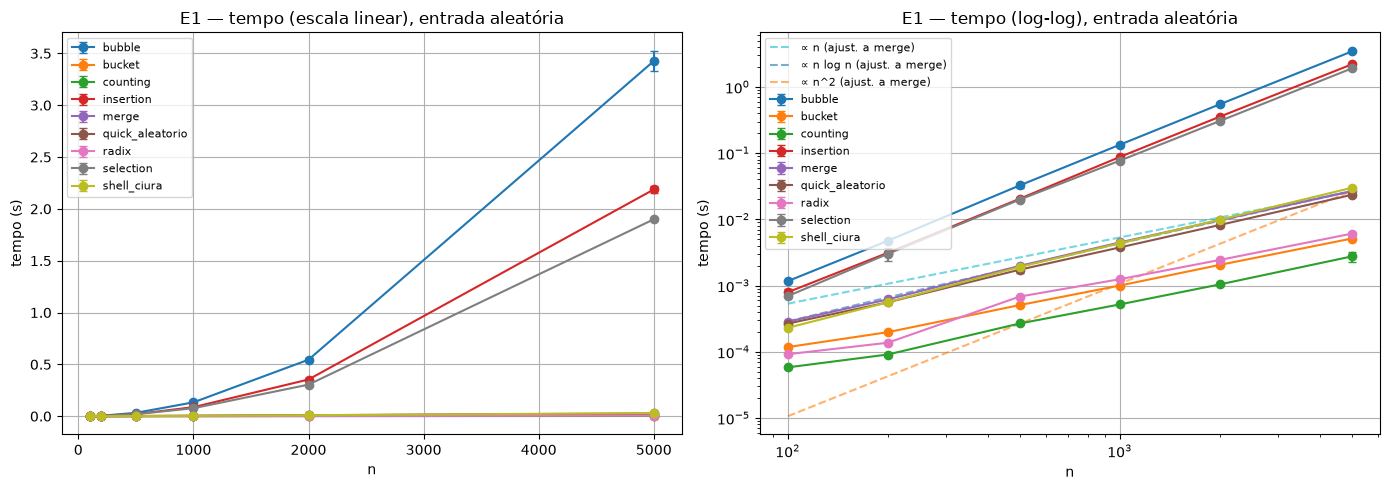

In [27]:
# Exemplo — G1: 9 algoritmos, entrada aleatória (linear e log-log)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_metrica(res_E1, "tempo", tipo="aleatoria", loglog=False, teoricas=None,
             titulo="E1 — tempo (escala linear), entrada aleatória", ax=axes[0])
plot_metrica(res_E1, "tempo", tipo="aleatoria", loglog=True, teoricas=("n", "n log n", "n^2"),
             ref="merge", titulo="E1 — tempo (log-log), entrada aleatória", ax=axes[1])
plt.tight_layout(); plt.show()

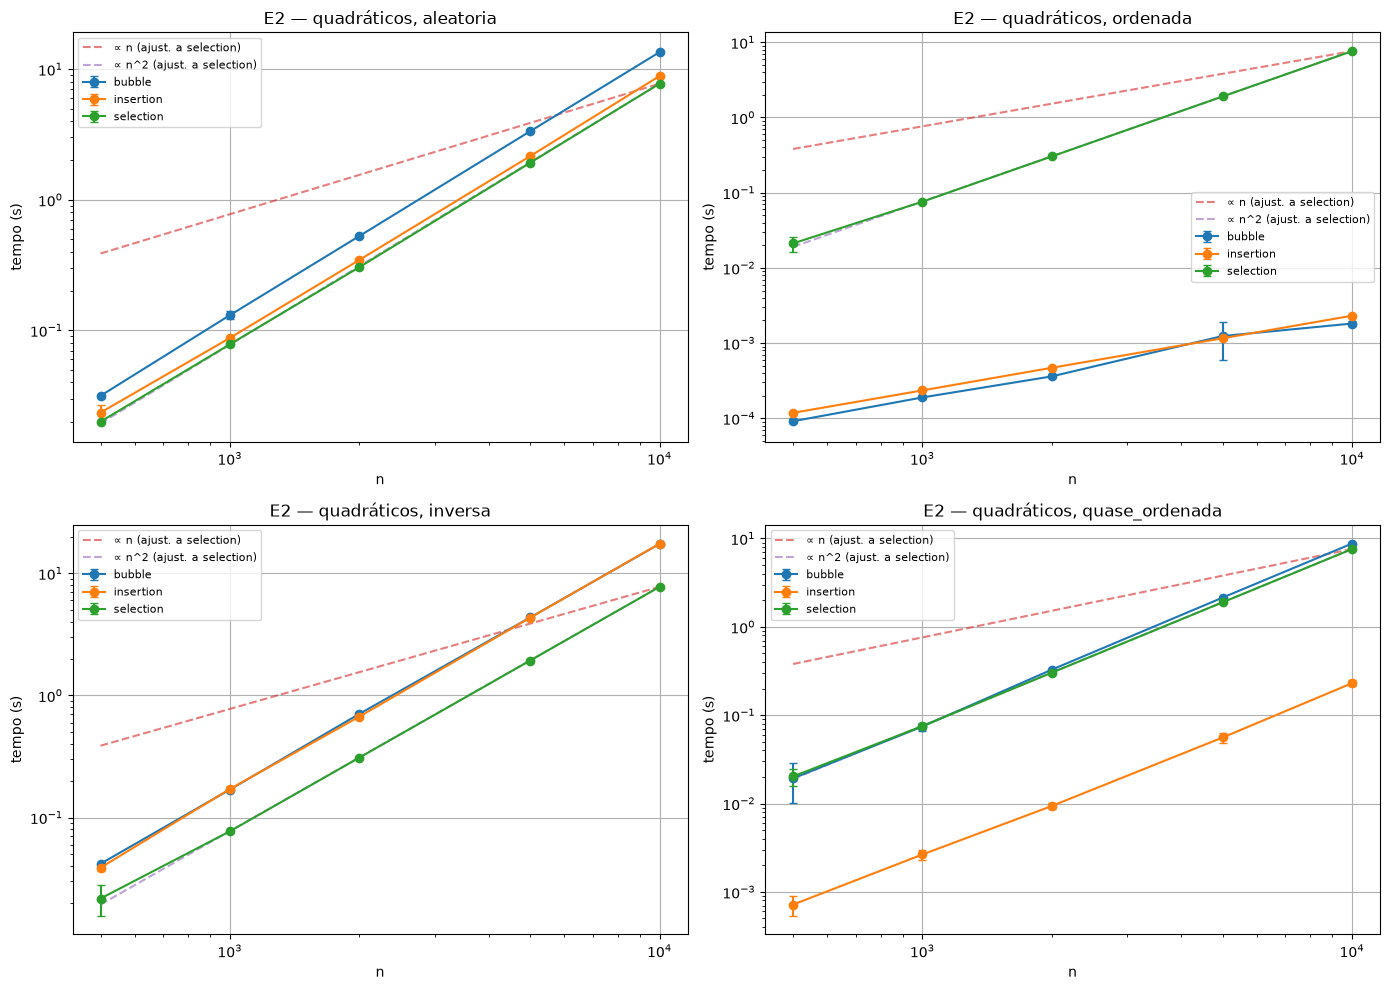

In [28]:
# Exemplo — G2: quadráticos em cada tipo de entrada
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, tipo in zip(axes.flat, TIPOS):
    plot_metrica(res_E2, "tempo", tipo=tipo, teoricas=("n", "n^2"), ref="selection",
                 titulo=f"E2 — quadráticos, {tipo}", ax=ax)
plt.tight_layout(); plt.show()

In [29]:
# Exemplo — Tabela T1: expoentes estimados
_nao_vazios = [r for r in [res_E1, res_E2, res_E3, res_E4, res_E5, res_E6] if not r.empty]
todos = pd.concat(_nao_vazios, ignore_index=True) if _nao_vazios else pd.DataFrame()
estimar_expoente(todos, "tempo", n_min=1_000)

,algoritmo,tipo,k,alpha,pontos
0,bubble,aleatoria,-1,2.011,4
1,bubble,inversa,-1,2.008,4
2,bubble,ordenada,-1,1.035,4
3,bubble,quase_ordenada,-1,2.075,4
4,bucket,aleatoria,-1,1.014,3
...,...,...,...,...,...
57,shell_knuth,quase_ordenada,-1,1.257,5
58,shell_shell,aleatoria,-1,1.233,5
59,shell_shell,inversa,-1,1.136,5
60,shell_shell,ordenada,-1,1.138,5


In [30]:
# Exemplo — Tabela T2: T(n)/(n log n) para o Merge Sort em entrada aleatória
razao_teorica(res_E3, "merge", "aleatoria", g="n log n", metrica="comp")

,n,comp_mean,comp/(n log n)
0,1000,8717.2,0.874713
1,3000,30948.2,0.893108
2,10000,120452.4,0.906495
3,30000,408559.2,0.915682
4,100000,1536260.8,0.924921


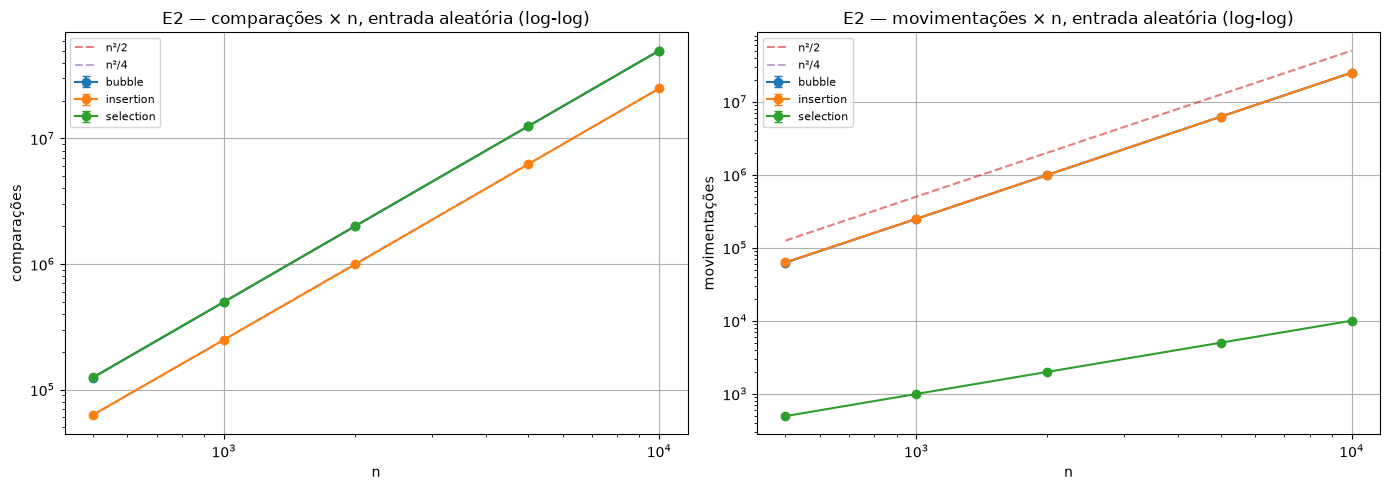

In [31]:
# G3 — E2: comparações e movimentações dos quadráticos (aleatória), com n²/2 e n²/4
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metrica, nome in [(axes[0], "comp", "comparações"), (axes[1], "trocas", "movimentações")]:
    plot_metrica(res_E2, metrica, tipo="aleatoria", teoricas=None, ax=ax,
                 titulo=f"E2 — {nome} × n, entrada aleatória (log-log)")
    ns = np.array(sorted(res_E2.n.unique()), dtype=float)
    ax.plot(ns, ns ** 2 / 2, "--", alpha=0.6, label="n²/2")
    ax.plot(ns, ns ** 2 / 4, "--", alpha=0.6, label="n²/4")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

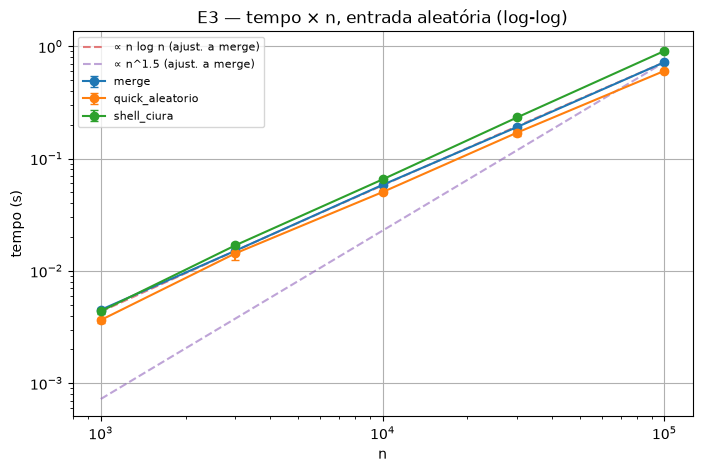

In [32]:
# G4 — E3: merge, quick_aleatorio e shell_ciura com as curvas n log n e n^1,5
plot_metrica(res_E3, "tempo", algoritmos=["merge", "quick_aleatorio", "shell_ciura"], tipo="aleatoria",
             teoricas=("n log n", "n^1.5"), ref="merge", titulo="E3 — tempo × n, entrada aleatória (log-log)")
plt.show()

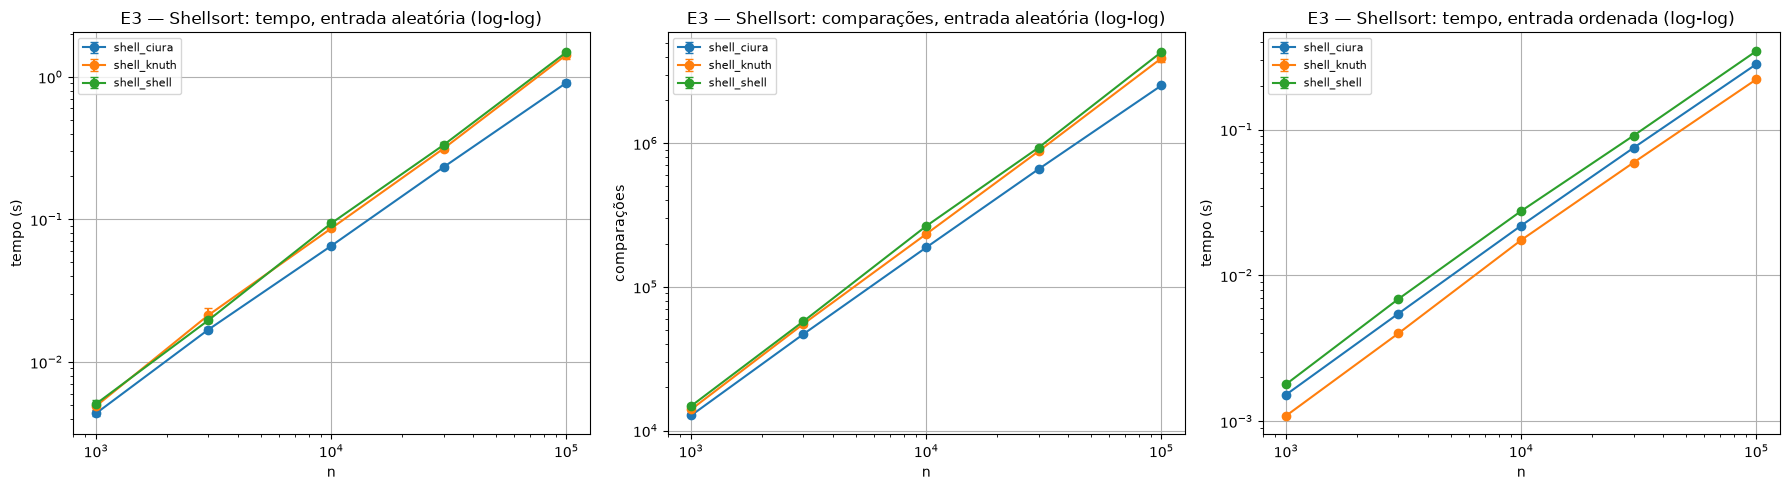

In [33]:
# G5 — E3: as três sequências de gaps do Shellsort (tempo e comparações)
SHELLS = ["shell_shell", "shell_knuth", "shell_ciura"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_metrica(res_E3, "tempo", algoritmos=SHELLS, tipo="aleatoria", teoricas=None,
             titulo="E3 — Shellsort: tempo, entrada aleatória (log-log)", ax=axes[0])
plot_metrica(res_E3, "comp", algoritmos=SHELLS, tipo="aleatoria", teoricas=None,
             titulo="E3 — Shellsort: comparações, entrada aleatória (log-log)", ax=axes[1])
plot_metrica(res_E3, "tempo", algoritmos=SHELLS, tipo="ordenada", teoricas=None,
             titulo="E3 — Shellsort: tempo, entrada ordenada (log-log)", ax=axes[2])
plt.tight_layout(); plt.show()

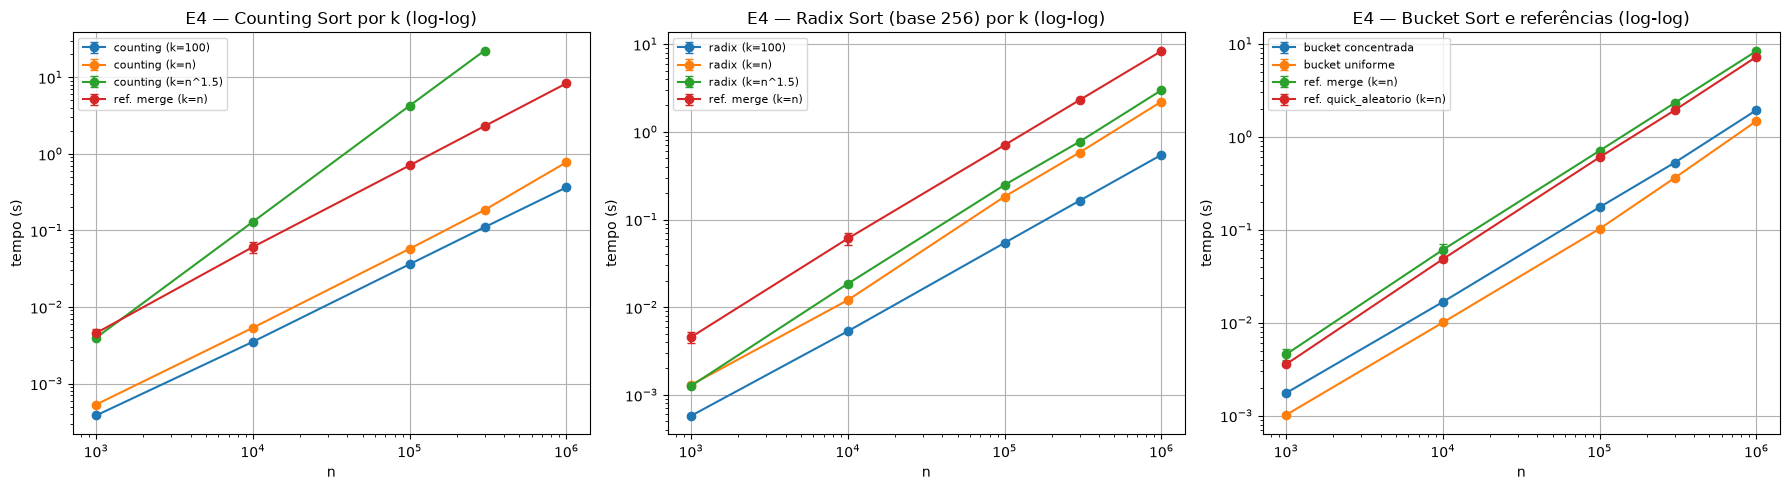

In [34]:
# G6 — E4: lineares com os três valores de k, com merge e quick como referência
# rótulo por configuração: o mesmo algoritmo aparece em várias chamadas do E4
# o prefixo "ref." põe as referências por último na legenda e mantém suas cores entre os painéis
g6 = res_E4.copy()
config = g6.experimento.str.replace("E4 ", "", regex=False)
g6["algoritmo"] = np.where(g6.algoritmo == "bucket", "bucket " + g6.tipo,
                  np.where(g6.algoritmo.isin(["merge", "quick_aleatorio"]), "ref. " + g6.algoritmo + " (" + config + ")",
                           g6.algoritmo + " (" + config + ")"))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_metrica(g6, "tempo", algoritmos=["counting (k=100)", "counting (k=n)", "counting (k=n^1.5)", "ref. merge (k=n)"],
             teoricas=None, titulo="E4 — Counting Sort por k (log-log)", ax=axes[0])
plot_metrica(g6, "tempo", algoritmos=["radix (k=100)", "radix (k=n)", "radix (k=n^1.5)", "ref. merge (k=n)"],
             teoricas=None, titulo="E4 — Radix Sort (base 256) por k (log-log)", ax=axes[1])
plot_metrica(g6, "tempo", algoritmos=["bucket uniforme", "bucket concentrada", "ref. merge (k=n)", "ref. quick_aleatorio (k=n)"],
             teoricas=None, titulo="E4 — Bucket Sort e referências (log-log)", ax=axes[2])
plt.tight_layout(); plt.show()

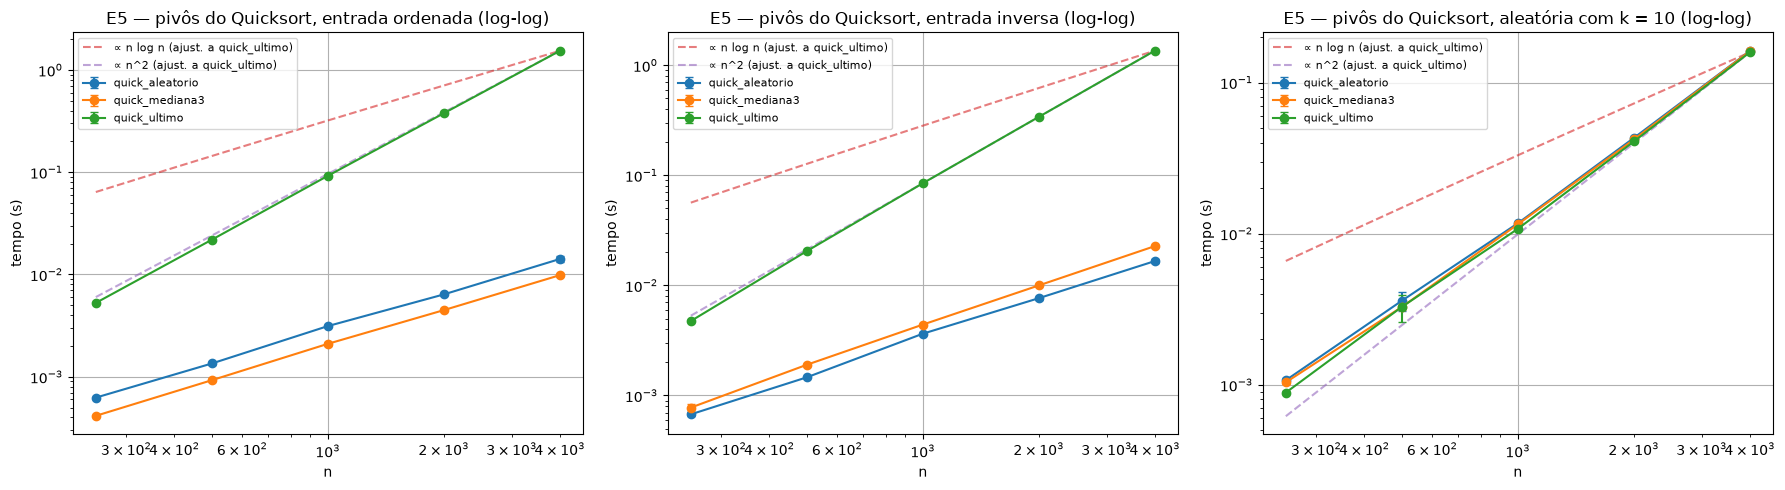

In [35]:
# G7 — E5: pivôs do Quicksort em entrada ordenada, inversa e com k = 10
PIVOS = ["quick_ultimo", "quick_aleatorio", "quick_mediana3"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, exp, tipo, nome in [(axes[0], "E5", "ordenada", "entrada ordenada"),
                            (axes[1], "E5", "inversa", "entrada inversa"),
                            (axes[2], "E5 k=10", "aleatoria", "aleatória com k = 10")]:
    plot_metrica(res_E5, "tempo", algoritmos=PIVOS, tipo=tipo, experimento=exp, teoricas=("n log n", "n^2"),
                 ref="quick_ultimo", titulo=f"E5 — pivôs do Quicksort, {nome} (log-log)", ax=ax)
plt.tight_layout(); plt.show()

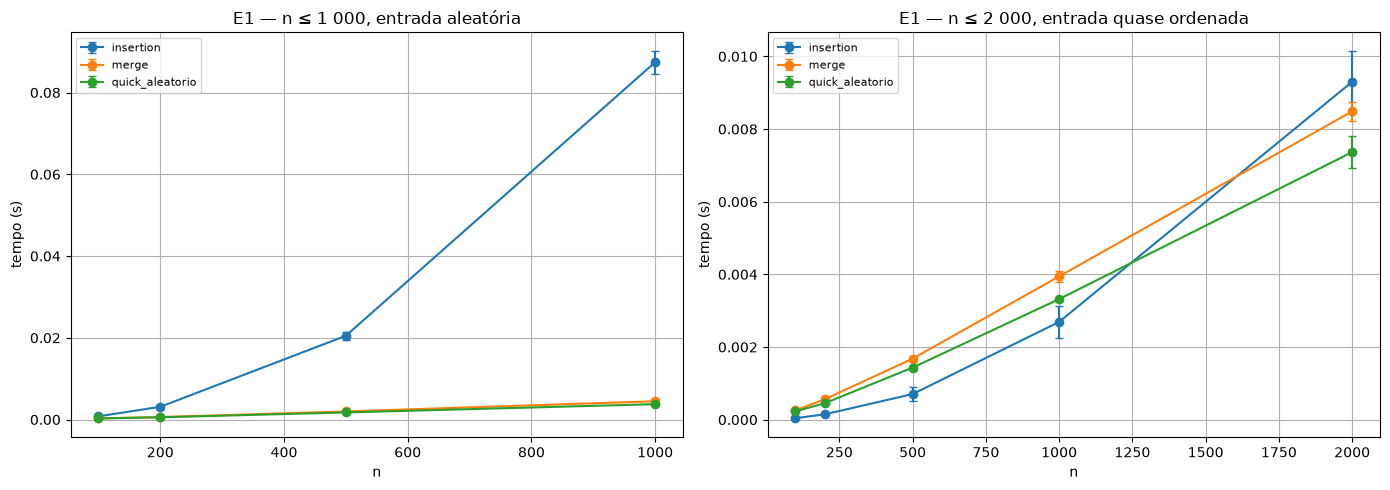

In [36]:
# G8 — E1: insertion × merge × quick em n pequeno
ALG_G8 = ["insertion", "merge", "quick_aleatorio"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_metrica(res_E1[res_E1.n <= 1_000], "tempo", algoritmos=ALG_G8, tipo="aleatoria", loglog=False, teoricas=None,
             titulo="E1 — n ≤ 1 000, entrada aleatória", ax=axes[0])
plot_metrica(res_E1[res_E1.n <= 2_000], "tempo", algoritmos=ALG_G8, tipo="quase_ordenada", loglog=False, teoricas=None,
             titulo="E1 — n ≤ 2 000, entrada quase ordenada", ax=axes[1])
plt.tight_layout(); plt.show()

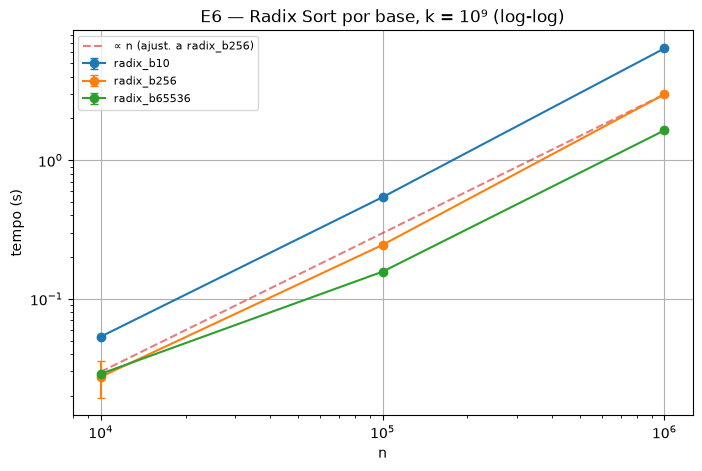

In [37]:
# Gráfico adicional — E6: efeito da base no Radix Sort
plot_metrica(res_E6, "tempo", teoricas=("n",), ref="radix_b256", titulo="E6 — Radix Sort por base, k = 10⁹ (log-log)")
plt.show()

In [38]:
# T1 — expoentes α do tempo por experimento, comparados com o esperado
# k recebe o nome do experimento: no E4, k varia com n e estimar_expoente separaria cada ponto
def alpha_esperado(linha):
    a, t, e = linha.algoritmo, linha.tipo, linha.experimento
    if a in ("bubble", "insertion"):
        return "1" if t == "ordenada" else "2"
    if a == "selection":
        return "2"
    if a.startswith("quick") and (e == "E5 k=10" or (a == "quick_ultimo" and t in ("ordenada", "inversa"))):
        return "2"
    if a == "merge" or a.startswith("quick"):
        return "≈ 1,1 (n log n)"
    if a.startswith("shell"):
        return "entre 1 e 1,5"
    if a == "counting" and e == "E4 k=n^1.5":
        return "1,5"
    return "1"

_nao_vazios = [r for r in [res_E1, res_E2, res_E3, res_E4, res_E5, res_E6] if not r.empty]
todos_exp = pd.concat(_nao_vazios, ignore_index=True)
T1 = estimar_expoente(todos_exp.assign(k=todos_exp.experimento), "tempo", n_min=1_000).rename(columns={"k": "experimento"})
if not T1.empty:
    T1["esperado"] = T1.apply(alpha_esperado, axis=1)
    T1 = T1[["experimento", "algoritmo", "tipo", "alpha", "esperado", "pontos"]]
T1

,experimento,algoritmo,tipo,alpha,esperado,pontos
0,E1,bubble,aleatoria,2.015,2,3
1,E2,bubble,aleatoria,2.015,2,4
2,E1,bubble,inversa,2.010,2,3
3,E2,bubble,inversa,2.008,2,4
4,E1,bubble,ordenada,0.994,1,3
...,...,...,...,...,...,...
93,E3,shell_knuth,quase_ordenada,1.257,"entre 1 e 1,5",5
94,E3,shell_shell,aleatoria,1.233,"entre 1 e 1,5",5
95,E3,shell_shell,inversa,1.136,"entre 1 e 1,5",5
96,E3,shell_shell,ordenada,1.138,"entre 1 e 1,5",5


In [39]:
# T2 — razões T(n)/g(n) para vários algoritmos
CASOS_T2 = [
    (res_E3, "merge",           "aleatoria", "n log n", "tempo", None),
    (res_E3, "merge",           "aleatoria", "n log n", "comp",  None),
    (res_E3, "quick_aleatorio", "aleatoria", "n log n", "comp",  None),
    (res_E3, "shell_ciura",     "aleatoria", "n^1.5",   "tempo", None),
    (res_E2, "insertion",       "aleatoria", "n^2",     "tempo", None),
    (res_E2, "selection",       "aleatoria", "n^2",     "comp",  None),
    (res_E4, "counting",        "aleatoria", "n",       "tempo", "E4 k=n"),
    (res_E4, "bucket",          "uniforme",  "n",       "tempo", "E4 bucket"),
]
for res, alg, tipo, g, metrica, exp in CASOS_T2:
    print(f"\n{alg} — {metrica}/({g}), entrada {tipo}" + (f", {exp}" if exp else ""))
    print(razao_teorica(res, alg, tipo, g=g, metrica=metrica, experimento=exp).to_string(index=False))


merge — tempo/(n log n), entrada aleatoria
     n  tempo_mean  tempo/(n log n)
  1000    0.004496     4.511510e-07
  3000    0.015094     4.355926e-07
 10000    0.058338     4.390352e-07
 30000    0.191028     4.281400e-07
100000    0.721992     4.346825e-07

merge — comp/(n log n), entrada aleatoria
     n  comp_mean  comp/(n log n)
  1000     8717.2        0.874713
  3000    30948.2        0.893108
 10000   120452.4        0.906495
 30000   408559.2        0.915682
100000  1536260.8        0.924921

quick_aleatorio — comp/(n log n), entrada aleatoria
     n  comp_mean  comp/(n log n)
  1000    10736.2        1.077306
  3000    40621.6        1.172265
 10000   153694.6        1.156667
 30000   553281.0        1.240039
100000  2063943.4        1.242618

shell_ciura — tempo/(n^1.5), entrada aleatoria
     n  tempo_mean  tempo/(n^1.5)
  1000    0.004365   1.380452e-07
  3000    0.016859   1.026000e-07
 10000    0.065254   6.525428e-08
 30000    0.232480   4.474070e-08
100000    0.909343

✍️ **Comentários sobre os resultados** (um parágrafo por gráfico/tabela, descrevendo o que se observa — sem ainda explicar as causas, o que fica para a Parte G):

G1. Na entrada aleatória, os algoritmos formam três faixas no gráfico log-log: os quadráticos, com inclinação próxima à de $n^2$; Shellsort, Merge e Quick, próximos de $n\log n$; e os lineares, os mais rápidos em todos os tamanhos. Na escala linear, os quadráticos se separam dos demais a partir de $n \approx 1\,000$. Em $n = 5\,000$, o Counting Sort levou 2,8 ms e o Bubble Sort 3,43 s.

G2. O Selection Sort segue $n^2$ nos quatro tipos de entrada, com tempos entre 7,59 s e 7,75 s em $n = 10^4$. Bubble e Insertion seguem $n$ na entrada ordenada (1,8 ms e 2,3 ms em $n = 10^4$) e $n^2$ nas demais. Na quase ordenada, o Insertion fica 33 a 38 vezes abaixo dos outros dois, mas paralelo a $n^2$. Na inversa, Bubble e Insertion levam mais que o dobro do tempo do Selection.

G3. O Selection faz exatamente $n(n-1)/2$ comparações, o Bubble praticamente o mesmo ($0{,}4998\,n^2$ em $n = 10^4$) e o Insertion cerca de $n^2/4$. Em movimentações, Bubble e Insertion coincidem em torno de $n^2/4$, e o Selection faz cerca de $n$ trocas.

G4. Merge e Quick aleatório acompanham a inclinação de $n\log n$; o Shellsort com Ciura é um pouco mais inclinado, mas fica bem abaixo de $n^{1{,}5}$. Em $n = 10^5$: 0,60 s (Quick), 0,72 s (Merge) e 0,91 s (Shellsort).

G5. Na entrada aleatória, a sequência de Ciura foi a melhor em tempo e em comparações (0,91 s e 2,53 milhões em $n = 10^5$), seguida de Knuth (1,43 s e 3,91 milhões) e de Shell (1,49 s e 4,32 milhões). Na entrada ordenada, Knuth ficou à frente (0,22 s, contra 0,28 s de Ciura e 0,35 s de Shell), e as comparações coincidiram exatamente com $\sum_h (n-h)$ sobre os *gaps* de cada sequência.

G6. O Counting Sort é linear com $k = 100$ e $k = n$ (0,37 s e 0,78 s em $n = 10^6$); com $k = n^{1{,}5}$, cresce com inclinação próxima de 1,5, passa o Merge a partir de $n = 10^4$ e foi interrompido em $n = 3\cdot10^5$ (22,3 s). O Radix varia bem menos com $k$ (0,55 s, 2,21 s e 2,99 s em $10^6$). O Bucket Sort é linear nas duas distribuições, com 1,47 s (uniforme) e 1,93 s (concentrada) em $10^6$. As referências levaram 8,3 s (Merge) e 7,2 s (Quick).

G7. Com pivô no último elemento, as entradas ordenada e inversa seguem $n^2$, com exatamente $n(n-1)/2$ comparações (1,54 s e 1,36 s em $n = 4\,000$). Os pivôs aleatório e mediana de 3 seguem $n\log n$ (de 9,9 ms a 22,8 ms); a mediana de 3 é a mais rápida na ordenada e a mais lenta na inversa. Com $k = 10$, as três estratégias praticamente coincidem (159 a 162 ms) e seguem $n^2$.

G8. Na entrada aleatória, o Insertion Sort já é o mais lento dos três em $n = 100$ (0,79 ms, contra 0,29 ms do Merge e 0,27 ms do Quick), sem cruzamento dentro da faixa. Na quase ordenada, ele é o mais rápido até $n = 1\,000$ e o mais lento em $n = 2\,000$, com cruzamento em torno de $n \approx 1\,250$ (Quick) e $n \approx 1\,600$ (Merge).

E6 (gráfico adicional). Com $k = 10^9$, o Radix fez 9, 4 e 2 passadas nas bases 10, 256 e 65 536, com 6,39 s, 2,98 s e 1,64 s em $n = 10^6$. Em $n = 10^4$, a base 256 foi a mais rápida (27,4 ms, contra 28,8 ms da base 65 536 e 53,5 ms da base 10).

T1. Os quadráticos ficaram entre 2,00 e 2,07, exceto Bubble e Insertion na entrada ordenada (1,03 e 0,99). Merge e Quick (aleatório e mediana de 3) ficaram entre 1,08 e 1,18, e o Shellsort entre 1,08 e 1,26. Os lineares ficaram entre 0,99 e 1,05 com $k$ fixo ou proporcional a $n$; o Counting com $k = n^{1{,}5}$ chegou a 1,51, o Radix com $k = n$ e $k = n^{1{,}5}$ a 1,09 e 1,12, e o Radix com base 65 536 ficou em 0,88. O Quick com pivô no último elemento chegou a 2,03 (ordenada) e 1,99 (inversa), e os três pivôs ficaram entre 1,89 e 1,94 com $k = 10$.

T2. As razões do Merge ($T/(n\log_2 n)$ entre $4{,}28\cdot10^{-7}$ e $4{,}51\cdot10^{-7}$) e do Insertion ($T/n^2$ entre $8{,}6\cdot10^{-8}$ e $9{,}4\cdot10^{-8}$) ficaram estáveis, e a razão de comparações do Selection chega a 0,5000. As razões de comparações do Merge e do Quick crescem devagar com $n$ (de 0,875 a 0,925 e de 1,08 a 1,24). No Shellsort com Ciura, $T/n^{1{,}5}$ cai cerca de cinco vezes na faixa. No Counting e no Bucket, o tempo por elemento cresce 35% e 44% entre $n = 10^5$ e $10^6$.

<a id="parteG"></a>
# Parte G — Discussão dos resultados ✍️

Responda a cada questão **com base nos seus dados**, citando o gráfico ou a tabela correspondente (ex.: "como se vê no G8…"). Respostas genéricas, sem referência aos experimentos, serão consideradas incompletas. Recomendamos de 1 a 3 parágrafos por questão.

### G.1 Quadráticos × $O(n \log n)$ para $n$ pequeno
*a) Em quais tamanhos e tipos de entrada algum algoritmo quadrático foi **mais rápido** que Merge Sort ou Quicksort? Estime o ponto de cruzamento $n_0$.*

Na entrada aleatória, nenhum: em $n = 100$, o menor tamanho do E1, o Insertion Sort já levou 0,79 ms, contra 0,29 ms do Merge e 0,27 ms do Quick (G8). O cruzamento fica abaixo de 100, e o modelo do item b o estima em $n_0 \approx 25$. Na entrada ordenada, Bubble e Insertion foram mais rápidos que todos os comparativos em todos os tamanhos (G2 e E1). Na quase ordenada, o Insertion venceu Merge e Quick até $n = 1\,000$ e perdeu em $n = 2\,000$; pela interpolação, $n_0 \approx 1\,250$ contra o Quick e $n_0 \approx 1\,600$ contra o Merge (G8).

*b) Explique o fenômeno usando as **constantes ocultas** da notação assintótica: modele $T_{ins}(n) \approx a\,n^2$ e $T_{merge}(n) \approx b\,n\log_2 n$, estime $a$ e $b$ a partir dos seus dados e calcule o $n_0$ previsto. Ele bate com o observado?*

Com os tempos de $n = 100$ na entrada aleatória, $a = 0{,}794\text{ ms}/100^2 \approx 7{,}9\cdot10^{-8}$ s e $b = 0{,}286\text{ ms}/(100\log_2 100) \approx 4{,}3\cdot10^{-7}$ s. Igualando, $n_0 = (b/a)\log_2 n_0 \approx 5{,}4\log_2 n_0$, que dá $n_0 \approx 25$ (23 com o Quick no lugar do Merge; entre 20 e 25 ajustando em $n = 200$ ou 500). Isso é coerente com o que se vê no G8, onde o cruzamento fica abaixo de 100, mas o E1 não tem tamanhos menores para confirmar o valor. As constantes vêm principalmente do número de operações: em Python instrumentado, cada comparação ou movimentação custou de 155 a 225 ns em todos os algoritmos, e em $n = 100$ o Insertion faz cerca de $n^2/2 \approx 5\,000$ operações, contra cerca de 1 300 do Merge, que ainda paga recursão e cópias para o vetor auxiliar.

*c) Com base nisso, justifique por que implementações reais (ex.: Timsort, *introsort*) usam Insertion Sort para subvetores pequenos. **(Opcional, +5 pontos bônus):** implemente um Merge Sort híbrido que usa `insertion_sort_intervalo` para subvetores com tamanho $\le L$, teste $L \in \{4, 8, 16, 32, 64\}$ e reporte o melhor $L$.*

Abaixo de algumas dezenas de elementos, o Insertion Sort faz menos trabalho por elemento e não tem recursão, e isso compensa o crescimento quadrático. Por isso Timsort e *introsort* trocam para ele nos subvetores pequenos. O Merge Sort híbrido (item opcional) não foi implementado.

### G.2 Impacto da escolha do pivô no Quicksort
*a) Descreva o comportamento de `quick_ultimo` em entradas ordenadas e inversas. O expoente $\alpha$ estimado é compatível com a recorrência $T(n) = T(n-1) + \Theta(n)$?*

Nas duas entradas, o `quick_ultimo` fez exatamente $n(n-1)/2$ comparações em todos os tamanhos (G7), com $\alpha = 2{,}03$ e $1{,}99$ no E3 e $2{,}03$ e $2{,}00$ no E5 (T1). É o que a recorrência prevê, $\Theta(n^2)$: na ordenada, o pivô é sempre o máximo, e uma das partes fica vazia; na inversa, o pivô é o mínimo, e a troca final leva o máximo para o fim do subvetor, de modo que as partições alternam entre mínimo e máximo, sempre com uma parte vazia. No E3, a combinação foi interrompida pelo limite de tempo depois de $n = 10^4$ (ordenada, 9,7 s) e em $n = 3\cdot10^4$ (inversa, 77,5 s numa única execução).

*b) Por que o pivô aleatório torna o pior caso **improvável**, mas não **impossível**? Qual a diferença entre "caso médio sobre as entradas" e "tempo esperado sobre as escolhas aleatórias do algoritmo"?*

O pior caso continua possível: basta o sorteio escolher um extremo do subvetor em praticamente todas as partições. Só que a probabilidade disso cai muito depressa com $n$. No caso médio sobre as entradas, o algoritmo é determinístico, e a média supõe uma distribuição para as entradas; uma entrada ruim continua sempre ruim. No tempo esperado sobre as escolhas do algoritmo, a garantia vale para qualquer entrada fixa, e a média é sobre os sorteios. As comparações do Quick aleatório ficaram a até 2,3% do valor esperado $2(n+1)H_n - 4n$ (153 695 contra 155 772 em $n = 10^4$). Como a semente do pivô é fixa (0), cada entrada recebe sempre a mesma sequência de pivôs.

*c) O que aconteceu com os três pivôs quando $k = 10$ (muitos repetidos)? Explique pela partição de Lomuto.*

As três estratégias degradaram igualmente para perto de $n^2$ ($\alpha$ entre 1,89 e 1,94, G7 e T1). A partição de Lomuto usada manda para a esquerda os elementos $\le$ pivô. Um subvetor formado só por cópias de um valor é então particionado com uma parte vazia a cada passo, e cada um dos $k$ valores, com cerca de $n/k$ cópias, custa cerca de $(n/k)^2/2$. O total é cerca de $n^2/(2k)$: 800 000 comparações para $n = 4\,000$, contra 814 mil a 826 mil medidas. Nenhuma escolha de pivô ajuda, porque dentro desses blocos todos os candidatos são iguais.

*d) Houve diferença de desvio padrão entre as estratégias? Por quê?*

Não de forma sistemática. As entradas ordenada e inversa são iguais em todas as *seeds*, e a semente do pivô aleatório é fixa, então as contagens tiveram desvio zero nas três estratégias. A variação de tempo nessas entradas, com coeficiente de 0,1% a 8%, é só ruído de medição. Com $k = 10$, a variação vem das diferentes entradas e é parecida nas três.

### G.3 Efeito da sequência de gaps no Shellsort
*a) Compare as três sequências em tempo e comparações. Qual foi a melhor? Quais foram os $\alpha$ estimados?*

Na entrada aleatória, a de Ciura foi a melhor em tempo e em comparações (0,91 s e 2,53 milhões em $n = 10^5$), seguida de Knuth (1,43 s e 3,91 milhões) e de Shell (1,49 s e 4,32 milhões), com $\alpha$ de 1,16, 1,22 e 1,23 (G5 e T1). Era o esperado, porque Ciura escolheu seus incrementos experimentalmente para minimizar as comparações em entradas aleatórias. Nas entradas ordenada e inversa, Knuth foi a mais rápida. Na ordenada, cada passada custa exatamente $n - h$ comparações, e vence quem tem menos *gaps*: Knuth, limitada a $h < n/3$, usa 10 em $n = 10^5$, contra 13 de Ciura e 16 de Shell.

*b) Relacione com os limites teóricos conhecidos (Shell: $\Theta(n^2)$ no pior caso; Knuth: $O(n^{3/2})$).*

O $\alpha$ de Knuth (1,22) fica abaixo de 1,5, compatível com o limite superior $O(n^{3/2})$. O de Shell (1,23) fica longe de 2, o que também é esperado: o pior caso dessa sequência exige $n$ potência de 2 e uma entrada construída para ele, e os experimentos usam entradas aleatórias em tamanhos que não são potências de 2. Na T2, $T/n^{1{,}5}$ do Shellsort com Ciura cai cerca de cinco vezes, o que põe seu crescimento abaixo de $n^{1{,}5}$ na faixa medida.

*c) O Shellsort foi competitivo com Merge Sort e Quicksort na sua faixa de $n$? E em entradas ordenadas/quase ordenadas?*

Foi. Na entrada aleatória, a versão de Ciura foi 1,3 a 1,5 vez mais lenta que Merge e Quick em $n = 10^5$ (G4), e a diferença tende a crescer, porque seu $\alpha$ é maior. Na entrada ordenada, Knuth e Ciura foram mais rápidas que Merge e Quick aleatório em todos os tamanhos do E3, e na inversa a partir de $n = 10^4$. Na quase ordenada, Ciura (0,67 s) ficou entre o Merge (0,63 s) e o Quick com mediana de 3 (0,98 s).

### G.4 Quando os algoritmos lineares são vantajosos?
*a) Com $k = 100$, $k = n$ e $k = n^{1,5}$, como se comportou o Counting Sort? Em que ponto o termo $k$ passa a dominar $\Theta(n + k)$? Houve problema de **memória**?*

Com $k = 100$ e $k = n$, o Counting foi linear ($\alpha$ = 1,00 e 1,05) e o mais rápido de todos (G6). Com $k = n^{1{,}5}$, o termo $k$ domina desde o primeiro tamanho: em $n = 10^3$, $k \approx 32\,n$ e o tempo já é 7,5 vezes o do caso $k = n$; o $\alpha$ medido (1,51) é o do próprio $k$. A combinação foi interrompida em $n = 3\cdot10^5$ pelo limite de tempo (22,3 s), e não por falta de memória. Pelas nossas contas, o vetor de contagem nesse tamanho, com $1{,}6\cdot10^8$ posições, ocupa alguns gigabytes. Com $n = 10^6$ ($k = 10^9$), seriam dezenas de gigabytes, acima dos 16 GB da máquina. A memória não foi medida.

*b) O Radix Sort foi afetado por $k$ da mesma forma? Relacione com $d = \lceil \log_b k \rceil$. Qual base foi melhor no E6 e por quê?*

Não. O custo do Radix cresce com o número de passadas $d$, ou seja, com $\log_b k$, e não com $k$. Em $n = 10^6$, os tempos de 0,55 s, 2,21 s e 2,99 s correspondem a 1, 3 e 4 passadas (G6). No E6, a base 65 536 foi a melhor nos tamanhos grandes (2 passadas, 1,64 s em $10^6$), e a base 10 a pior (9 passadas, 6,39 s). Em $n = 10^4$, a base 256 venceu, porque o vetor de contagem da base 65 536 é maior que o próprio $n$, e o termo $b$ de $\Theta(d(n+b))$ passa a pesar. A melhor base fica perto de $n$, como diz o resultado clássico.

*c) Compare o Bucket Sort com distribuição uniforme e concentrada. O resultado confirma a análise $\Theta(n)$ no caso médio e $\Theta(n^2)$ no pior caso?*

O caso uniforme confirma $\Theta(n)$ ($\alpha = 1{,}05$). O concentrado também foi linear ($\alpha = 1{,}01$), só que mais lento: 1,3 a 1,7 vez o tempo e 6 vezes as comparações (G6). A teoria também prevê isso, porque a distribuição concentrada põe 90% dos valores em 10% dos baldes, cerca de 9 elementos por balde, e esse número não cresce com $n$. O pior caso $\Theta(n^2)$ exige que uma fração crescente dos elementos caia num mesmo balde, e isso não foi testado.

*d) Em Python, os lineares foram de fato mais rápidos que Merge/Quick para $n$ grande? Discuta o papel das constantes, da alocação de memória e do fato de que "linear" pressupõe hipóteses sobre a entrada.*

Foram. Em $n = 10^6$, o Counting ($k = n$) levou 0,78 s, o Bucket uniforme 1,47 s e o Radix 2,21 s, contra 7,2 s do Quick e 8,3 s do Merge. A exceção foi o Counting com $k = n^{1{,}5}$, até 10 vezes mais lento que o Merge. A instrumentação pesa mais nos comparativos, que fazem uma chamada de função por operação, enquanto boa parte do trabalho dos lineares não é instrumentada. A alocação de memória pesa nos lineares quando $k$ ou $n$ crescem: o tempo por elemento do Counting e do Bucket subiu 35% e 44% entre $10^5$ e $10^6$ (T2). E a vantagem some quando a hipótese sobre a entrada falha, como no caso $k = n^{1{,}5}$.

*e) Por que não faz sentido comparar **número de comparações** entre algoritmos comparativos e não comparativos? Que métrica é mais justa?*

Counting e Radix fazem zero comparações, mas leem e escrevem cada elemento várias vezes e percorrem o vetor de contagem, e nada disso entra em `comp`. Métricas mais justas são o tempo, as movimentações, que os dois grupos têm, ou a contagem de todas as operações elementares, incluindo os acessos por índice.

### G.5 Teoria × prática (síntese)
*a) Os expoentes estimados (Tabela T1) ficaram próximos dos esperados? Aponte as maiores discrepâncias e proponha explicações (faixa de $n$ pequena, overhead do interpretador, cache, alocação de memória, instrumentação).*

Ficaram, na maior parte (T1): 2,00 a 2,07 nos quadráticos, cerca de 1 em Bubble e Insertion na entrada ordenada, 1,08 a 1,11 em Merge e Quick aleatório (o esperado para $n\log n$ nessa faixa é cerca de 1,1) e cerca de 1 nos lineares sob suas hipóteses. As maiores discrepâncias foram estas:
- Na entrada quase ordenada, Bubble e Insertion tiveram $\alpha \approx 2$. O gerador troca cerca de $n/100$ pares sorteados, a uma distância média de $n/3$, o que cria cerca de $n^2/150$ inversões. As 652 828 comparações do Insertion em $n = 10^4$ (cerca de $n^2/153$) confirmam a conta.
- O Radix ficou acima de 1 com $k = n$ e $k = n^{1{,}5}$ (1,09 e 1,12), porque o número de passadas cresce com $n$, e abaixo de 1 com base 65 536 (0,88), porque até $n = 10^4$ o vetor de contagem é maior que $n$.
- O tempo por elemento do Counting e do Bucket cresceu a partir de $10^5$ (T2). A explicação mais provável é a memória e o cache: o processador tem 25 MB de cache L3, e uma lista de $10^6$ referências já ocupa 8 MB. Isso não foi medido.

*b) Por que **contagens de operações** são mais estáveis que **tempo** entre seeds? Qual das duas métricas é melhor para validar a análise assintótica? E para decidir qual algoritmo usar em um sistema real?*

Para uma dada entrada, as contagens são determinísticas. Tiveram desvio zero nas entradas ordenada e inversa e deram valores idênticos nas duas execuções completas que fizemos. O tempo inclui ruído do sistema operacional, do cache e da memória. Para validar a análise assintótica, as contagens são a melhor métrica: reproduziram exatamente $n(n-1)/2$ e $\sum_h (n-h)$, e quase exatamente $n^2/(2k)$ e $2(n+1)H_n - 4n$. Para escolher um algoritmo num sistema real, o tempo informa mais, porque inclui o custo de cada operação e o trabalho não contado. Em $n = 10^5$, por exemplo, o Quick aleatório fez 34% mais comparações que o Merge e ainda assim foi 16% mais rápido, porque moveu menos elementos e não copia para um vetor auxiliar.

*c) Monte uma tabela de **recomendação**: para cada cenário — (i) $n$ pequeno; (ii) dados quase ordenados; (iii) necessidade de estabilidade; (iv) memória extra restrita; (v) inteiros em intervalo pequeno; (vi) pior caso garantido — qual algoritmo você escolheria e por quê?*

| Cenário | Escolha | Justificativa |
|---|---|---|
| (i) $n$ pequeno | Insertion Sort até algumas dezenas de elementos; Shellsort (Ciura) por volta de $n = 100$ | $n_0$ estimado entre 23 e 25; em $n = 100$, o Shellsort foi o comparativo mais rápido (E1) |
| (ii) Dados quase ordenados | Insertion Sort se as inversões forem poucas e locais; senão, Quick aleatório ou Shellsort | linear na entrada ordenada; com inversões a longa distância, só compensou até $n \approx 10^3$ (G8) |
| (iii) Estabilidade | Merge Sort; Counting ou Radix para inteiros | estáveis por construção (testes da Parte D) |
| (iv) Pouca memória extra | Shellsort ou Quicksort aleatório | *in-place*, pilha $O(\log n)$ no Quick; competitivos com o Merge (G4) |
| (v) Inteiros em intervalo pequeno | Counting Sort ($k \lesssim n$); Radix com base grande para $k$ grande | os mais rápidos do trabalho; Radix pouco sensível a $k$ (G6) |
| (vi) Pior caso garantido | Merge Sort | $\Theta(n\log n)$ em qualquer entrada; menor variação entre tipos (de 0,56 a 0,72 s em $10^5$) |

<a id="parteH"></a>
# Parte H — Relatório ✍️

O relatório é escrito **neste mesmo notebook**, nas células abaixo, e reaproveita o conteúdo das partes anteriores (você pode referenciar tabelas e gráficos já gerados, sem duplicá-los). Extensão recomendada do texto próprio do relatório: **equivalente a 6 a 12 páginas**, sem contar código.

### Requisitos de cada seção

| Seção | O que deve conter |
|---|---|
| **1. Introdução** | Contexto e importância da ordenação; objetivo do trabalho; perguntas que o trabalho responde; organização do relatório. |
| **2. Fundamentação teórica** | Descrição sucinta de cada algoritmo; tabela consolidada de complexidades (Parte E); recorrências e aplicação do Teorema Mestre; limite inferior $\Omega(n \log n)$ para ordenação por comparação e as hipóteses dos lineares. |
| **3. Metodologia** | Ambiente (CPU, RAM, sistema operacional, versão do Python — use a célula de apoio abaixo); decisões de implementação (partição usada, base do Radix, gaps, o que foi contado como comparação/troca); geração das entradas; faixas de $n$ e justificativa; seeds e número de repetições; como o tempo foi medido; ameaças à validade (ruído, overhead da instrumentação). Deve ser detalhada o suficiente para que **outra pessoa reproduza** os experimentos. |
| **4. Resultados** | Gráficos e tabelas obrigatórios, com legendas numeradas e descrição objetiva do que mostram. |
| **5. Análise crítica** | A discussão da Parte G organizada em texto corrido; confronto com as previsões da Parte E; limitações do estudo. |
| **6. Conclusões** | Principais achados em poucas frases; recomendações práticas; possíveis trabalhos futuros (ex.: Heapsort, Timsort, versões iterativas, outras linguagens). |
| **Referências** | Livros, artigos e sites consultados, em formato ABNT ou similar. Sugestões: CORMEN et al., *Algoritmos: Teoria e Prática*; ZIVIANI, *Projeto de Algoritmos*; SEDGEWICK & WAYNE, *Algorithms*; CIURA, M. *Best Increments for the Average Case of Shellsort* (2001). |

## H.1 Introdução

Ordenar uma coleção de elementos segundo uma relação de ordem é um dos problemas mais estudados da Ciência da Computação. Além de ser útil por si só (relatórios, classificações, *rankings*), a ordenação é etapa de preparação para outros algoritmos: a busca binária exige dados ordenados, a eliminação de duplicatas e a junção de tabelas em bancos de dados se tornam mais simples e eficientes, e muitos algoritmos geométricos e de grafos começam ordenando a entrada (CORMEN et al., 2012; ZIVIANI, 2007).

Apesar de o problema ser simples de enunciar, não existe um "melhor" algoritmo de ordenação em sentido absoluto. Os algoritmos clássicos diferem no custo assintótico (quadrático, $n\log n$ ou linear), no uso de memória (*in-place* ou com vetor auxiliar), na estabilidade (preservar a ordem relativa de chaves iguais) e nas hipóteses sobre a entrada (apenas comparações, inteiros em intervalo limitado ou números reais uniformemente distribuídos). Além disso, a notação assintótica esconde constantes que, em tamanhos moderados de entrada, podem inverter a ordem de desempenho prevista pela teoria. Por isso, o estudo de ordenação precisa comparar a análise teórica com medições.

**Objetivo.** Este trabalho implementa nove algoritmos de ordenação (Bubble Sort, Selection Sort, Insertion Sort, Shellsort, Merge Sort, Quicksort, Counting Sort, Radix Sort e Bucket Sort), instrumentados para contar comparações e movimentações de elementos, e compara seu comportamento teórico e experimental em diferentes tamanhos e tipos de entrada. Também são estudadas as variantes de três algoritmos: as sequências de *gaps* do Shellsort (Shell, Knuth e Ciura), as estratégias de pivô do Quicksort (último elemento, aleatório e mediana de três) e a base do Radix Sort.

**Perguntas que o trabalho responde.**

1. Os tempos e as contagens de operações medidos seguem as classes de complexidade previstas pela análise (quadrática, $n\log n$, linear)? Os expoentes estimados nos gráficos log-log concordam com os esperados?
2. Para entradas pequenas, algoritmos quadráticos podem ser mais rápidos que os $O(n\log n)$? A partir de que tamanho $n_0$ o cruzamento ocorre, e como as constantes ocultas o explicam?
3. Qual o impacto da escolha do pivô no Quicksort, em especial para entradas ordenadas, inversas e com muitos valores repetidos?
4. Como a sequência de *gaps* altera o desempenho do Shellsort?
5. Em que condições os algoritmos lineares (Counting, Radix e Bucket) compensam, e o que acontece quando suas hipóteses sobre a entrada são violadas?
6. Contagem de operações e tempo de execução são métricas equivalentes? Qual delas é mais adequada para validar a teoria e qual para escolher um algoritmo em um sistema real?

**Organização do relatório.** A Seção H.2 apresenta a fundamentação teórica: descrição dos algoritmos, recorrências, aplicação do Teorema Mestre, o limite inferior para ordenação por comparação e a tabela consolidada de complexidades. A Seção H.3 descreve a metodologia (ambiente, decisões de implementação, geração das entradas, experimentos e medição de tempo). A Seção H.4 apresenta os resultados; a Seção H.5, a análise crítica; e a Seção H.6, as conclusões. Por fim, listam-se as referências.

## H.2 Fundamentação teórica

### H.2.1 Conceitos e notação

Seja $v$ um vetor com $n$ elementos. Dizemos que o par de índices $(i, j)$, com $i < j$, é uma *inversão* se $v[i] > v[j]$. Um vetor ordenado tem $0$ inversões; um vetor inverso tem $\binom{n}{2} = \frac{n(n-1)}{2}$; um vetor aleatório tem, em média, $\frac{n(n-1)}{4}$. O número de inversões $I$ é uma medida do "grau de desordem" e aparece diretamente no custo de vários algoritmos.

Um algoritmo é *estável* se elementos com chaves iguais mantêm, na saída, a mesma ordem relativa que tinham na entrada. É *in-place* se usa apenas $O(1)$ de memória extra (admitindo-se, por convenção, a pilha de recursão em $O(\log n)$). É *comparativo* se obtém a ordem exclusivamente comparando pares de elementos.

Em todo o trabalho, "comparações" são comparações entre elementos da entrada, e não entre índices, e "trocas" são movimentações de elementos: cada *swap* conta uma unidade e cada atribuição que escreve um elemento em uma posição também conta uma unidade.

### H.2.2 Algoritmos quadráticos

Os três algoritmos desta família mantêm uma região ordenada que cresce uma posição por iteração do laço externo. Como cada iteração pode custar $\Theta(n)$, o custo típico é $\Theta(n^2)$.

**Bubble Sort.** Percorre o vetor comparando pares adjacentes e trocando-os quando estão fora de ordem; ao fim da passada $i$, os $i$ maiores elementos estão em suas posições finais. Com a parada antecipada (encerrar se uma passada não troca nada), o melhor caso é $\Theta(n)$. Cada troca de vizinhos elimina exatamente uma inversão, logo o número de trocas é igual a $I$. No pior caso (vetor inverso) faz $\frac{n(n-1)}{2}$ comparações e a mesma quantidade de trocas. É estável e *in-place*.

**Selection Sort.** Na iteração $i$, seleciona o menor elemento de $v[i..n-1]$ e o coloca na posição $i$ com uma única troca. Faz sempre $\sum_{i=0}^{n-2}(n-1-i) = \frac{n(n-1)}{2}$ comparações, independentemente da entrada, e no máximo $n-1$ trocas. É *in-place*, mas não é estável: a troca a longa distância pode inverter a ordem de elementos iguais.

**Insertion Sort.** Pega o próximo elemento (a chave) e o insere na posição correta da região já ordenada, deslocando os maiores para a direita. O número de deslocamentos é exatamente $I$, e o custo é $\Theta(n + I)$: linear para vetores ordenados ou quase ordenados e quadrático para vetores inversos ou aleatórios. É estável e *in-place*. Essa propriedade é explorada pelo Shellsort e pelo Bucket Sort.

### H.2.3 Algoritmos subquadráticos

**Teorema Mestre.** Para $T(n) = a\,T(n/b) + f(n)$, com $a \ge 1$ e $b > 1$, compara-se $f(n)$ com $n^{\log_b a}$: (1) se $f(n) = O(n^{\log_b a - \varepsilon})$ para algum $\varepsilon > 0$, então $T(n) = \Theta(n^{\log_b a})$; (2) se $f(n) = \Theta(n^{\log_b a})$, então $T(n) = \Theta(n^{\log_b a}\log n)$; (3) se $f(n) = \Omega(n^{\log_b a + \varepsilon})$ para algum $\varepsilon > 0$ e $a f(n/b) \le c f(n)$ para algum $c < 1$, então $T(n) = \Theta(f(n))$ (CORMEN et al., 2012). O teorema não se aplica a recorrências que não têm essa forma, como $T(n) = T(n-1) + \Theta(n)$ ou $T(n) = T(n/10) + T(9n/10) + \Theta(n)$; nesses casos usam-se expansão ou árvore de recursão.

**Shellsort.** Generaliza o Insertion Sort: ordena por inserção os elementos separados por uma distância $h$ (*gap*), para uma sequência decrescente de *gaps* terminando em $h = 1$ (SHELL, 1959). Gaps grandes movem elementos por longas distâncias; quando se chega a $h = 1$, o vetor já está quase ordenado e a passada final é barata. Foram usadas três sequências:

| Sequência | Definição | Pior caso conhecido |
|---|---|---|
| Shell (1959) | $\lfloor n/2\rfloor, \lfloor n/4\rfloor, \dots, 1$ | $\Theta(n^2)$ |
| Knuth (1973) | $h_1 = 1$, $h_{k+1} = 3h_k + 1$, enquanto $h < n/3$ | $O(n^{3/2})$ |
| Ciura (2001) | $1, 4, 10, 23, 57, 132, 301, 701, 1750$, estendida por $\lfloor 2{,}25\,h\rfloor$ | desconhecido |

Com $n$ potência de 2, todos os *gaps* maiores que 1 da sequência de Shell são pares, e as posições pares e ímpares só interagem na passada final. Se as posições pares guardam os $n/2$ menores valores e as ímpares os $n/2$ maiores, todas as passadas anteriores mantêm essa separação, e a passada final, com $h = 1$, tem $\Theta(n^2)$ deslocamentos: é o pior caso $\Theta(n^2)$ (KNUTH, 1998). O limite $O(n^{3/2})$ para a sequência de Knuth é devido a Knuth e Pratt (KNUTH, 1998; PRATT, 1979). A sequência de Ciura foi obtida empiricamente e é considerada a melhor na prática (CIURA, 2001), mas não há limite de pior caso demonstrado. A análise do caso médio é problema em aberto para a maioria das sequências. O Shellsort é *in-place* e não é estável.

**Merge Sort.** Divide o vetor ao meio, ordena recursivamente cada metade e as intercala em tempo linear, usando um vetor auxiliar. A recorrência é $T(n) = 2T(n/2) + \Theta(n)$. Com $a = 2$, $b = 2$ e $f(n) = \Theta(n)$, temos $n^{\log_b a} = n = \Theta(f(n))$, e o caso 2 do Teorema Mestre dá $T(n) = \Theta(n\log n)$. Como a divisão não depende dos valores e a intercalação percorre sempre os $n$ elementos, melhor, médio e pior caso coincidem. Usa $\Theta(n)$ de memória extra e é estável, desde que, em caso de empate, o elemento da metade esquerda seja o primeiro a ser copiado.

**Quicksort.** Escolhe um pivô, particiona o vetor (menores à esquerda, maiores à direita) e ordena recursivamente as duas partes (HOARE, 1962). Usamos a partição de Lomuto: o pivô é colocado na última posição e um laço move para a esquerda os elementos $\le$ pivô. As recorrências são:

- *Melhor caso* (partições equilibradas): $T(n) = 2T(n/2) + \Theta(n) = \Theta(n\log n)$, pelo caso 2 do Teorema Mestre.
- *Pior caso* (uma parte vazia): $T(n) = T(n-1) + \Theta(n)$. O Teorema Mestre não se aplica, pois o subproblema diminui por uma constante e não por um fator. Por expansão, $T(n) = c\sum_{k=1}^{n}k + T(0) = \Theta(n^2)$. Com pivô no último elemento, isso ocorre em vetores ordenados, inversos e com todos os elementos iguais.
- *Partição fixa $1:9$:* $T(n) = T(n/10) + T(9n/10) + \Theta(n)$. Pela árvore de recursão, cada nível custa no máximo $cn$ e há entre $\log_{10}n$ e $\log_{10/9}n$ níveis, de modo que $T(n) = \Theta(n\log n)$. Qualquer proporção constante de divisão preserva $n\log n$.
- *Caso médio*: com pivô uniformemente aleatório, o número esperado de comparações é $\Theta(n\log n)$. A prova usa o fato de que dois elementos $z_i < z_j$ são comparados se, e somente se, o primeiro pivô escolhido entre $z_i, \dots, z_j$ for um deles, o que ocorre com probabilidade $2/(j-i+1)$ (CORMEN et al., 2012). Para a partição usada, que compara $m-1$ elementos com o pivô num subvetor de tamanho $m$, o número esperado de comparações $C(n)$ satisfaz $C(n) = n - 1 + \frac{2}{n}\sum_{q=0}^{n-1} C(q)$, com $C(0) = C(1) = 0$, cuja solução é $C(n) = 2(n+1)H_n - 4n \approx 2n\ln n \approx 1{,}39\,n\log_2 n$, em que $H_n = \sum_{k=1}^{n}1/k$.

Foram implementadas três estratégias de pivô (último, aleatório e mediana de três). A recursão é feita apenas na menor das duas partes, tratando-se a maior com um laço, o que limita a profundidade da pilha a $\lfloor\log_2 n\rfloor$ mesmo no pior caso (tempo $\Theta(n^2)$ inalterado). O Quicksort é *in-place* (usa a pilha) e não é estável.

### H.2.4 Limite inferior e algoritmos lineares

**Limite inferior para ordenação por comparação.** Todo algoritmo que ordena apenas por comparações pode ser descrito por uma árvore de decisão binária cujas folhas são as permutações de saída. Para ordenar corretamente toda entrada, a árvore precisa de pelo menos $n!$ folhas; como uma árvore binária de altura $h$ tem no máximo $2^h$ folhas, $h \ge \log_2 n!$. Como $n! \ge (n/2)^{n/2}$,
$$h \;\ge\; \frac{n}{2}\log_2\frac{n}{2} = \Omega(n\log n).$$
Portanto nenhum algoritmo puramente comparativo tem pior caso melhor que $\Omega(n\log n)$ (CORMEN et al., 2012). Os algoritmos a seguir escapam desse limite porque não comparam elementos entre si: usam os valores como índices ou para calcular posições. Em troca, exigem hipóteses sobre a entrada.

**Counting Sort.** Hipótese: chaves inteiras em $[0, k)$. Conta as ocorrências de cada valor, transforma as contagens em somas prefixas e percorre a entrada de trás para frente, colocando cada elemento em sua posição final; esse percurso reverso torna o algoritmo estável. Custo $\Theta(n + k)$ de tempo e de espaço, linear quando $k = O(n)$. Se $k$ é muito maior que $n$ (por exemplo $k = n^2$), o termo $k$ domina e a memória pode se tornar proibitiva.

**Radix Sort (LSD).** Hipótese: inteiros não negativos com no máximo $d$ dígitos na base $b$. Ordena do dígito menos significativo para o mais significativo, usando a cada passada o Counting Sort com $k = b$, que precisa ser estável para preservar a ordem obtida nas passadas anteriores. Custo $\Theta(d(n + b))$, com $d = \lfloor\log_b M\rfloor + 1$ para o maior valor $M$. Bases maiores reduzem o número de passadas, mas aumentam o vetor de contagem de cada passada. Na implementação deste trabalho, os valores são deslocados pelo mínimo $m$ antes da extração dos dígitos (o dígito de $x$ na passada $i$ é $\lfloor (x - m)/b^i\rfloor \bmod b$). Com isso, números negativos também são aceitos e o número de passadas passa a depender da amplitude: $d = \lfloor\log_b (M - m)\rfloor + 1$, e nenhuma passada é feita se todos os valores forem iguais.

**Bucket Sort.** Hipótese: reais em $[0,1)$ distribuídos uniformemente. Distribui os $n$ elementos em $n$ baldes (o elemento $x$ vai para o balde $\lfloor nx\rfloor$), ordena cada balde com Insertion Sort e concatena. Com $n_i$ o tamanho do balde $i$, o custo é $\Theta(n) + \sum_i O(n_i^2)$. Sob distribuição uniforme, $n_i \sim \text{Binomial}(n, 1/n)$ e $E[n_i^2] = \text{Var}[n_i] + E[n_i]^2 = (1 - 1/n) + 1 = 2 - 1/n$, de modo que o caso médio é $\Theta(n)$. Se todos os elementos caírem no mesmo balde, o custo é $\Theta(n^2)$.

### H.2.5 Tabela consolidada de complexidades

| Algoritmo | Melhor | Médio | Pior | Espaço extra | Estável | *In-place* | Recorrência / observação |
|---|---|---|---|---|---|---|---|
| Bubble Sort | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $O(1)$ | Sim | Sim | trocas $= I$ (inversões) |
| Insertion Sort | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $O(1)$ | Sim | Sim | custo $\Theta(n + I)$ |
| Selection Sort | $\Theta(n^2)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $O(1)$ | Não | Sim | $\frac{n(n-1)}{2}$ comparações sempre; $\le n-1$ trocas |
| Shellsort (Ciura) | $\Theta(n\log n)$ | em aberto | desconhecido | $O(1)$ | Não | Sim | passadas de inserção com *gaps* decrescentes |
| Merge Sort | $\Theta(n\log n)$ | $\Theta(n\log n)$ | $\Theta(n\log n)$ | $\Theta(n)$ | Sim | Não | $2T(n/2) + \Theta(n)$; Mestre, caso 2 |
| Quicksort (aleatório) | $\Theta(n\log n)$ | $\Theta(n\log n)$ (esperado) | $\Theta(n^2)$ | $O(\log n)$ (pilha) | Não | Sim | pior: $T(n-1) + \Theta(n)$ (Mestre não se aplica) |
| Counting Sort | $\Theta(n+k)$ | $\Theta(n+k)$ | $\Theta(n+k)$ | $\Theta(n+k)$ | Sim | Não | inteiros em $[0,k)$ |
| Bucket Sort | $\Theta(n)$ | $\Theta(n)$ (uniforme) | $\Theta(n^2)$ | $\Theta(n)$ | Sim | Não | reais em $[0,1)$ uniformes |
| Radix Sort | $\Theta(d(n+b))$ | $\Theta(d(n+b))$ | $\Theta(d(n+b))$ | $\Theta(n+b)$ | Sim | Não | $d = \lfloor\log_b (M - m)\rfloor + 1$ ($M$ e $m$: maior e menor valor) |

## H.3 Metodologia

### H.3.1 Ambiente

Todos os experimentos foram executados em uma única máquina, descrita abaixo. As informações foram obtidas no servidor com os comandos `uname`, `lshw` e `nproc` e com as versões informadas pelo próprio Python.

| Item | Valor |
|---|---|
| Sistema operacional | Debian GNU/Linux 13 (trixie), kernel 6.12.113+deb13-amd64 |
| Processador | Intel Xeon E5-2630 v4 @ 2,20 GHz (Broadwell-EP, turbo até 3,1 GHz; caches L1 640 KiB, L2 2,5 MiB, L3 25 MiB) |
| Núcleos lógicos | 20 (10 físicos com Hyper-Threading) |
| Memória RAM | 16 GiB DDR4 2400 MHz (um único módulo, canal único) |
| Python | 3.13.5 |
| numpy / pandas / matplotlib | 2.5.4 / 3.1.0 / 3.11.2 |

### H.3.2 Decisões de implementação

Todos os algoritmos foram implementados do zero, sem qualquer rotina de ordenação pronta (`list.sort`, `sorted`, `heapq`, `bisect`, `numpy.sort`). A função `sorted()` é usada apenas nos testes de corretude, para gerar o gabarito. Todos recebem um vetor `v` e um objeto contador `c`, e devolvem o vetor ordenado em ordem não decrescente.

**Instrumentação.** Um objeto `Contador` guarda `comp` (comparações) e `trocas` (movimentações). A contagem é feita por funções auxiliares: `menor` e `menor_ou_igual` incrementam `comp` a cada comparação entre elementos; `trocar` incrementa `trocas` em 1 por *swap*; `escrever` incrementa `trocas` em 1 por atribuição de um elemento a uma posição. Comparações de índices (por exemplo `j >= 0`, `i < n`) não são contadas. Para os algoritmos não comparativos, `comp` fica em zero (exceto no Bucket Sort, que usa Insertion Sort nos baldes). A tabela resume o que foi contado:

| Algoritmo | Comparações (`comp`) | Movimentações (`trocas`) |
|---|---|---|
| Bubble | `v[j+1] < v[j]` | cada *swap* |
| Selection | `v[j] < v[m]` na busca do mínimo | cada *swap* (só se $m \neq i$) |
| Insertion | `chave < v[j-1]`, apenas quando `j > inicio` | cada deslocamento e a escrita da chave na posição final, que só ocorre se a chave saiu do lugar |
| Shellsort | `chave < v[j-h]`, apenas quando `j >= h` | cada deslocamento e a escrita da chave na posição final, que só ocorre se a chave saiu do lugar |
| Merge | `aux[j] < aux[i]` na intercalação | cada escrita em `v[k]`; a cópia para `aux` não é contada |
| Quicksort | `v[j] <= pivô` e, em `mediana3`, as comparações de escolha do pivô | cada *swap* (troca do pivô para o fim, da partição e do pivô final); trocas de um elemento com ele mesmo não são feitas nem contadas |
| Counting | nenhuma | cada escrita no vetor de saída |
| Radix | nenhuma | cada escrita no vetor de saída, em cada passada |
| Bucket | as do Insertion Sort nos baldes | cada inserção em um balde, as movimentações do Insertion Sort nos baldes e cada escrita na saída |

**Algoritmos quadráticos.** O Bubble Sort usa a parada antecipada. O Selection Sort só troca quando o índice do mínimo difere de $i$. O Insertion Sort foi implementado por intervalo (`insertion_sort_intervalo(v, inicio, fim, c)`, com `fim` inclusivo), para ser reaproveitado no Bucket Sort.

**Shellsort.** A função recebe a sequência de *gaps* como parâmetro. Foram implementadas a sequência de Shell ($\lfloor n/2\rfloor, \lfloor n/4\rfloor, \dots, 1$), a de Knuth ($h_{k+1} = 3h_k + 1$, enquanto $h < n/3$, em ordem decrescente) e a de Ciura, com os termos empíricos $1, 4, 10, 23, 57, 132, 301, 701, 1750$ estendidos por $\lfloor 2{,}25\,h\rfloor$ enquanto o termo for menor que $n$. A versão principal é a de Ciura, definida pelo enunciado como padrão por ser a sequência com melhor desempenho médio conhecido em entradas aleatórias (CIURA, 2001), o que os experimentos confirmaram (Seção H.5.3).

**Merge Sort.** Versão *top-down*, com um único vetor auxiliar de tamanho $n$ alocado uma vez e passado às chamadas recursivas. Os índices `lo` e `hi` são inclusivos: o meio é $\lfloor(lo + hi)/2\rfloor$ e as metades são `v[lo..mid]` e `v[mid+1..hi]`. Em caso de empate na intercalação, o elemento da metade esquerda é copiado primeiro (comparação estrita `aux[j] < aux[i]`), o que mantém a estabilidade.

**Quicksort.** Partição de Lomuto com o pivô na última posição e índices `lo` e `hi` inclusivos; elementos $\le$ pivô vão para a esquerda. Três estratégias de pivô, aplicadas trocando o pivô escolhido com `v[hi]` antes da partição: `"ultimo"` (índice `hi`), `"aleatorio"` (índice sorteado uniformemente em `[lo, hi]` com um `random.Random` próprio, criado com semente fixa 0 a cada chamada do algoritmo, o que torna a sequência de pivôs reproduzível para uma mesma entrada) e `"mediana3"` (mediana entre `v[lo]`, `v[(lo + hi) // 2]` e `v[hi]`, com 2 ou 3 comparações contadas). Trocas de um elemento com ele mesmo (pivô já em `v[hi]`, `i = j` na partição ou pivô final já na posição) não são feitas nem contadas. Para controlar a profundidade de recursão, o algoritmo chama a recursão apenas na menor partição e trata a maior com um laço, o que garante profundidade $O(\log n)$ mesmo no pior caso. Não foi implementada a partição de três vias; por isso, vetores com muitos valores repetidos degradam o Quicksort com Lomuto, e esse efeito é analisado no experimento E5. A versão principal é a de pivô aleatório.

**Counting Sort.** Usa $k = \max(v) + 1$, percorre a entrada de trás para frente para ser estável e devolve uma nova lista. Foi implementada também a variante `counting_sort_por_chave(v, k, chave, c)`, que ordena de forma estável por `chave(x)`, usada pelo Radix Sort.

**Radix Sort.** LSD, com uma passada do Counting Sort por dígito. A base padrão é $b = 2^8 = 256$; a base é parâmetro, e no experimento E6 comparam-se as bases $10$, $256$ e $65\,536$. Antes das passadas, os valores são deslocados pelo mínimo $m$ (dígito $\lfloor (x - m)/b^i\rfloor \bmod b$), o que permite valores negativos; o número de passadas é $d = \lfloor\log_b (M - m)\rfloor + 1$, em que $M$ é o maior valor. Nas entradas dos experimentos, $m$ é próximo de 0, e $d$ coincide com $\lfloor\log_b M\rfloor + 1$.

**Bucket Sort.** Cria $n$ baldes; o elemento $x \in [0,1)$ vai para o balde $\min(\lfloor n\cdot x\rfloor, n-1)$, limite que protege contra arredondamento; cada balde é ordenado com `insertion_sort_intervalo`; os baldes são concatenados em ordem, escrevendo de volta em `v`.

### H.3.3 Verificação de corretude

Antes de qualquer experimento, todos os algoritmos passam por uma bateria de testes com casos-limite (vetor vazio, de um elemento, de dois elementos, com repetidos, já ordenado, inverso, aleatório, com valores grandes e com muitos valores repetidos), comparando a saída com o gabarito `sorted(entrada)`. Além disso, foram acrescentados três testes próprios. (i) Estabilidade: os algoritmos estáveis (Bubble, Insertion, Merge, Counting, Radix nas bases 256 e 10, e Bucket) ordenam 300 elementos com muitas chaves repetidas, cada um rotulado com sua posição original, e verifica-se que elementos de mesma chave mantêm a ordem dos rótulos. (ii) Vetor já ordenado: todos os algoritmos devem devolver o vetor inalterado, com e sem valores repetidos; para $n = 200$ sem repetidos conferem-se ainda as contagens exatas: $n-1$ comparações e nenhuma movimentação no Bubble e no Insertion Sort, $n(n-1)/2$ comparações e nenhuma troca no Selection Sort, nenhuma movimentação no Shellsort (nas três sequências) e $n(n-1)/2$ comparações no Quicksort com pivô no último elemento, que é o seu pior caso. (iii) Casos de borda com vetores pequenos: 26 vetores de até quatro elementos (vazio, um elemento, dois elementos nas duas ordens, todos iguais, valores distantes como $[1000, 0, 999]$ e todas as permutações de $[0, 1, 2]$ e de $[0, 1, 1, 2]$) são ordenados por todos os algoritmos e comparados com `sorted()`; para o Bucket Sort os valores são divididos por 1001, para ficarem em $[0, 1)$. Durante os experimentos, a saída de cada execução também é conferida com `esta_ordenado`, fora da janela de medição de tempo.

### H.3.4 Geração das entradas

Para inteiros, as entradas são geradas por `gerar_inteiros(tipo, n, seed, k)` com valores em $[0, k)$ (por padrão $k = n$), em quatro tipos: aleatória, ordenada, inversa e quase ordenada (vetor ordenado com cerca de 1% de pares trocados aleatoriamente). Os tipos ordenada e inversa são construídos diretamente, sem usar `sorted()`. Para o Bucket Sort, `gerar_floats(n, seed, distribuicao)` produz reais em $[0,1)$ com distribuição uniforme ou concentrada (90% dos valores em $[0, 0{,}1)$).

**Reprodutibilidade.** Cada geração usa um gerador próprio `random.Random(seed)`, de modo que o mesmo par (tipo, $n$, *seed*) sempre produz o mesmo vetor. Usam-se 5 *seeds* (11, 22, 33, 44 e 55). Para cada algoritmo, o vetor de cada combinação (tipo, $n$, *seed*) é gerado a partir da mesma *seed* e o algoritmo recebe uma cópia dele, de modo que todos ordenam exatamente a mesma entrada.

### H.3.5 Experimentos e faixas de $n$

As faixas de $n$ foram calibradas pela complexidade de cada grupo de algoritmos, para que cada experimento termine em tempo razoável e ainda cubra pelo menos uma ordem de grandeza (necessário para enxergar o crescimento em escala log-log).

| Exp. | Algoritmos | Tipos de entrada | Valores de $n$ | *Seeds* |
|---|---|---|---|---|
| E1 | os 9 (versões principais) | aleatória, ordenada, inversa, quase ordenada (Bucket: uniforme) | 100, 200, 500, 1 000, 2 000, 5 000 | 5 |
| E2 | Bubble, Insertion, Selection | os 4 tipos | 500, 1 000, 2 000, 5 000, 10 000 | 5 |
| E3 | Shell (3 *gaps*), Merge, Quick (3 pivôs) | os 4 tipos | $10^3$, $3\cdot10^3$, $10^4$, $3\cdot10^4$, $10^5$ | 5 |
| E4 | Counting, Radix, Bucket; Merge e Quick (aleatório) como referência | aleatória com $k \in \{100, n, n^{1{,}5}\}$ (Bucket: uniforme e concentrada; referências: $k = n$) | $10^3$, $10^4$, $10^5$, $3\cdot10^5$, $10^6$ | 5 |
| E5 | Quick (último, aleatório, mediana de 3) | ordenada, inversa, aleatória com $k = 10$ | 250, 500, 1 000, 2 000, 4 000 | 5 |
| E6 | Radix (bases 10, 256, 65 536) | aleatória com $k = 10^9$ | $10^4$, $10^5$, $10^6$ | 5 |

Os experimentos foram executados no modo completo, com as faixas da tabela acima. Os tamanhos opcionais do E3 ($n = 3\cdot10^5$ e $10^6$) não foram incluídos.

### H.3.6 Medição de tempo

O tempo é medido com `time.perf_counter()` (relógio de alta resolução), envolvendo apenas a chamada do algoritmo: a geração do vetor, a cópia e a verificação ficam de fora. O coletor de lixo (*garbage collector*) é executado antes (`gc.collect()`) e desativado durante a medição (`gc.disable()`), sendo reativado em seguida, para reduzir o ruído. Durante o modo completo, nenhum outro programa foi executado na máquina. Para reduzir a variação do relógio do processador, o *governor* de frequência foi fixado em `performance` e o turbo foi desligado (`intel_pstate/no_turbo = 1`), de modo que o processador trabalhou na frequência base de 2,2 GHz. O notebook foi executado pela linha de comando com o `papermill`, dentro de uma sessão `tmux`, preso ao núcleo lógico 2 com `taskset -c 2`; o núcleo irmão desse núcleo no *Hyper-Threading* foi desligado durante a execução, para que nenhum outro processo dividisse o mesmo núcleo físico. Para cada (algoritmo, tipo, $n$) registra-se uma linha por *seed* com o tempo, as comparações e as movimentações, e os resultados são salvos em arquivos CSV (`resultados_E1.csv` a `resultados_E6.csv`). A função `resumir` calcula a média e o desvio padrão entre as *seeds*.

**Execução anterior, descartada.** Uma primeira execução completa usou uma versão do executor em que a linha `saida = f(entrada, c)` ficava entre as duas leituras de `perf_counter()`. Ao ser reatribuída, a variável `saida` liberava a lista devolvida pela execução anterior, e essa liberação entrava no tempo medido; na primeira *seed* de um algoritmo que vinha depois de outro com $n = 10^6$, isso tornou a medição até 34 vezes mais lenta. O executor foi corrigido com `saida = None` antes da medição, e os experimentos foram executados novamente; os resultados deste relatório vêm dessa segunda execução.

**Mecanismo de proteção.** Cada execução tem um `tempo_limite` (20 s por padrão, 60 s no E2 e 15 s nas referências Merge e Quick do E4). Se uma execução (ou a média das *seeds*) ultrapassa o limite, ou se a previsão para o próximo tamanho, supondo crescimento quadrático a partir do tamanho anterior, ultrapassa 4 vezes o limite, os tamanhos maiores são pulados para aquele algoritmo e tipo. Na execução, três combinações foram interrompidas. (i) `quick_ultimo` em entrada ordenada no E3, após $n = 10^4$: a média foi de 9,7 s, e a previsão quadrática para $n = 3\cdot10^4$ (cerca de 88 s) ultrapassou 4 vezes o limite de 20 s. (ii) `quick_ultimo` em entrada inversa no E3, em $n = 3\cdot10^4$: a média em $n = 10^4$ foi de 8,5 s, a previsão para $3\cdot10^4$ (cerca de 77 s) ficou abaixo de 80 s e esse tamanho foi executado; a primeira execução levou 77,5 s e ultrapassou o limite, de modo que esse tamanho tem uma única *seed*. Os dois casos são coerentes com o custo $\Theta(n^2)$ desse pior caso. (iii) Counting Sort com $k = n^{1{,}5}$ no E4, após $n = 3\cdot10^5$ ($k \approx 1{,}6\cdot10^8$): a primeira execução levou 22,3 s e ultrapassou o limite, de modo que esse tamanho tem uma única *seed* e $n = 10^6$ ($k = 10^9$) não foi executado. Nenhuma outra combinação foi interrompida.

### H.3.7 Análise dos resultados

Os resultados são analisados com tabelas e gráficos de tempo, comparações e movimentações em função de $n$, em escala linear e log-log, com barras de erro de um desvio padrão e curvas teóricas ($n$, $n\log n$, $n^{1{,}5}$, $n^2$) escaladas para coincidir com o último ponto medido de um algoritmo de referência. Dois instrumentos quantitativos complementam a inspeção visual. O primeiro é o expoente estimado $\alpha$: ajusta-se por mínimos quadrados uma reta a $\log T$ versus $\log n$, usando as médias com $n \ge 1000$ de cada (algoritmo, tipo, $k$), reunindo os pontos de todos os experimentos, desde que haja pelo menos três tamanhos; a inclinação estima o expoente em $T(n)\approx c\,n^{\alpha}$. Para $n\log n$ espera-se $\alpha$ ligeiramente acima de 1 (da ordem de $1 + 1/\ln n$ numa faixa limitada). O segundo é a razão $T(n)/g(n)$: se $T(n) = \Theta(g(n))$, ela deve se estabilizar à medida que $n$ cresce, um teste mais convincente do que a semelhança visual entre curvas.

### H.3.8 Ameaças à validade

- A chamada de funções auxiliares a cada comparação ou movimentação acrescenta um custo aproximadamente constante por operação. Isso altera as constantes, mas não a ordem de crescimento, e todos os algoritmos pagam esse custo; contudo, ele penaliza mais os algoritmos comparativos (que contam muito) do que os não comparativos, o que exagera a vantagem dos lineares.
- O Python é interpretado, e cada operação elementar custa dezenas de nanossegundos; os resultados absolutos não se transferem para linguagens compiladas.
- Tempos abaixo de aproximadamente 1 ms são muito ruidosos. O ruído do sistema operacional, o cache e o gerenciamento de memória afetam as medições, e o uso de 5 *seeds* dá apenas uma estimativa grosseira da variabilidade. As contagens de comparações e movimentações, por serem determinísticas para uma dada entrada, são muito mais estáveis que o tempo.
- As faixas de $n$ foram calibradas para o tempo de execução em Python; para $n$ pequeno, termos de ordem inferior e constantes podem mascarar o comportamento assintótico, e os expoentes estimados são aparentes.
- A partição de Lomuto degrada com valores repetidos, e a escolha de contar ou não as cópias para o vetor auxiliar do Merge Sort altera as movimentações reportadas; ambas as decisões estão documentadas na Seção H.3.2.
- Os resultados refletem um único ambiente de hardware e software.

### H.3.9 Como reproduzir

Com Python 3.10 ou superior e as bibliotecas `numpy`, `pandas` e `matplotlib`, basta abrir este notebook (`TP_Algoritmos_de_Ordenacao.ipynb`), executar *Kernel → Restart & Run All* e aguardar o término dos experimentos. Pela linha de comando, o mesmo resultado é obtido com `papermill TP_Algoritmos_de_Ordenacao.ipynb TP_executado.ipynb --log-output`. Como toda aleatoriedade vem de `random.Random(seed)`, com as *seeds* fixas acima na geração das entradas e a semente 0 no pivô aleatório do Quicksort, as contagens de comparações e movimentações são reproduzidas exatamente; os tempos variam ligeiramente conforme a máquina.

## H.4 Resultados

Esta seção descreve os resultados da execução completa (Seção H.3), sem ainda explicar suas causas, o que fica para a Seção H.5. Todos os números vêm dos arquivos `resultados_E1.csv` a `resultados_E6.csv`. Salvo indicação em contrário, cada ponto é a média das 5 *seeds*, e as barras de erro representam um desvio padrão. Nos gráficos log-log, as curvas tracejadas cinzas são curvas teóricas multiplicadas por uma constante para coincidir com o último ponto de um algoritmo de referência; a comparação se faz pela inclinação delas. As Figuras 1 a 8 mostram os mesmos dados dos gráficos G1 a G8 da Parte F, e a Figura 9 os do gráfico adicional do E6, redesenhados a partir dos CSVs com legendas numeradas.

### H.4.1 Visão geral (E1)

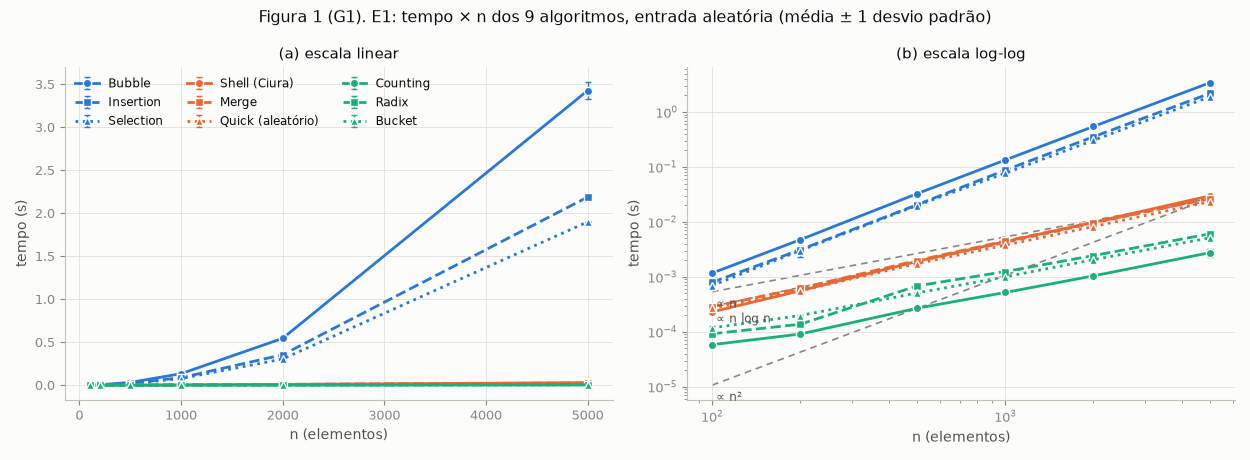

A Figura 1 mostra o tempo dos nove algoritmos em entrada aleatória. Na escala linear (a), os três quadráticos se separam dos demais a partir de $n \approx 1\,000$, e as outras seis curvas ficam praticamente sobre o eixo. Na escala log-log (b), os algoritmos formam três faixas: os quadráticos, com inclinação próxima à da curva $n^2$; Shellsort, Merge e Quick, próximos de $n\log n$; e os lineares, que foram os mais rápidos em todos os tamanhos. Em $n = 5\,000$, o Counting Sort levou 2,8 ms e o Bubble Sort 3,43 s, cerca de 1 240 vezes mais.

**Tabela 1. E1: tempo médio (ms) em $n = 5\,000$, por tipo de entrada.**

| Algoritmo | aleatória | ordenada | inversa | quase ordenada |
|---|---:|---:|---:|---:|
| Bubble | 3 426,0 | 0,9 | 4 396,0 | 2 161,9 |
| Insertion | 2 187,4 | 1,2 | 4 302,1 | 56,3 |
| Selection | 1 899,6 | 1 895,0 | 1 931,1 | 1 893,7 |
| Shellsort (Ciura) | 29,9 | 10,2 | 19,2 | 19,7 |
| Merge | 26,7 | 21,7 | 22,2 | 24,0 |
| Quick (aleatório) | 23,4 | 18,2 | 20,4 | 20,3 |
| Counting | 2,8 | 2,7 | 2,5 | 2,5 |
| Radix (base 256) | 6,1 | 5,8 | 5,9 | 5,8 |
| Bucket | 5,1 | 5,1 | 5,1 | 5,1 |

Na entrada ordenada, Bubble (0,9 ms) e Insertion (1,2 ms) foram os mais rápidos de todos, à frente até do Counting Sort. O Selection Sort levou cerca de 1,9 s em todos os tipos. Na entrada inversa, Bubble e Insertion foram os mais lentos, com 1,3 e 2,0 vezes o próprio tempo na aleatória. Na quase ordenada, o Insertion Sort (56,3 ms) foi 39 vezes mais rápido que na aleatória, mas ainda 2,3 a 2,8 vezes mais lento que Merge e Quick; o Bubble Sort quase não se beneficiou (2,16 s). Entre os subquadráticos, o Shellsort com Ciura foi o mais rápido nas entradas ordenada, inversa e quase ordenada, e o mais lento na aleatória. Como o Bucket Sort recebe reais uniformes em qualquer tipo (Seção H.3.5), seus quatro tempos são equivalentes.

### H.4.2 Algoritmos quadráticos (E2)

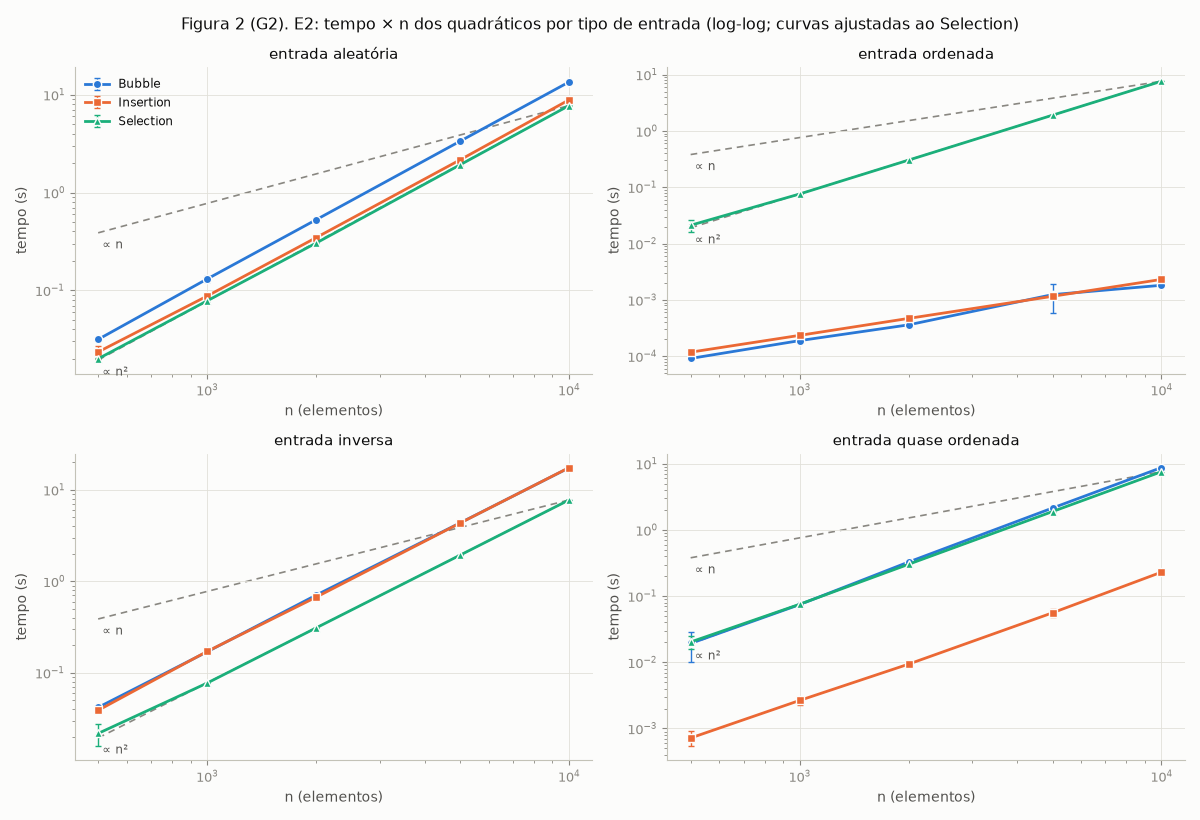

Na Figura 2, a curva do Selection Sort tem a mesma inclinação que $n^2$ nos quatro tipos de entrada, e seus tempos em $n = 10^4$ ficam entre 7,59 s e 7,75 s. Bubble e Insertion seguem $n^2$ nas entradas aleatória e inversa e passam a seguir $n$ na ordenada, em que ordenam $10^4$ elementos em 1,8 ms e 2,3 ms. Na quase ordenada, o Insertion Sort fica 33 a 38 vezes abaixo dos outros dois (0,23 s, contra 8,76 s do Bubble e 7,59 s do Selection em $n = 10^4$), mas sua curva continua paralela à de $n^2$. Na inversa, Bubble e Insertion levam mais que o dobro do tempo do Selection (17,4 s e 17,5 s, contra 7,75 s). Na aleatória, os tempos em $n = 10^4$ foram 13,5 s (Bubble), 8,9 s (Insertion) e 7,8 s (Selection).

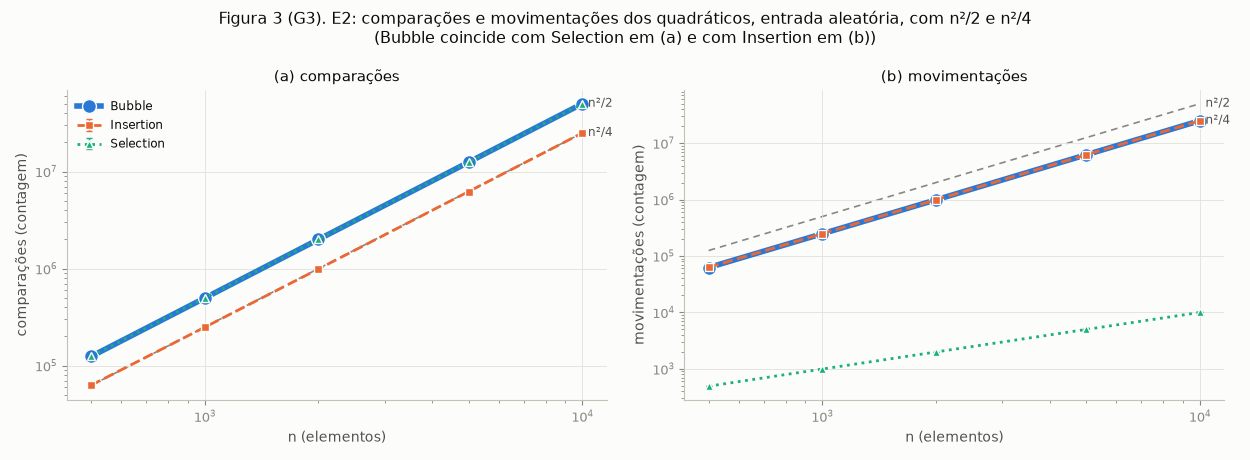

A Figura 3 compara as contagens com $n^2/2$ e $n^2/4$ na entrada aleatória. O Selection Sort faz exatamente $n(n-1)/2$ comparações ($0{,}5000\,n^2$ em $n = 10^4$) e cerca de $n$ trocas. O Bubble Sort faz praticamente o mesmo número de comparações ($0{,}4998\,n^2$), e o Insertion, metade ($0{,}2497\,n^2$). Em movimentações, Bubble e Insertion coincidem em torno de $n^2/4$ ($0{,}2496\,n^2$ e $0{,}2497\,n^2$). Nas entradas que não dependem da *seed*, as contagens são exatas: na ordenada, Bubble e Insertion fazem $n-1$ comparações e nenhuma movimentação; na inversa, os três fazem $n(n-1)/2$ comparações, o Bubble faz $n(n-1)/2$ trocas, o Insertion $n(n-1)/2 + (n-1)$ movimentações e o Selection apenas $n/2$ trocas.

### H.4.3 Algoritmos $O(n\log n)$ e Shellsort (E3)

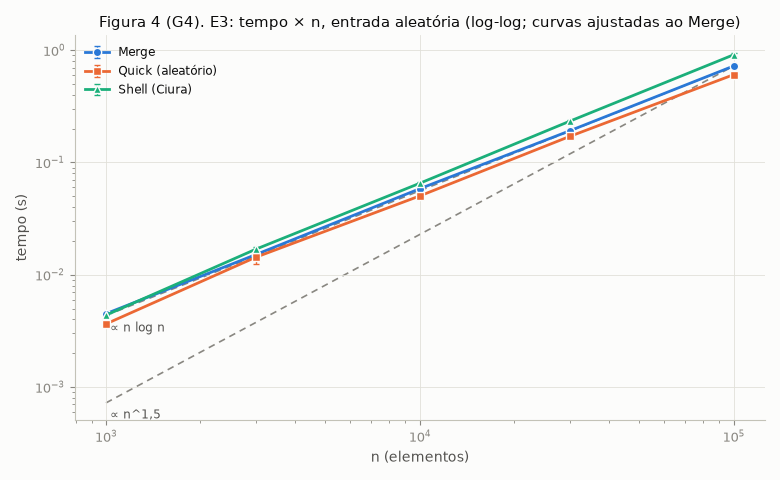

Na Figura 4 (entrada aleatória), as curvas de Merge e Quick aleatório acompanham a inclinação de $n\log n$; a do Shellsort com Ciura é um pouco mais inclinada, mas fica bem abaixo da de $n^{1{,}5}$. Em $n = 10^5$, o Quick aleatório levou 0,60 s, o Merge 0,72 s e o Shellsort 0,91 s.

**Tabela 2. E3: tempo médio (s) em $n = 10^5$, por tipo de entrada.**

| Algoritmo | aleatória | ordenada | inversa | quase ordenada |
|---|---:|---:|---:|---:|
| Shellsort (Shell) | 1,490 | 0,346 | 0,764 | 0,900 |
| Shellsort (Knuth) | 1,427 | 0,221 | 0,505 | 0,739 |
| Shellsort (Ciura) | 0,909 | 0,281 | 0,540 | 0,670 |
| Merge | 0,722 | 0,557 | 0,568 | 0,633 |
| Quick (aleatório) | 0,605 | 0,440 | 0,543 | 0,532 |
| Quick (mediana de 3) | 0,513 | 0,341 | 0,875 | 0,982 |
| Quick (último) | 0,543 | não concluídoᵃ | não concluídoᵇ | 3,591 |

ᵃ Interrompido após $n = 10^4$, em que levou 9,72 s. ᵇ Interrompido em $n = 3\cdot10^4$, em que a única execução levou 77,5 s (8,51 s em $n = 10^4$); ver Seção H.3.6.

Nenhum algoritmo foi o mais rápido em todos os tipos: na aleatória, o Quick com mediana de 3 (0,51 s); na ordenada e na inversa, o Shellsort com Knuth (0,22 s e 0,51 s); na quase ordenada, o Quick aleatório (0,53 s). O Merge Sort teve a menor variação entre tipos (0,56 s a 0,72 s). O Quick com mediana de 3, o mais rápido na aleatória, foi o mais lento na inversa entre os algoritmos que chegaram a $n = 10^5$ e o segundo mais lento na quase ordenada, com 3,2 milhões e 5,8 milhões de comparações, contra cerca de 2,0 milhões do Quick aleatório. O Quick com pivô no último elemento foi competitivo na aleatória (0,54 s), mas levou 3,59 s na quase ordenada, com 19,7 milhões de comparações.

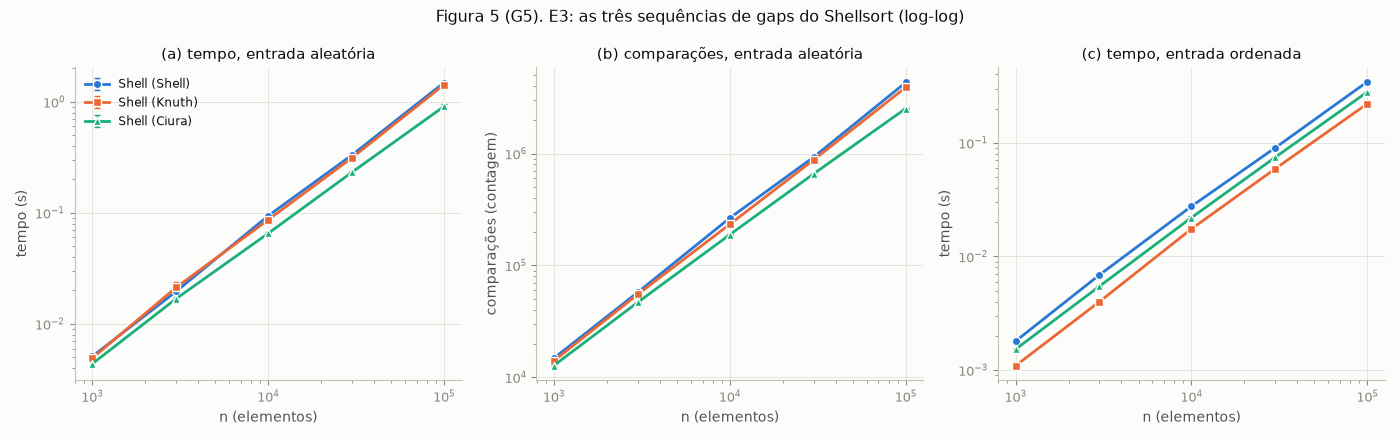

A Figura 5 compara as sequências de *gaps*. Na entrada aleatória, a de Ciura foi a melhor em tempo e em comparações: em $n = 10^5$, fez 2,53 milhões de comparações e levou 0,91 s, contra 3,91 milhões e 1,43 s da de Knuth e 4,32 milhões e 1,49 s da de Shell. Na entrada ordenada (c), a ordem muda e Knuth fica à frente (0,22 s, contra 0,28 s de Ciura e 0,35 s de Shell). Nessa entrada, o número de comparações coincide exatamente com $\sum_h (n - h)$ sobre os *gaps* usados: em $n = 10^5$, 955 719 para Knuth (10 *gaps*), 1 219 454 para Ciura (13 *gaps*) e 1 500 006 para Shell (16 *gaps*).

### H.4.4 Algoritmos lineares (E4)

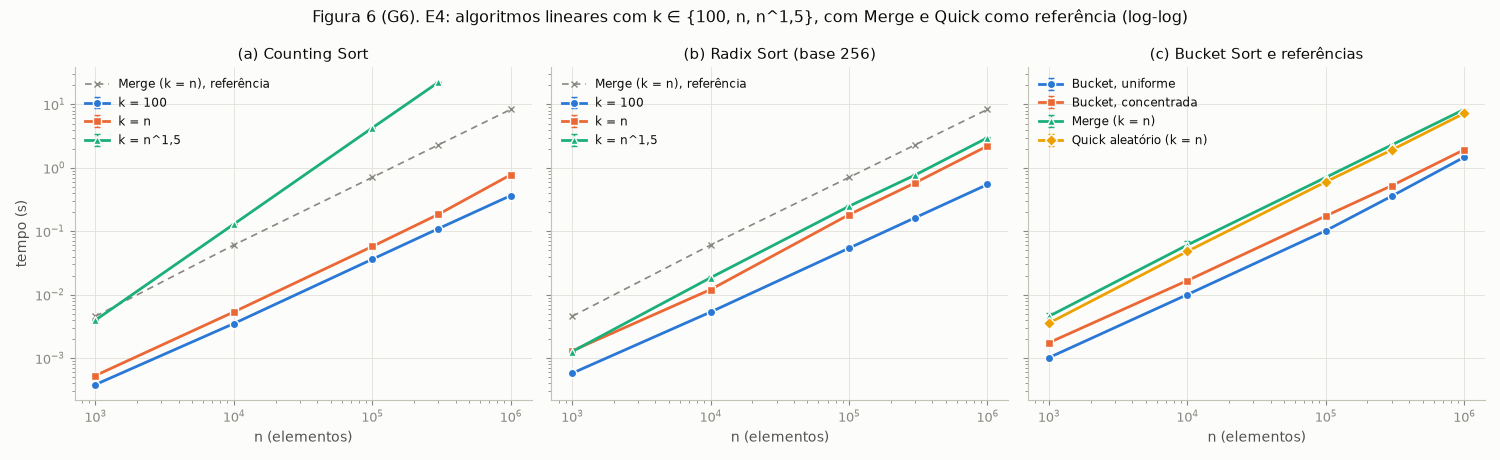

**(a) Counting Sort.** Com $k = 100$ e $k = n$, o tempo cresce linearmente, e $10^6$ elementos são ordenados em 0,37 s e 0,78 s. Com $k = n^{1{,}5}$, a inclinação fica próxima de 1,5: 4,3 s em $n = 10^5$ ($k \approx 3{,}2\cdot10^7$) e 22,3 s em $n = 3\cdot10^5$ ($k \approx 1{,}6\cdot10^8$), tamanho em que a combinação foi interrompida pelo limite de tempo. Nesses dois tamanhos, o Counting foi 6 e 10 vezes mais lento que o Merge Sort.

**(b) Radix Sort (base 256).** O tempo depende muito menos de $k$: em $n = 10^6$, foram 0,55 s com $k = 100$, 2,21 s com $k = n$ e 2,99 s com $k = n^{1{,}5}$. As movimentações registradas ($n$ por passada) mostram o número de passadas: 1 com $k = 100$; 2 com $k = n$ até $n = 10^4$ e 3 a partir de $10^5$; e 2, 3, 4, 4 e 4 com $k = n^{1{,}5}$.

**(c) Bucket Sort.** Foram 1,47 s para $10^6$ reais uniformes e 1,93 s para concentrados. A distribuição concentrada fez 6 vezes mais comparações (2,70 milhões, contra 0,45 milhão) e quase o dobro de movimentações; a razão entre os tempos caiu de 1,7 em $n = 10^3$ para 1,3 em $10^6$.

Em $n = 10^6$, as referências comparativas levaram 8,3 s (Merge) e 7,2 s (Quick aleatório), de 2,4 a 23 vezes o tempo dos lineares, com exceção do Counting com $k = n^{1{,}5}$.

### H.4.5 Estratégias de pivô do Quicksort (E5)

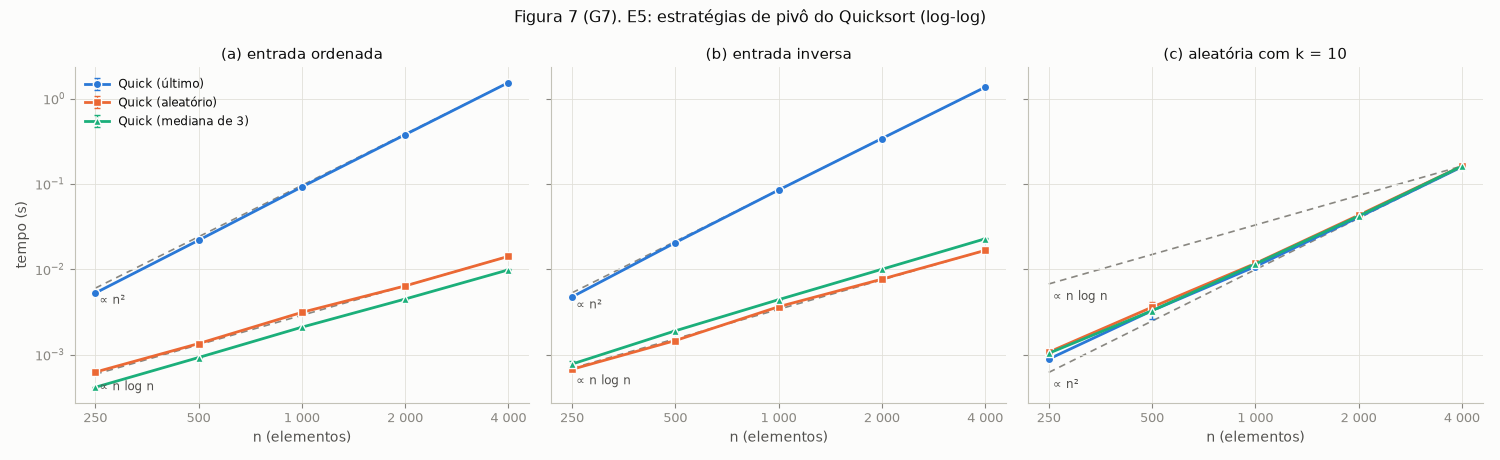

Nas entradas ordenada e inversa (Figuras 7a e 7b), o Quick com pivô no último elemento segue a curva $n^2$ e faz exatamente $n(n-1)/2$ comparações (7 998 000 em $n = 4\,000$), com 1,54 s e 1,36 s nesse tamanho. Os pivôs aleatório e mediana de 3 seguem $n\log n$ e ficam entre 9,9 ms e 22,8 ms; a mediana de 3 é a mais rápida na ordenada (9,9 ms, contra 14,2 ms do aleatório) e a mais lenta na inversa (22,8 ms, contra 16,7 ms). Com $k = 10$ (Figura 7c), as três estratégias têm praticamente o mesmo tempo (159 a 162 ms em $n = 4\,000$) e o mesmo número de comparações (de 814 mil a 826 mil), e as três curvas seguem $n^2$, não $n\log n$.

### H.4.6 Algoritmos quadráticos × $O(n\log n)$ em $n$ pequeno (E1)

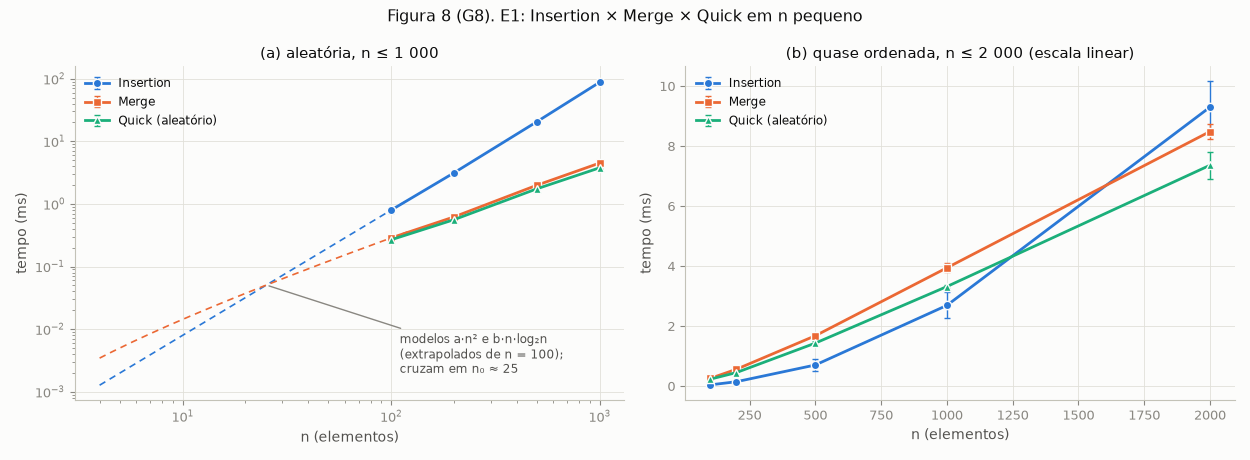

Na entrada aleatória (Figura 8a), o Insertion Sort já é o mais lento dos três no menor tamanho medido: em $n = 100$, levou 0,79 ms, contra 0,29 ms do Merge e 0,27 ms do Quick aleatório. Não há, portanto, cruzamento dentro da faixa do E1. As curvas tracejadas estendem para $n < 100$ os modelos $a\,n^2$ e $b\,n\log_2 n$ ajustados em $n = 100$, que se cruzam por volta de $n_0 \approx 25$ (Seção H.5.1). Na entrada quase ordenada (Figura 8b), o Insertion Sort foi o mais rápido até $n = 1\,000$ (2,7 ms, contra 3,3 ms do Quick e 3,9 ms do Merge) e o mais lento em $n = 2\,000$ (9,3 ms, contra 7,4 ms e 8,5 ms); pela interpolação linear, o cruzamento fica em $n \approx 1\,250$ com o Quick e $n \approx 1\,600$ com o Merge. Ainda em $n = 100$ na entrada aleatória, o comparativo mais rápido foi o Shellsort com Ciura (0,23 ms).

### H.4.7 Efeito da base no Radix Sort (E6)

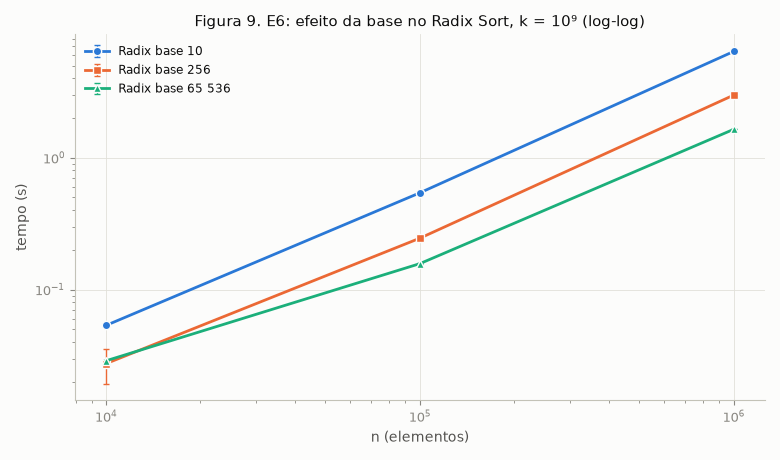

Com $k = 10^9$, o número de passadas foi 9 na base 10, 4 na base 256 e 2 na base 65 536. Em $n = 10^6$, os tempos foram 6,39 s, 2,98 s e 1,64 s, na mesma ordem do número de passadas. Em $n = 10^4$, a base 256 foi a mais rápida (27,4 ms, contra 28,8 ms da base 65 536 e 53,5 ms da base 10).

### H.4.8 Expoentes estimados (T1)

As Tabelas 3 e 4 trazem o expoente $\alpha$ de $T(n) \approx c\,n^\alpha$ estimado pelo ajuste log-log da Seção H.3.7, com $n \ge 1\,000$, calculado separadamente para cada experimento, como na célula T1 da Parte F. A célula de exemplo do enunciado agrupa por (algoritmo, tipo, $k$) e reúne os experimentos; como no E4 o valor de $k$ muda com $n$ nas configurações $k = n$ e $k = n^{1{,}5}$, ela não estima essas combinações.

**Tabela 3 (T1). $\alpha$ do tempo por tipo de entrada (E2 e E3).**

| Algoritmo (experimento) | aleatória | ordenada | inversa | quase ordenada | esperado |
|---|---:|---:|---:|---:|---|
| Bubble (E2) | 2,02 | 1,03 | 2,01 | 2,07 | 2; 1 na ordenada |
| Insertion (E2) | 2,01 | 0,99 | 2,01 | 1,94 | 2; 1 na ordenada |
| Selection (E2) | 2,00 | 2,00 | 2,00 | 2,00 | 2 |
| Shellsort, Shell (E3) | 1,23 | 1,14 | 1,14 | 1,25 | $\le 2$ |
| Shellsort, Knuth (E3) | 1,22 | 1,16 | 1,08 | 1,26 | $\le 1{,}5$ |
| Shellsort, Ciura (E3) | 1,16 | 1,13 | 1,12 | 1,21 | sem limite conhecido |
| Merge (E3) | 1,10 | 1,10 | 1,09 | 1,11 | $n\log n$: pouco acima de 1 |
| Quick, aleatório (E3) | 1,10 | 1,08 | 1,09 | 1,11 | $n\log n$ |
| Quick, mediana de 3 (E3) | 1,11 | 1,10 | 1,15 | 1,16 | $n\log n$ |
| Quick, último (E3) | 1,12 | 2,03ᵃ | 1,99ᵇ | 1,01 | $n\log n$; 2 na ordenada e na inversa |

ᵃ Três pontos ($n = 10^3$ a $10^4$). ᵇ Quatro pontos ($n = 10^3$ a $3\cdot10^4$), o último com uma única *seed*.

**Tabela 4 (T1). $\alpha$ do tempo nos experimentos E4 a E6.**

| Exp. | Algoritmo | Configuração | $\alpha$ | esperado |
|---|---|---|---:|---|
| E4 | Counting | $k = 100$ | 1,00 | 1 |
| E4 | Counting | $k = n$ | 1,05 | 1 |
| E4 | Counting | $k = n^{1{,}5}$ | 1,51 | 1,5 (o termo $k$ domina) |
| E4 | Radix | $k = 100$ | 0,99 | 1 |
| E4 | Radix | $k = n$ | 1,09 | 1 por passada; $d$ cresce com $\log_b n$ |
| E4 | Radix | $k = n^{1{,}5}$ | 1,12 | idem |
| E4 | Bucket | uniforme | 1,05 | 1 |
| E4 | Bucket | concentrada | 1,01 | 1 |
| E4 | Merge (referência) | $k = n$ | 1,09 | $n\log n$ |
| E4 | Quick aleatório (referência) | $k = n$ | 1,10 | $n\log n$ |
| E5 | Quick, último | ordenada / inversa | 2,03 / 2,00 | 2 |
| E5 | Quick, aleatório | ordenada / inversa | 1,09 / 1,10 | $n\log n$ |
| E5 | Quick, mediana de 3 | ordenada / inversa | 1,12 / 1,18 | $n\log n$ |
| E5 | Quick: último / aleatório / mediana de 3 | aleatória, $k = 10$ | 1,94 / 1,89 / 1,90 | ver Seção H.5.2 |
| E6 | Radix: base 10 / 256 / 65 536 | $k = 10^9$ | 1,04 / 1,02 / 0,88 | 1 |

Os quadráticos ficaram entre 2,00 e 2,07, exceto Bubble e Insertion na entrada ordenada (1,03 e 0,99). Merge e Quick (aleatório e mediana de 3) ficaram entre 1,08 e 1,18. O Shellsort ficou entre 1,08 e 1,26, sempre abaixo de 1,5. Os lineares ficaram entre 0,99 e 1,05 com $k$ fixo ou proporcional a $n$; o Counting com $k = n^{1{,}5}$ chegou a 1,51, e o Radix com $k = n$ e $k = n^{1{,}5}$ a 1,09 e 1,12. O único valor claramente abaixo de 1 foi o do Radix com base 65 536 no E6 (0,88). No E1, que não aparece nas tabelas, o Radix teve $\alpha$ entre 0,98 e 0,99, o Bucket entre 1,00 e 1,01 e o Counting entre 1,01 e 1,09.

### H.4.9 Razões $T(n)/g(n)$ (T2)

**Tabela 5 (T2). razões $T(n)/g(n)$; tempos em segundos.**

*(a) E3, entrada aleatória.*

| Algoritmo e razão | $n = 10^3$ | $3\cdot10^3$ | $10^4$ | $3\cdot10^4$ | $10^5$ |
|---|---:|---:|---:|---:|---:|
| Merge: tempo $/\,(n\log_2 n)$ [$10^{-7}$] | 4,51 | 4,36 | 4,39 | 4,28 | 4,35 |
| Merge: comparações $/\,(n\log_2 n)$ | 0,875 | 0,893 | 0,906 | 0,916 | 0,925 |
| Quick aleatório: tempo $/\,(n\log_2 n)$ [$10^{-7}$] | 3,66 | 4,13 | 3,79 | 3,82 | 3,64 |
| Quick aleatório: comparações $/\,(n\log_2 n)$ | 1,077 | 1,172 | 1,157 | 1,240 | 1,243 |
| Shellsort (Ciura): tempo $/\,(n\log_2 n)$ [$10^{-7}$] | 4,38 | 4,87 | 4,91 | 5,21 | 5,48 |
| Shellsort (Ciura): tempo $/\,n^{1{,}5}$ [$10^{-8}$] | 13,8 | 10,3 | 6,53 | 4,47 | 2,88 |

*(b) E2, entrada aleatória.*

| Algoritmo e razão | $n = 500$ | $10^3$ | $2\cdot10^3$ | $5\cdot10^3$ | $10^4$ |
|---|---:|---:|---:|---:|---:|
| Insertion: tempo $/\,n^2$ [$10^{-8}$] | 9,38 | 8,74 | 8,64 | 8,64 | 8,86 |
| Bubble: tempo $/\,n^2$ [$10^{-7}$] | 1,26 | 1,31 | 1,32 | 1,34 | 1,35 |
| Selection: comparações $/\,n^2$ | 0,4990 | 0,4995 | 0,4998 | 0,4999 | 0,5000 |

*(c) E4, entrada aleatória com $k = n$ (Counting) e uniforme (Bucket).*

| Algoritmo e razão | $n = 10^3$ | $10^4$ | $10^5$ | $3\cdot10^5$ | $10^6$ |
|---|---:|---:|---:|---:|---:|
| Counting: tempo $/\,n$ [$10^{-7}$] | 5,31 | 5,35 | 5,76 | 6,16 | 7,78 |
| Bucket: tempo $/\,n$ [$10^{-7}$] | 10,2 | 10,1 | 10,2 | 12,0 | 14,7 |

As razões do Insertion Sort ($n^2$, a partir de $n = 10^3$) e do Merge Sort ($n\log n$) ficaram estáveis, com variação de cerca de 3% ou menos. A do Quick aleatório oscila entre 3,64 e 4,13, sem tendência. As razões de comparações do Merge e do Quick crescem lentamente com $n$, de 0,875 a 0,925 e de 1,08 a 1,24. No Shellsort, a razão com $n\log n$ cresce 25% na faixa e a razão com $n^{1{,}5}$ cai quase cinco vezes. A razão do Bubble cresce 7% de $n = 500$ a $10^4$, e as do Counting e do Bucket crescem 35% e 44% entre $n = 10^5$ e $10^6$.

### H.4.10 Variabilidade das medições

O coeficiente de variação (desvio padrão dividido pela média) dos tempos entre *seeds* teve mediana entre 0,5% (E4 com $k = 100$) e 2,8% (E1), conforme o experimento. Nas entradas aleatórias, o coeficiente de variação das comparações teve mediana entre 0,09% (E2) e 2,4% (E3). Nas entradas ordenada e inversa, que não dependem da *seed*, as contagens foram idênticas nas cinco execuções em todos os algoritmos, inclusive no Quick aleatório (desvio padrão zero), de modo que toda a variação de tempo nessas entradas é ruído de medição. A maior distância entre uma execução e a mediana da sua combinação foi de 2,8 vezes, num tempo de décimos de milissegundo (Bubble em entrada quase ordenada, $n = 100$); nos tamanhos grandes, as execuções de uma mesma combinação ficaram, em geral, a poucos por cento umas das outras.

As contagens desta execução foram idênticas às da execução anterior, descartada (Seção H.3.6), em todas as combinações; os tempos medianos ficaram entre 3,1% menores e 0,5% maiores, conforme o experimento.

## H.5 Análise crítica

### H.5.1 Quadráticos × $O(n\log n)$ para $n$ pequeno

Em entrada aleatória, nenhum quadrático superou Merge ou Quick em nenhum tamanho medido: o cruzamento ocorre abaixo de $n = 100$, o menor tamanho do E1 (Figura 8a). Na entrada ordenada, Bubble e Insertion foram mais rápidos que todos os comparativos em todos os tamanhos (Tabela 1), e na quase ordenada o Insertion Sort venceu Merge e Quick até $n = 1\,000$, com cruzamento entre 1 250 e 1 600 (Figura 8b).

Os modelos $T_{ins}(n) \approx a\,n^2$ e $T_{merge}(n) \approx b\,n\log_2 n$, ajustados com os tempos de $n = 100$ na entrada aleatória, dão $a = 0{,}794\text{ ms}/100^2 \approx 7{,}9\cdot10^{-8}$ s e $b = 0{,}286\text{ ms}/(100\log_2 100) \approx 4{,}3\cdot10^{-7}$ s. Igualando os modelos, $n_0 = (b/a)\log_2 n_0 \approx 5{,}4\log_2 n_0$, cuja solução é $n_0 \approx 25$; com o Quick aleatório no lugar do Merge, $n_0 \approx 23$, e ajustando em $n = 200$ ou $500$ os valores ficam entre 20 e 25. A previsão é coerente com a observação de que o cruzamento ocorre abaixo de 100, mas o E1 não tem tamanhos menores para confirmá-la diretamente.

A origem das constantes fica clara quando o tempo é dividido pelo número de operações contadas (comparações mais movimentações). Na entrada aleatória, o custo por operação foi parecido em todos os comparativos: cerca de 155 ns no Selection, 180 ns no Insertion e no Bubble, 200 ns no Quick e 225 ns no Merge. Em Python instrumentado, cada operação é uma chamada de função, e esse custo domina. A constante oculta de cada algoritmo vem, portanto, principalmente do número de operações que ele faz: em $n = 100$, o Insertion faz cerca de $n^2/2 \approx 5\,000$ operações, e o Merge cerca de $1{,}9\,n\log_2 n \approx 1\,300$, além do custo das chamadas recursivas e das cópias para o vetor auxiliar. O mesmo raciocínio explica por que o Bubble Sort foi o mais lento na aleatória: ele faz $n^2/2$ comparações e $n^2/4$ trocas (cerca de $0{,}75\,n^2$ operações), contra $0{,}5\,n^2$ do Insertion, e a razão entre os tempos em $n = 10^4$ (1,52) é próxima de $0{,}75/0{,}5$.

Esse é o motivo pelo qual implementações reais, como o Timsort e o *introsort*, ordenam subvetores pequenos com Insertion Sort: abaixo de algumas dezenas de elementos, a menor quantidade de operações por elemento e a ausência de recursão compensam o crescimento quadrático. O Merge Sort híbrido com limiar $L$ (item opcional do enunciado) não foi implementado.

### H.5.2 Impacto da escolha do pivô no Quicksort

Com pivô no último elemento, as entradas ordenada e inversa levaram ao pior caso: $\alpha = 2{,}03$ e $1{,}99$ no E3 e $2{,}03$ e $2{,}00$ no E5, com exatamente $n(n-1)/2$ comparações em todos os tamanhos, inclusive nas 449 985 000 comparações da única execução em $n = 3\cdot10^4$ na inversa. É o comportamento da recorrência $T(n) = T(n-1) + \Theta(n)$: na ordenada, o pivô é sempre o máximo e uma das partes fica vazia; na inversa, o pivô é o mínimo, e a troca final leva o máximo para o fim do subvetor, de modo que as partições alternam entre mínimo e máximo, sempre com uma parte vazia. A entrada quase ordenada também prejudicou essa estratégia (3,59 s e 19,7 milhões de comparações em $n = 10^5$, contra 0,53 s e 2,0 milhões do pivô aleatório), embora com $\alpha \approx 1{,}01$: as comparações ficaram entre 150 e 200 por elemento em todos os tamanhos. Uma explicação plausível, não verificada, é que o pivô do fim é quase sempre um dos maiores valores do trecho, e o custo fica limitado pela distância média entre os elementos fora de lugar (da ordem de 50 posições, já que cerca de 2% deles foram trocados), que não depende de $n$.

Com o pivô aleatório, o pior caso continua possível, mas exige que o sorteio escolha um extremo do subvetor em praticamente todas as partições, e a probabilidade disso cai muito depressa com $n$. Os dois conceitos diferem na fonte da aleatoriedade. No caso médio sobre as entradas, o algoritmo é determinístico e a média é tomada sobre uma distribuição suposta para as entradas (por exemplo, todas as permutações igualmente prováveis); uma entrada ruim continua ruim. No tempo esperado sobre as escolhas do algoritmo, a garantia vale para qualquer entrada fixa, e a média é sobre os sorteios internos. Os dados confirmam a análise do caso esperado: as comparações do Quick aleatório ficaram a até 2,3% do valor teórico $2(n+1)H_n - 4n$ (10 736 contra 10 986 em $n = 10^3$; 153 695 contra 155 772 em $10^4$; 2 063 943 contra 2 018 053 em $10^5$). Como a semente do pivô é fixa (0), cada entrada sempre recebe a mesma sequência de pivôs; quem conhecesse a semente poderia construir uma entrada de pior caso.

Com $k = 10$, as três estratégias degradaram igualmente ($\alpha$ entre 1,89 e 1,94 no tempo e entre 1,93 e 1,96 nas comparações). A causa é a partição de Lomuto com $\le$: os elementos iguais ao pivô vão todos para a esquerda, de modo que um subvetor formado só por cópias de um mesmo valor é particionado com uma parte vazia a cada passo. Com $k$ valores distintos, cada valor tem cerca de $n/k$ cópias, e o custo total fica em torno de $k\cdot(n/k)^2/2 = n^2/(2k)$. Para $k = 10$ e $n = 4\,000$, isso dá 800 000 comparações; foram medidas de 814 mil a 826 mil. Nenhuma estratégia de pivô ajuda, porque dentro desses blocos todos os candidatos têm o mesmo valor; a solução seria a partição de três vias de Dijkstra (SEDGEWICK; WAYNE, 2011), que não foi implementada.

Não houve diferença sistemática de desvio padrão entre as estratégias. Nas entradas ordenada e inversa, que são iguais para todas as *seeds*, as contagens tiveram desvio zero nas três estratégias, inclusive na aleatória (por causa da semente fixa), e os coeficientes de variação do tempo, de 0,1% a 8%, são apenas ruído de medição. Com $k = 10$, a variação vem das diferentes entradas e é parecida nas três.

### H.5.3 Efeito da sequência de *gaps* no Shellsort

Na entrada aleatória, a sequência de Ciura foi a melhor em tempo e em comparações (0,91 s e 2,53 milhões em $n = 10^5$), seguida de Knuth (1,43 s e 3,91 milhões) e de Shell (1,49 s e 4,32 milhões), com $\alpha$ de 1,16, 1,22 e 1,23. É o resultado esperado: Ciura obteve seus incrementos por busca experimental, escolhendo os que minimizam o número médio de comparações em permutações aleatórias (CIURA, 2001), e é por esse desempenho médio que ela é a versão principal deste trabalho. Uma interpretação usual é a razão entre *gaps* consecutivos, de cerca de 2,25 em Ciura, contra 3 em Knuth e 2 em Shell: com razão 2, *gaps* consecutivos compartilham o fator 2, e parte de cada passada repete comparações da anterior; com razão 3, cada passada recebe um vetor menos preparado pela anterior. Essa explicação é qualitativa e não foi testada aqui.

Nas entradas ordenada e inversa, Knuth foi a mais rápida. Na ordenada, isso se explica pelo número de *gaps*: cada passada custa exatamente $n - h$ comparações, e a sequência de Knuth, limitada a $h < n/3$, usa 10 *gaps*, contra 13 de Ciura (estendida até perto de $n$) e 16 de Shell. As contagens medidas coincidem com $\sum_h (n-h)$ (Seção H.4.3).

Os resultados são compatíveis com os limites conhecidos. Para Knuth, $\alpha = 1{,}22$ fica abaixo de $3/2$, como esperado de um limite superior $O(n^{3/2})$. Para Shell, $\alpha = 1{,}23$ está longe de 2, o que também é esperado: o pior caso $\Theta(n^2)$ dessa sequência exige $n$ potência de 2 e uma entrada específica (Seção H.2.3), e os experimentos usam entradas aleatórias e tamanhos que não são potências de 2. A razão $T(n)/(n\log n)$ do Shellsort com Ciura cresce lentamente e a razão $T(n)/n^{1{,}5}$ diminui (Tabela 5a), o que situa seu crescimento entre $n\log n$ e $n^{1{,}5}$ na faixa medida.

O Shellsort foi competitivo com Merge e Quick. Na entrada aleatória, a versão de Ciura foi 1,3 a 1,5 vez mais lenta que os dois em $n = 10^5$, e a diferença tende a crescer com $n$, já que seu $\alpha$ é maior. Na entrada ordenada, as sequências de Knuth e Ciura foram mais rápidas que Merge e Quick aleatório em todos os tamanhos do E3, e na inversa a partir de $n = 10^4$; na quase ordenada, a de Ciura ficou entre o Merge e o Quick com mediana de 3 (Tabela 2).

### H.5.4 Quando os algoritmos lineares são vantajosos

**Counting Sort e o valor de $k$.** Com $k = 100$ e $k = n$, o Counting Sort foi linear ($\alpha$ = 1,00 e 1,05) e o mais rápido de todos os algoritmos. Com $k = n^{1{,}5}$, o termo $k$ de $\Theta(n + k)$ domina desde o primeiro tamanho: em $n = 10^3$, $k \approx 32\,n$ e o tempo já é 7,5 vezes o do caso $k = n$; o $\alpha$ medido (1,51) é o do próprio $k$. Em $n = 3\cdot10^5$, o vetor de contagem tem $1{,}6\cdot10^8$ posições. Em CPython, uma lista ocupa 8 bytes por posição (cerca de 1,3 GB), e depois das somas prefixas cada posição aponta para um inteiro próprio, de modo que a memória necessária chega a alguns gigabytes. Essa é uma estimativa: a memória não foi medida e não houve erro de memória. Em $n = 10^6$ ($k = 10^9$), seriam necessárias dezenas de gigabytes, mais do que os 16 GB da máquina; o limite de tempo interrompeu a combinação antes dessa tentativa.

**Radix Sort.** O Radix foi muito menos afetado por $k$ porque seu custo cresce com o número de passadas, $d = \lfloor\log_b(M-m)\rfloor + 1$, e não com $k$. Em $n = 10^6$, os tempos de 0,55 s, 2,21 s e 2,99 s correspondem a 1, 3 e 4 passadas, ou seja, de 0,55 a 0,75 µs por elemento e por passada. Com $k = n$, $d$ cresce com $\log_{256} n$, e isso explica por que $T(n)/n$ do Radix aumenta com $n$ (Figura 6b). No E6, a base 65 536 foi a melhor nos tamanhos grandes (2 passadas), e a base 10 a pior (9 passadas). Em $n = 10^4$, a base 256 venceu a de 65 536 porque o vetor de contagem desta tem 65 536 posições por passada, mais do que os $10^4$ elementos: o termo $b$ de $\Theta(d(n+b))$ passa a pesar, e é também por isso que o $\alpha$ da base 65 536 ficou em 0,88. Isso é coerente com o resultado clássico de que a melhor base fica próxima de $n$.

**Bucket Sort.** Com distribuição uniforme, o Bucket Sort foi linear ($\alpha = 1{,}05$), como prevê a análise $\Theta(n)$ do caso médio. Com a distribuição concentrada, o $\alpha$ foi 1,01, e o algoritmo continuou linear, apenas com uma constante maior (1,3 a 1,7 vez o tempo, 6 vezes as comparações). A teoria também prevê esse resultado, porque a distribuição concentrada usada coloca 90% dos valores em 10% dos baldes, com cerca de 9 elementos por balde em média, número que não cresce com $n$. O pior caso $\Theta(n^2)$ exige que uma fração crescente dos elementos caia no mesmo balde, situação que os experimentos não testaram.

**Lineares × Merge e Quick em Python.** Para $n$ grande, os lineares foram de fato mais rápidos: em $n = 10^6$, o Counting ($k = n$) levou 0,78 s, o Bucket uniforme 1,47 s e o Radix 2,21 s, contra 7,2 s do Quick aleatório e 8,3 s do Merge. A exceção foi o Counting com $k$ muito maior que $n$, até 10 vezes mais lento que o Merge. Três fatores pesam nessa comparação. A instrumentação penaliza mais os comparativos, que fazem uma chamada de função por comparação e por movimentação, enquanto boa parte do trabalho dos lineares (contagem, somas prefixas, cálculo dos dígitos) não é instrumentada. A alocação de memória pesa nos lineares quando $k$ ou $n$ crescem: o tempo por elemento do Counting e do Bucket aumentou 35% e 44% entre $10^5$ e $10^6$, possivelmente por efeitos de cache e de memória. E "linear" pressupõe hipóteses sobre a entrada (inteiros num intervalo limitado, dígitos, distribuição uniforme) que, quando violadas, anulam a vantagem, como no caso $k = n^{1{,}5}$.

**Comparações entre comparativos e não comparativos.** Counting e Radix fazem zero comparações, mas leem e escrevem cada elemento várias vezes e percorrem o vetor de contagem, e nada disso entra em `comp`. Por isso, o número de comparações não serve para comparar os dois grupos. Métricas mais justas são o tempo, as movimentações, que os dois grupos têm, ou uma contagem de todas as operações elementares, incluindo os acessos por índice.

### H.5.5 Teoria × prática

**Expoentes.** Os expoentes ficaram próximos dos esperados na maioria dos casos (Tabelas 3 e 4): 2,00 a 2,07 nos quadráticos, 0,99 a 1,03 em Bubble e Insertion na entrada ordenada, 1,08 a 1,11 em Merge e Quick aleatório (o esperado para $n\log n$ na faixa de $10^3$ a $10^5$ é cerca de $1 + 1/\ln n \approx 1{,}1$) e cerca de 1 nos lineares sob suas hipóteses. As maiores discrepâncias foram estas:

- Na entrada quase ordenada, Bubble e Insertion tiveram $\alpha \approx 2$. O gerador troca cerca de $n/100$ pares de posições sorteadas, a uma distância média de $n/3$; cada troca cria cerca de $2n/3$ inversões, e o total fica em torno de $n^2/150$. As comparações do Insertion em $n = 10^4$ (652 828, cerca de $n^2/153$) confirmam essa conta. Com essa definição, a entrada quase ordenada continua $\Theta(n^2)$ para Bubble e Insertion, com uma constante cerca de 38 vezes menor no Insertion.
- O Radix com base 65 536 teve $\alpha = 0{,}88$ no E6. Até $n = 10^4$, o vetor de contagem dessa base é maior que o número de elementos, e o custo inicial não é proporcional a $n$ (Seção H.5.4).
- O Radix com $k = n$ e $k = n^{1{,}5}$ teve $\alpha$ de 1,09 e 1,12. Nessas configurações o número de passadas cresce com $n$, e o custo passa a ser $\Theta(n \log_b n)$.
- O tempo por elemento do Counting e do Bucket cresceu a partir de $10^5$ (Tabela 5c), e o do Bubble, mais devagar (Tabela 5b). A explicação mais provável são efeitos de memória e de cache (o processador tem 25 MB de cache L3, e uma lista de $10^6$ referências já ocupa 8 MB), mas esse ponto não foi medido.
- As razões de comparações do Merge e do Quick crescem lentamente (Tabela 5a), como esperado: $2(n+1)H_n - 4n \approx 1{,}39\,n\log_2 n - O(n)$, e o termo negativo de ordem $n$ faz a razão subir devagar em direção a 1,39; no Merge, a razão sobe em direção a 1 pelo mesmo motivo.

**Contagens × tempo.** As contagens foram muito mais estáveis que o tempo: são determinísticas para uma dada entrada (desvio zero nas entradas ordenada e inversa e valores idênticos nas duas execuções completas), enquanto o tempo inclui ruído do sistema operacional, do cache e da memória e variou até cerca de 3% entre as duas execuções. Para validar a análise assintótica, as contagens são a melhor métrica: várias delas reproduziram fórmulas fechadas exatamente ($n(n-1)/2$, $\sum_h (n-h)$) ou quase ($n^2/(2k)$, $2(n+1)H_n - 4n$). Para escolher um algoritmo num sistema real, o tempo é mais informativo, porque inclui o que as contagens ignoram: o custo de cada operação, a alocação de memória e o trabalho não contado. Um exemplo: em $n = 10^5$, o Quick aleatório fez 34% mais comparações que o Merge, mas foi 16% mais rápido, porque fez menos movimentações (1,0 milhão contra 1,7 milhão) e não copia para um vetor auxiliar.

**Tabela 6. Recomendações por cenário, com base nos dados.**

| Cenário | Escolha | Justificativa |
|---|---|---|
| $n$ pequeno | Insertion Sort até algumas dezenas de elementos; Shellsort (Ciura) por volta de $n = 100$ | $n_0$ estimado entre 23 e 25; em $n = 100$, o Shellsort foi o comparativo mais rápido (Seção H.4.6) |
| Dados quase ordenados | Insertion Sort se as inversões forem poucas e locais; senão, Quick aleatório ou Shellsort | linear na entrada ordenada; com inversões a longa distância, só compensa até $n \approx 10^3$ |
| Estabilidade necessária | Merge Sort; Counting ou Radix para inteiros | estáveis por construção (testes da Seção H.3.3) e $\Theta(n\log n)$ ou linear |
| Pouca memória extra | Shellsort ou Quicksort (aleatório) | *in-place*; pilha $O(\log n)$ no Quick; competitivos com o Merge (Tabela 2) |
| Inteiros em intervalo pequeno | Counting Sort ($k \lesssim n$); Radix com base grande para $k$ grande | os mais rápidos do trabalho; Radix pouco sensível a $k$ (Figura 6) |
| Pior caso garantido | Merge Sort | $\Theta(n\log n)$ em qualquer entrada, menor variação entre tipos (de 0,56 a 0,72 s em $10^5$) |

### H.5.6 Confronto com as previsões

As previsões da Parte E se confirmaram em parte. Na entrada aleatória, os mais rápidos foram de fato os lineares, seguidos de Quick e Merge, e o mais lento foi o Bubble; mas o segundo mais lento foi o Insertion (2,19 s em $n = 5\,000$), e não o Selection (1,90 s): os dois fazem cerca de $n^2/2$ operações, mas as do Selection são quase todas comparações, que custaram menos (cerca de 155 ns, contra 180 ns). Na entrada ordenada, Bubble e Insertion foram os mais rápidos e o Selection o mais lento, como previsto. Na entrada quase ordenada, a previsão de comportamento linear para Bubble e Insertion não se confirmou: o Bubble levou praticamente o mesmo tempo que na aleatória, e o Insertion, embora muito mais rápido, perdeu para todos os subquadráticos a partir de algum $n$ entre 1 000 e 2 000, ambos com $\alpha \approx 2$ (Seção H.5.5). Na entrada inversa, a previsão de que Merge e Quick seriam os mais rápidos não se confirmou: os lineares e o Shellsort com Ciura foram mais rápidos que os dois. Quanto aos expoentes, os quadráticos e os $n\log n$ ficaram na faixa prevista (2 e de 1,05 a 1,15), enquanto o Shellsort com Ciura ficou no limite inferior dela ou abaixo (de 1,12 a 1,21, contra 1,20 a 1,33 previstos). O efeito de $k$ no Counting Sort e o crescimento do número de passadas do Radix com $n$ não estavam nas previsões.

### H.5.7 Limitações

- Os experimentos rodaram numa única máquina, com uma versão do Python e uma execução por *seed*; a média de 5 execuções é sensível a valores isolados.
- O E1 começa em $n = 100$, abaixo do qual estaria o cruzamento na entrada aleatória; o E3 não incluiu os tamanhos opcionais ($3\cdot10^5$ e $10^6$); o Quick com pivô no último elemento tem três pontos na entrada ordenada e quatro na inversa, o último com uma única *seed*, e o Counting com $k = n^{1{,}5}$ tem quatro, também com o último de uma *seed*.
- A entrada quase ordenada tem $\Theta(n^2)$ inversões e não representa o cenário de poucas inversões locais; a distribuição concentrada não é um pior caso do Bucket Sort; nenhum tamanho é potência de 2 e nenhuma entrada foi construída para o pior caso da sequência de Shell.
- Como a semente do pivô aleatório é fixa, a variação devida às escolhas de pivô não foi amostrada; todas as diferenças entre *seeds* vêm das entradas.
- O consumo de memória não foi medido; os valores citados na Seção H.5.4 são estimativas.
- O Merge Sort híbrido com Insertion Sort (opcional) e a partição de três vias do Quicksort não foram implementados.

## H.6 Conclusões

Os experimentos confirmaram as classes de complexidade previstas pela teoria. Os quadráticos tiveram expoentes entre 2,00 e 2,07, os algoritmos $n\log n$ entre 1,08 e 1,11 nas versões principais, e os lineares cerca de 1 quando suas hipóteses foram respeitadas. As contagens de operações reproduziram fórmulas fechadas: $n(n-1)/2$ comparações no Selection Sort e no pior caso do Quicksort, $\sum_h(n-h)$ no Shellsort em vetor ordenado, cerca de $n^2/(2k)$ no Quicksort com valores repetidos e o valor esperado $2(n+1)H_n - 4n$ do Quicksort aleatório, a menos de 2,3%.

Retomando as perguntas da introdução:

1. Os tempos e as contagens seguiram as classes previstas; os expoentes estimados concordaram com os esperados, e as principais exceções têm causa identificada (definição da entrada quase ordenada e número de passadas e termo $b$ do Radix).
2. Em entrada aleatória, os quadráticos só seriam mais rápidos abaixo de $n_0$ entre 23 e 25, segundo os modelos ajustados; em entrada quase ordenada, o Insertion Sort venceu Merge e Quick até $n$ entre 1 250 e 1 600. As constantes ocultas vêm principalmente do número de operações por elemento, já que o custo de cada operação instrumentada é parecido entre os algoritmos.
3. O pivô no último elemento leva a $\Theta(n^2)$ em entradas ordenadas e inversas; o pivô aleatório e a mediana de 3 evitam esse caso; e nenhuma estratégia resolve os valores repetidos com a partição de Lomuto.
4. A sequência de Ciura foi a melhor em entrada aleatória, e a de Knuth nas entradas ordenada e inversa; a de Shell foi a pior em quase todos os casos.
5. Os lineares compensam quando suas hipóteses valem: foram de 2,4 a 23 vezes mais rápidos que Merge e Quick em $n = 10^6$, mas o Counting Sort com $k = n^{1{,}5}$ ficou até 10 vezes mais lento que o Merge e exigiria memória além da disponível.
6. Contagens e tempo não são equivalentes: as contagens são a métrica certa para validar a análise assintótica, e o tempo, para escolher um algoritmo na prática.

Na prática, para uso geral, o Quicksort com pivô aleatório e o Merge Sort são as escolhas mais seguras entre os comparativos, o segundo quando estabilidade ou pior caso garantido importam. O Insertion Sort só compensa em vetores muito pequenos ou com poucas inversões, e os lineares devem ser usados quando as chaves são inteiros num intervalo conhecido, com o Radix de base grande para intervalos maiores.

Como trabalhos futuros, ficam: o Heapsort, que garante $O(n\log n)$ *in-place*; o Merge Sort híbrido com Insertion Sort e a partição de três vias do Quicksort; a comparação com o Timsort do próprio Python; a medição do consumo de memória; mais repetições por *seed* e o uso da mediana; sementes variáveis no pivô aleatório; tamanhos potência de 2 e entradas de pior caso para o Shellsort; e a repetição dos experimentos sem instrumentação ou em uma linguagem compilada.

## Referências

CIURA, M. Best increments for the average case of Shellsort. In: FREIVALDS, R. (ed.). **Fundamentals of Computation Theory (FCT 2001)**. Berlin: Springer, 2001. p. 106–117. (Lecture Notes in Computer Science, v. 2138).

CORMEN, T. H.; LEISERSON, C. E.; RIVEST, R. L.; STEIN, C. **Algoritmos: teoria e prática**. 3. ed. Rio de Janeiro: Elsevier, 2012.

HOARE, C. A. R. Quicksort. **The Computer Journal**, Oxford, v. 5, n. 1, p. 10–16, 1962.

KNUTH, D. E. **The art of computer programming, volume 3: sorting and searching**. 2. ed. Reading: Addison-Wesley, 1998.

PRATT, V. R. **Shellsort and sorting networks**. New York: Garland, 1979.

SEDGEWICK, R.; WAYNE, K. **Algorithms**. 4. ed. Upper Saddle River: Addison-Wesley, 2011.

SHELL, D. L. A high-speed sorting procedure. **Communications of the ACM**, New York, v. 2, n. 7, p. 30–32, 1959.

ZIVIANI, N. **Projeto de algoritmos: com implementações em Java e C++**. São Paulo: Thomson Learning, 2007.